In [1]:
# ============================================================
# CELL 1 — MENTALBERT + SELECTIVE CLEANING
# FRESH EXPERIMENT START
# ============================================================

import os
import re
import gc
import json
import html
import random
import warnings

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")


# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# EXPERIMENT CONFIGURATION
# ============================================================

MODEL_NAME = "mental/mental-bert-base-uncased"

EXPERIMENT_NAME = (
    "MentalBERT + Selective Cleaning"
)

CLEANING_METHOD = (
    "Selective cleaning after diagnostic anchor removal"
)

MAX_LENGTH = 512
METADATA_DIM = 53


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

BASE_RESULT_DIR = (
    "/kaggle/working/"
    "mentalbert_selective"
)

RESULT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "results"
)

CHECKPOINT_DIR = os.path.join(
    BASE_RESULT_DIR,
    "checkpoints"
)

BACKUP_DIR = os.path.join(
    BASE_RESULT_DIR,
    "backup"
)

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    BACKUP_DIR,
    exist_ok=True
)


# ============================================================
# SELECTIVE CLEANING POLICY
# ============================================================

SELECTIVE_POLICY = [

    "Remove standard URLs",

    "Remove malformed URL variants",

    "Remove user mentions",

    "Remove hashtag symbol while retaining hashtag text",

    "Decode HTML entities",

    "Preserve normal wording",

    "Preserve punctuation",

    "Preserve digits",

    "Preserve emojis and expressive symbols",

    "Preserve repeated-character patterns",

    "Preserve RT text",

    "Lowercase text",

    "Normalize whitespace"
]


# ============================================================
# PRINT CONFIGURATION
# ============================================================

print("=" * 60)
print("MENTALBERT + SELECTIVE CLEANING")
print("=" * 60)

print()

print(
    "Device:",
    device
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "CUDA:",
        torch.version.cuda
    )

print()

print(
    "Model:",
    MODEL_NAME
)

print(
    "Cleaning:",
    CLEANING_METHOD
)

print(
    "Context length:",
    MAX_LENGTH
)

print(
    "Metadata features:",
    METADATA_DIM
)

print(
    "Seed:",
    SEED
)


# ============================================================
# PRINT CLEANING POLICY
# ============================================================

print()
print("=" * 60)
print("SELECTIVE CLEANING POLICY")
print("=" * 60)

for i, rule in enumerate(
    SELECTIVE_POLICY,
    start=1
):

    print(
        f"{i:02d}. {rule}"
    )


# ============================================================
# FIXED EXPERIMENT CONTROLS
# ============================================================

FIXED_CONTROLS = {

    "user_level_split": True,

    "train_users": 6135,

    "validation_users": 767,

    "test_users": 767,

    "diagnostic_anchor_removal": True,

    "metadata_features": 53,

    "metadata_scaling":
        "TRAIN ONLY",

    "training_balance":
        "2013 negative + 2013 positive",

    "batch_size": 16,

    "context_length": 512,

    "random_seed": 42,

    "checkpoint_metric":
        "Validation F1",

    "early_stopping_patience": 2,

    "maximum_epochs": 10
}


# ============================================================
# SAVE EXPERIMENT CONFIG
# ============================================================

experiment_config = {

    "experiment_name":
        EXPERIMENT_NAME,

    "model_name":
        MODEL_NAME,

    "cleaning_method":
        CLEANING_METHOD,

    "context_length":
        MAX_LENGTH,

    "metadata_dimension":
        METADATA_DIM,

    "seed":
        SEED,

    "selective_policy":
        SELECTIVE_POLICY,

    "fixed_controls":
        FIXED_CONTROLS
}


config_path = os.path.join(
    RESULT_DIR,
    "experiment_config.json"
)

with open(
    config_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        experiment_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print("✓ MentalBERT selected")
print("✓ Selective cleaning selected")
print("✓ Context length = 512")
print("✓ Metadata dimension = 53")
print("✓ Seed = 42")
print("✓ Selective cleaning policy defined")
print("✓ Result directory created")
print("✓ Checkpoint directory created")
print("✓ Backup directory created")
print("✓ Experiment configuration saved")
print("✓ RAW outputs untouched")
print("✓ Aggressive outputs untouched")
print("✓ Emotion-Based outputs untouched")
print("✓ Fixed experiment controls recorded")

MENTALBERT + SELECTIVE CLEANING

Device: cuda
GPU: Tesla T4
CUDA: 12.8

Model: mental/mental-bert-base-uncased
Cleaning: Selective cleaning after diagnostic anchor removal
Context length: 512
Metadata features: 53
Seed: 42

SELECTIVE CLEANING POLICY
01. Remove standard URLs
02. Remove malformed URL variants
03. Remove user mentions
04. Remove hashtag symbol while retaining hashtag text
05. Decode HTML entities
06. Preserve normal wording
07. Preserve punctuation
08. Preserve digits
09. Preserve emojis and expressive symbols
10. Preserve repeated-character patterns
11. Preserve RT text
12. Lowercase text
13. Normalize whitespace

CELL 1 COMPLETE
✓ MentalBERT selected
✓ Selective cleaning selected
✓ Context length = 512
✓ Metadata dimension = 53
✓ Seed = 42
✓ Selective cleaning policy defined
✓ Result directory created
✓ Checkpoint directory created
✓ Backup directory created
✓ Experiment configuration saved
✓ RAW outputs untouched
✓ Aggressive outputs untouched
✓ Emotion-Based outputs u

In [2]:
# ============================================================
# CELL 2 — MENTALBERT SELECTIVE
# LOADING EXACT USER-LEVEL SPLIT
# ============================================================

print("=" * 60)
print("MENTALBERT SELECTIVE — LOADING EXACT USER-LEVEL SPLIT")
print("=" * 60)


# ============================================================
# SPLIT PATHS
# ============================================================

SPLIT_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "mddl-experiment-1-splits"
)

TRAIN_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_train_raw.pkl"
)

VAL_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_val_raw.pkl"
)

TEST_PATH = os.path.join(
    SPLIT_ROOT,
    "MDDL_test_raw.pkl"
)


print()
print("TRAIN:", TRAIN_PATH)
print("VAL:  ", VAL_PATH)
print("TEST: ", TEST_PATH)


# ============================================================
# FILE CHECK
# ============================================================

assert os.path.exists(TRAIN_PATH), (
    f"TRAIN split not found: {TRAIN_PATH}"
)

assert os.path.exists(VAL_PATH), (
    f"VALIDATION split not found: {VAL_PATH}"
)

assert os.path.exists(TEST_PATH), (
    f"TEST split not found: {TEST_PATH}"
)

print()
print("✓ All split files found")


# ============================================================
# LOAD SPLITS
# ============================================================

print()
print("Loading TRAIN...")

train_df = pd.read_pickle(
    TRAIN_PATH
)

print("Loading VALIDATION...")

val_df = pd.read_pickle(
    VAL_PATH
)

print("Loading TEST...")

test_df = pd.read_pickle(
    TEST_PATH
)


# ============================================================
# SPLIT SHAPES
# ============================================================

print()
print("=" * 60)
print("SPLIT SHAPES")
print("=" * 60)

print(
    "Train:",
    train_df.shape
)

print(
    "Validation:",
    val_df.shape
)

print(
    "Test:",
    test_df.shape
)

assert train_df.shape == (
    6135,
    82
)

assert val_df.shape == (
    767,
    82
)

assert test_df.shape == (
    767,
    82
)


# ============================================================
# REQUIRED COLUMN CHECK
# ============================================================

print()
print("=" * 60)
print("REQUIRED COLUMN CHECK")
print("=" * 60)

required_columns = [
    "user_id",
    "username",
    "label",
    "timeline_text"
]

for column in required_columns:

    assert column in train_df.columns, (
        f"{column} missing from TRAIN"
    )

    assert column in val_df.columns, (
        f"{column} missing from VALIDATION"
    )

    assert column in test_df.columns, (
        f"{column} missing from TEST"
    )

    print(
        f"✓ {column}"
    )


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)

train_users = set(
    train_df["user_id"]
)

val_users = set(
    val_df["user_id"]
)

test_users = set(
    test_df["user_id"]
)


print(
    "Train unique users:",
    train_df["user_id"].nunique()
)

print(
    "Validation unique users:",
    val_df["user_id"].nunique()
)

print(
    "Test unique users:",
    test_df["user_id"].nunique()
)


# No duplicate users inside a split
assert train_df["user_id"].is_unique
assert val_df["user_id"].is_unique
assert test_df["user_id"].is_unique


# Cross-split overlap
train_val_overlap = (
    train_users
    & val_users
)

train_test_overlap = (
    train_users
    & test_users
)

val_test_overlap = (
    val_users
    & test_users
)


print(
    "TRAIN ↔ VAL:",
    len(train_val_overlap)
)

print(
    "TRAIN ↔ TEST:",
    len(train_test_overlap)
)

print(
    "VAL ↔ TEST:",
    len(val_test_overlap)
)


assert len(train_val_overlap) == 0
assert len(train_test_overlap) == 0
assert len(val_test_overlap) == 0


print()
print("✓ No duplicate users")
print("✓ No cross-split overlap")


# ============================================================
# LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)


print()
print("TRAIN:")

print(
    train_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


print()
print("VALIDATION:")

print(
    val_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


print()
print("TEST:")

print(
    test_df[
        "label"
    ]
    .value_counts()
    .sort_index()
)


# ============================================================
# EXACT LABEL CHECK
# ============================================================

train_distribution = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
)

val_distribution = (
    val_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
)

test_distribution = (
    test_df["label"]
    .value_counts()
    .sort_index()
    .to_dict()
)


assert train_distribution == {
    0: 4122,
    1: 2013
}

assert val_distribution == {
    0: 515,
    1: 252
}

assert test_distribution == {
    0: 516,
    1: 251
}


# ============================================================
# TIMELINE TEXT AVAILABILITY
# ============================================================

print()
print("=" * 60)
print("TIMELINE TEXT CHECK")
print("=" * 60)

for df, name in [

    (
        train_df,
        "TRAIN"
    ),

    (
        val_df,
        "VALIDATION"
    ),

    (
        test_df,
        "TEST"
    )

]:

    null_count = int(
        df[
            "timeline_text"
        ]
        .isna()
        .sum()
    )

    print(
        f"{name} null timeline texts:",
        null_count
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 2 COMPLETE")
print("=" * 60)

print("✓ Exact user-level split restored")
print("✓ TRAIN = 6135")
print("✓ VALIDATION = 767")
print("✓ TEST = 767")
print("✓ Same labels as previous experiments")
print("✓ No duplicate users")
print("✓ No cross-split user overlap")
print("✓ Timeline text available")

MENTALBERT SELECTIVE — LOADING EXACT USER-LEVEL SPLIT

TRAIN: /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_train_raw.pkl
VAL:   /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_val_raw.pkl
TEST:  /kaggle/input/datasets/vedantnawghare35/mddl-experiment-1-splits/MDDL_test_raw.pkl

✓ All split files found

Loading TRAIN...
Loading VALIDATION...
Loading TEST...

SPLIT SHAPES
Train: (6135, 82)
Validation: (767, 82)
Test: (767, 82)

REQUIRED COLUMN CHECK
✓ user_id
✓ username
✓ label
✓ timeline_text

USER-LEVEL INTEGRITY
Train unique users: 6135
Validation unique users: 767
Test unique users: 767
TRAIN ↔ VAL: 0
TRAIN ↔ TEST: 0
VAL ↔ TEST: 0

✓ No duplicate users
✓ No cross-split overlap

LABEL DISTRIBUTION

TRAIN:
label
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
label
0    515
1    252
Name: count, dtype: int64

TEST:
label
0    516
1    251
Name: count, dtype: int64

TIMELINE TEXT CHECK
TRAIN null timeline texts: 0
VALIDATION null

In [3]:
# ============================================================
# CELL 3 — MENTALBERT SELECTIVE
# EXACT D1 ANCHOR DETECTION
# ============================================================

import os
import re
import json
import glob

from collections import defaultdict

print("=" * 60)
print("MENTALBERT SELECTIVE — EXACT D1 ANCHOR DETECTION")
print("=" * 60)


# ============================================================
# D1 TIMELINE FILES
# ============================================================

DATASET_ROOT = (
    "/kaggle/input/datasets/"
    "vedantnawghare35/"
    "depression-detection-mddl-final-pbl/"
    "Dataset_MDDL"
)

D1_TIMELINE_DIR = os.path.join(
    DATASET_ROOT,
    "labeled",
    "positive",
    "data",
    "timeline"
)

assert os.path.exists(
    D1_TIMELINE_DIR
), f"D1 timeline directory not found: {D1_TIMELINE_DIR}"


d1_timeline_files = glob.glob(
    os.path.join(
        D1_TIMELINE_DIR,
        "*.json"
    )
)


print()
print(
    "D1 timeline files found:",
    len(d1_timeline_files)
)

assert len(d1_timeline_files) == 2626


# ============================================================
# EXACT ANCHOR PATTERNS
# SAME AS PREVIOUS EXPERIMENTS
# ============================================================

REFINED_ANCHOR_PATTERNS = [

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depression\b",

    r"\bi(?:'m| am)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+(?:was|were)\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi(?:'ve| have)\s+been\s+diagnosed\s+with\s+(?:major\s+)?depressive\s+disorder\b",

    r"\bi\s+have\s+(?:major\s+)?depression\b",

    r"\bi\s+suffer\s+from\s+(?:major\s+)?depression\b",

    r"\bi\s+(?:was|am|'m)\s+diagnosed\b.{0,80}\bdepress",

    r"\b(?:my|a)\s+(?:doctor|psychiatrist)"
    r"\s+(?:has\s+)?diagnosed\s+me\b"
    r".{0,80}\bdepress"
]


compiled_anchor_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in REFINED_ANCHOR_PATTERNS
]


# ============================================================
# EXCLUSION PATTERNS
# SAME AS PREVIOUS EXPERIMENTS
# ============================================================

EXCLUSION_PATTERNS = [

    r"\bmy\s+friend\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+sister\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+brother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+mother\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+father\s+(?:was|is|has\s+been)\s+diagnosed",

    r"\bmy\s+answer\s+to\s*:",

    r"\banswer\s+to\s*:",

    r"\bquestion\s*:",

    r"\bq\s*:"
]


compiled_exclusion_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE | re.DOTALL
    )
    for pattern in EXCLUSION_PATTERNS
]


# ============================================================
# ANCHOR DETECTOR
# ============================================================

def is_refined_anchor_tweet(text):

    if text is None:
        return False

    text = str(text).strip()

    if not text:
        return False

    # --------------------------------------------------------
    # Exclusions first
    # --------------------------------------------------------

    for pattern in compiled_exclusion_patterns:

        if pattern.search(text):

            return False

    # --------------------------------------------------------
    # Exact positive anchor patterns
    # --------------------------------------------------------

    for pattern in compiled_anchor_patterns:

        if pattern.search(text):

            return True

    return False


# ============================================================
# POSITIVE USERS BY SPLIT
# ============================================================

train_positive_users = set(
    train_df.loc[
        train_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

val_positive_users = set(
    val_df.loc[
        val_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

test_positive_users = set(
    test_df.loc[
        test_df["label"] == 1,
        "username"
    ]
    .astype(str)
)

all_positive_users = (
    train_positive_users
    | val_positive_users
    | test_positive_users
)


print()
print("=" * 60)
print("POSITIVE USERS BY SPLIT")
print("=" * 60)

print(
    "TRAIN:",
    len(train_positive_users)
)

print(
    "VALIDATION:",
    len(val_positive_users)
)

print(
    "TEST:",
    len(test_positive_users)
)


assert len(train_positive_users) == 2013
assert len(val_positive_users) == 252
assert len(test_positive_users) == 251
assert len(all_positive_users) == 2516


# ============================================================
# INDEX TIMELINE FILES BY USERNAME
# ============================================================

timeline_files_by_user = defaultdict(list)

for timeline_file in d1_timeline_files:

    filename = os.path.basename(
        timeline_file
    )

    # Same naming convention used previously
    username = filename.split(
        "created_at"
    )[0]

    timeline_files_by_user[
        username
    ].append(
        timeline_file
    )


assert len(
    timeline_files_by_user
) == 2516


# ============================================================
# SCAN ALL POSITIVE USER TIMELINES
# ============================================================

anchor_records = []

users_processed = set()
tweets_scanned = 0


for username in sorted(
    all_positive_users
):

    if username not in timeline_files_by_user:

        raise KeyError(
            f"Missing D1 timeline for user: {username}"
        )

    users_processed.add(
        username
    )

    for timeline_file in (
        timeline_files_by_user[
            username
        ]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(
                    line
                )

                tweets_scanned += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                tweet_text = str(
                    record.get(
                        "text",
                        ""
                    )
                )

                if (
                    tweet_id
                    and
                    is_refined_anchor_tweet(
                        tweet_text
                    )
                ):

                    anchor_records.append(
                        {
                            "username":
                                username,

                            "tweet_id":
                                tweet_id,

                            "created_at":
                                record.get(
                                    "created_at"
                                ),

                            "text":
                                tweet_text
                        }
                    )


# ============================================================
# UNIQUE ANCHOR PAIRS
# ============================================================

anchor_pairs = {
    (
        record["username"],
        record["tweet_id"]
    )
    for record in anchor_records
}


# ============================================================
# SPLIT-WISE UNIQUE ANCHORS
# ============================================================

train_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in train_positive_users
}

val_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in val_positive_users
}

test_anchor_pairs = {
    pair
    for pair in anchor_pairs
    if pair[0] in test_positive_users
}


# ============================================================
# SUMMARY
# ============================================================

print()
print("=" * 60)
print("EXACT ANCHOR SUMMARY")
print("=" * 60)

print(
    "Positive users processed:",
    len(users_processed)
)

print(
    "Tweets scanned:",
    tweets_scanned
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print()
print(
    "TRAIN unique anchors:",
    len(train_anchor_pairs)
)

print(
    "VAL unique anchors:",
    len(val_anchor_pairs)
)

print(
    "TEST unique anchors:",
    len(test_anchor_pairs)
)


# ============================================================
# EXACT CONTROL ASSERTIONS
# ============================================================

assert len(users_processed) == 2516

assert len(anchor_records) == 1920

assert len(anchor_pairs) == 1847

assert len(train_anchor_pairs) == 1476

assert len(val_anchor_pairs) == 190

assert len(test_anchor_pairs) == 181


# ============================================================
# SAVE ANCHOR RECORDS
# ============================================================

mental_selective_anchor_df = pd.DataFrame(
    anchor_records
)

mental_selective_anchor_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "exact_anchor_records.csv"
    ),
    index=False
)


# Save unique anchor pairs
pd.DataFrame(
    list(anchor_pairs),
    columns=[
        "username",
        "tweet_id"
    ]
).to_csv(
    os.path.join(
        RESULT_DIR,
        "unique_anchor_pairs.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 3 COMPLETE")
print("=" * 60)

print("✓ Exact anchor detector reproduced")
print("✓ 1,847 unique anchors confirmed")
print("✓ 1,920 anchor records confirmed")
print("✓ TRAIN = 1,476 unique anchors")
print("✓ VAL = 190 unique anchors")
print("✓ TEST = 181 unique anchors")
print("✓ No D2 users included")
print("✓ Anchor records saved")
print("✓ No timelines modified yet")

MENTALBERT SELECTIVE — EXACT D1 ANCHOR DETECTION

D1 timeline files found: 2626

POSITIVE USERS BY SPLIT
TRAIN: 2013
VALIDATION: 252
TEST: 251

EXACT ANCHOR SUMMARY
Positive users processed: 2516
Tweets scanned: 508806
Raw anchor records: 1920
Unique anchor pairs: 1847

TRAIN unique anchors: 1476
VAL unique anchors: 190
TEST unique anchors: 181

CELL 3 COMPLETE
✓ Exact anchor detector reproduced
✓ 1,847 unique anchors confirmed
✓ 1,920 anchor records confirmed
✓ TRAIN = 1,476 unique anchors
✓ VAL = 190 unique anchors
✓ TEST = 181 unique anchors
✓ No D2 users included
✓ Anchor records saved
✓ No timelines modified yet


In [4]:
# ============================================================
# CELL 4 — MENTALBERT SELECTIVE
# EXACT D1 ANCHOR REMOVAL
# ============================================================

print("=" * 60)
print("MENTALBERT SELECTIVE — EXACT D1 ANCHOR REMOVAL")
print("=" * 60)


# ============================================================
# EXPECTED COUNTS
# ============================================================

EXPECTED_TRAIN_REMOVED = 1535
EXPECTED_VAL_REMOVED = 199
EXPECTED_TEST_REMOVED = 186
EXPECTED_TOTAL_REMOVED = 1920


# ============================================================
# PRE-REMOVAL ANCHOR VERIFICATION
# ============================================================

print()
print("=" * 60)
print("PRE-REMOVAL ANCHOR VERIFICATION")
print("=" * 60)

duplicate_anchor_occurrences = (
    len(anchor_records)
    - len(anchor_pairs)
)

print(
    "Raw anchor records:",
    len(anchor_records)
)

print(
    "Unique anchor pairs:",
    len(anchor_pairs)
)

print(
    "Duplicate anchor occurrences:",
    duplicate_anchor_occurrences
)

assert len(anchor_records) == 1920
assert len(anchor_pairs) == 1847
assert duplicate_anchor_occurrences == 73

print("✓ 1,847 unique anchors verified")
print("✓ 73 duplicate occurrences verified")
print("✓ 1,920 total anchor records verified")


# ============================================================
# SPLIT-LEVEL ANCHOR RECORD COUNTS
# ============================================================

train_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in train_positive_users
]

val_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in val_positive_users
]

test_anchor_records = [
    r
    for r in anchor_records
    if r["username"] in test_positive_users
]


print()
print("=" * 60)
print("SPLIT-LEVEL ANCHOR RECORD COUNTS")
print("=" * 60)

print(
    "TRAIN:",
    len(train_anchor_records),
    "| expected:",
    EXPECTED_TRAIN_REMOVED
)

print(
    "VAL:",
    len(val_anchor_records),
    "| expected:",
    EXPECTED_VAL_REMOVED
)

print(
    "TEST:",
    len(test_anchor_records),
    "| expected:",
    EXPECTED_TEST_REMOVED
)

assert len(train_anchor_records) == EXPECTED_TRAIN_REMOVED
assert len(val_anchor_records) == EXPECTED_VAL_REMOVED
assert len(test_anchor_records) == EXPECTED_TEST_REMOVED


# ============================================================
# EXACT ANCHOR SET
# ============================================================

EXACT_ANCHOR_SET = set(
    anchor_pairs
)


# ============================================================
# BUILD ANCHOR-REMOVED TEXT
# ============================================================

def build_anchor_removed_text(username):

    kept_texts = []

    original_count = 0
    removed_count = 0

    for timeline_file in (
        timeline_files_by_user[username]
    ):

        with open(
            timeline_file,
            "r",
            encoding="utf-8"
        ) as f:

            for line in f:

                line = line.strip()

                if not line:
                    continue

                record = json.loads(line)

                original_count += 1

                tweet_id = str(
                    record.get(
                        "id_str",
                        record.get(
                            "id",
                            ""
                        )
                    )
                )

                pair = (
                    str(username),
                    tweet_id
                )

                # ------------------------------------------------
                # Remove exact D1 anchor
                # ------------------------------------------------

                if pair in EXACT_ANCHOR_SET:

                    removed_count += 1

                    continue

                text = str(
                    record.get(
                        "text",
                        ""
                    )
                ).strip()

                if text:

                    kept_texts.append(text)

    return (
        " ".join(kept_texts),
        original_count,
        removed_count
    )


# ============================================================
# COPY ORIGINAL SPLITS
# ============================================================

train_mental_selective_df = train_df.copy(
    deep=True
)

val_mental_selective_df = val_df.copy(
    deep=True
)

test_mental_selective_df = test_df.copy(
    deep=True
)


# ============================================================
# PROCESS POSITIVE USERS
# ============================================================

positive_anchor_removed_text = {}

train_removed = 0
val_removed = 0
test_removed = 0


for username in sorted(
    all_positive_users
):

    (
        anchor_removed_text,
        original_count,
        removed_count
    ) = build_anchor_removed_text(
        username
    )

    positive_anchor_removed_text[
        username
    ] = anchor_removed_text

    if username in train_positive_users:

        train_removed += removed_count

    elif username in val_positive_users:

        val_removed += removed_count

    elif username in test_positive_users:

        test_removed += removed_count


# ============================================================
# VERIFY REMOVAL COUNTS
# ============================================================

print()
print("=" * 60)
print("FINAL ANCHOR REMOVAL COUNTS")
print("=" * 60)

print(
    "TRAIN removed:",
    train_removed
)

print(
    "VAL removed:",
    val_removed
)

print(
    "TEST removed:",
    test_removed
)

print(
    "TOTAL removed:",
    train_removed
    + val_removed
    + test_removed
)


assert train_removed == EXPECTED_TRAIN_REMOVED
assert val_removed == EXPECTED_VAL_REMOVED
assert test_removed == EXPECTED_TEST_REMOVED

assert (
    train_removed
    + val_removed
    + test_removed
    == EXPECTED_TOTAL_REMOVED
)

print(
    "✓ Record-level removal exactly matches "
    "previous experiments"
)


# ============================================================
# UPDATE POSITIVE USERS ONLY
# ============================================================

for df in [
    train_mental_selective_df,
    val_mental_selective_df,
    test_mental_selective_df
]:

    positive_mask = (
        df["label"] == 1
    )

    df.loc[
        positive_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            positive_mask,
            "username"
        ]
        .astype(str)
        .map(
            positive_anchor_removed_text
        )
        .fillna("")
        .values
    )

    # Keep negative users exactly as they were
    negative_mask = (
        df["label"] == 0
    )

    df.loc[
        negative_mask,
        "anchor_removed_text"
    ] = (
        df.loc[
            negative_mask,
            "timeline_text"
        ]
        .fillna("")
        .astype(str)
        .values
    )


# ============================================================
# D2 PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("D2 PRESERVATION CHECK")
print("=" * 60)


for original_df, result_df, split_name in [

    (
        train_df,
        train_mental_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_selective_df,
        "TEST"
    )

]:

    original_d2 = (
        original_df.loc[
            original_df["label"] == 0,
            [
                "username",
                "timeline_text"
            ]
        ]
        .set_index("username")
        .sort_index()
    )

    result_d2 = (
        result_df.loc[
            result_df["label"] == 0,
            [
                "username",
                "anchor_removed_text"
            ]
        ]
        .rename(
            columns={
                "anchor_removed_text":
                    "timeline_text"
            }
        )
        .set_index("username")
        .sort_index()
    )

    assert original_d2.equals(
        result_d2
    )

    print(
        f"✓ {split_name} D2 unchanged"
    )


# ============================================================
# USER + LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)


for original_df, result_df, split_name in [

    (
        train_df,
        train_mental_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_selective_df,
        "TEST"
    )

]:

    assert (
        original_df["user_id"].tolist()
        ==
        result_df["user_id"].tolist()
    )

    assert (
        original_df["username"].tolist()
        ==
        result_df["username"].tolist()
    )

    assert (
        original_df["label"].tolist()
        ==
        result_df["label"].tolist()
    )

    print(
        f"✓ {split_name}: users and labels unchanged"
    )


# ============================================================
# TEXT INTEGRITY
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT INTEGRITY")
print("=" * 60)


for split_name, df in [

    (
        "TRAIN",
        train_mental_selective_df
    ),

    (
        "VALIDATION",
        val_mental_selective_df
    ),

    (
        "TEST",
        test_mental_selective_df
    )

]:

    empty_count = int(
        (
            df[
                "anchor_removed_text"
            ]
            .fillna("")
            .astype(str)
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty anchor-removed texts = "
        f"{empty_count}"
    )


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("ANCHOR-REMOVED TEXT PREVIEW")
print("=" * 60)


for _, row in (
    train_mental_selective_df
    .head(3)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        row["anchor_removed_text"][:1200]
    )


# ============================================================
# SAVE
# ============================================================

train_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_anchor_removed.pkl"
    )
)

val_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_anchor_removed.pkl"
    )
)

test_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_anchor_removed.pkl"
    )
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 4 COMPLETE")
print("=" * 60)

print("✓ 1,847 unique D1 anchors removed")
print("✓ 73 duplicate occurrences handled")
print("✓ 1,920 total anchor records removed")
print("✓ TRAIN = 1,535 removed")
print("✓ VAL = 199 removed")
print("✓ TEST = 186 removed")
print("✓ D2 completely preserved")
print("✓ User IDs preserved")
print("✓ Labels preserved")
print("✓ No selective cleaning applied yet")
print("✓ Anchor-removed source saved")

MENTALBERT SELECTIVE — EXACT D1 ANCHOR REMOVAL

PRE-REMOVAL ANCHOR VERIFICATION
Raw anchor records: 1920
Unique anchor pairs: 1847
Duplicate anchor occurrences: 73
✓ 1,847 unique anchors verified
✓ 73 duplicate occurrences verified
✓ 1,920 total anchor records verified

SPLIT-LEVEL ANCHOR RECORD COUNTS
TRAIN: 1535 | expected: 1535
VAL: 199 | expected: 199
TEST: 186 | expected: 186

FINAL ANCHOR REMOVAL COUNTS
TRAIN removed: 1535
VAL removed: 199
TEST removed: 186
TOTAL removed: 1920
✓ Record-level removal exactly matches previous experiments

D2 PRESERVATION CHECK
✓ TRAIN D2 unchanged
✓ VALIDATION D2 unchanged
✓ TEST D2 unchanged

USER + LABEL PRESERVATION
✓ TRAIN: users and labels unchanged
✓ VALIDATION: users and labels unchanged
✓ TEST: users and labels unchanged

ANCHOR-REMOVED TEXT INTEGRITY
TRAIN: empty anchor-removed texts = 29
VALIDATION: empty anchor-removed texts = 4
TEST: empty anchor-removed texts = 1

ANCHOR-REMOVED TEXT PREVIEW

User: RompingFox
Label: 1
@cybershot_1 :( I

In [5]:
# ============================================================
# CELL 5 — MENTALBERT SELECTIVE CLEANING
# ============================================================

import os
import re
import html
import pandas as pd

print("=" * 60)
print("MENTALBERT SELECTIVE — TEXT CLEANING")
print("=" * 60)


# ============================================================
# SELECTIVE CLEANING FUNCTION
# ============================================================
#
# REMOVE:
#   1. URLs
#   2. User mentions
#   3. '#' symbol from hashtags
#   4. HTML entity encoding
#
# PRESERVE:
#   1. Words
#   2. Punctuation
#   3. Digits
#   4. Emojis
#   5. Repeated-character patterns
#   6. Emoticons
#   7. RT text
#   8. Sentence wording
#
# APPLY:
#   1. Lowercase
#   2. Whitespace normalization
# ============================================================


def selective_clean_text(text):

    if text is None:
        return ""

    text = str(text)

    # --------------------------------------------------------
    # 1. DECODE HTML ENTITIES
    # --------------------------------------------------------

    text = html.unescape(text)

    # --------------------------------------------------------
    # 2. REMOVE STANDARD URLs
    # --------------------------------------------------------

    text = re.sub(
        r"(?:https?://|www\.)\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 3. REMOVE MALFORMED URL VARIANTS
    # --------------------------------------------------------

    text = re.sub(
        r"https?\s*:\s*/+\S*",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 4. REMOVE TWITTER URL FRAGMENTS
    # --------------------------------------------------------

    text = re.sub(
        r"\bpic\.twitter\.com/\S*",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # --------------------------------------------------------
    # 5. REMOVE @USERNAME MENTIONS
    #
    # Handles:
    # @user
    # @user123
    # @some_name
    # @one@two@three
    #
    # Only the username token is removed.
    # Punctuation surrounding it is preserved.
    # --------------------------------------------------------

    text = re.sub(
        r"@\w+",
        "",
        text,
        flags=re.UNICODE
    )

    # --------------------------------------------------------
    # 6. REMOVE HASHTAG SYMBOL ONLY
    #
    # #depression -> depression
    # #mentalhealth -> mentalhealth
    # #bitcoin -> bitcoin
    # --------------------------------------------------------

    text = re.sub(
        r"#(?=\w)",
        "",
        text,
        flags=re.UNICODE
    )

    # --------------------------------------------------------
    # 7. REMOVE STANDALONE HASH
    # --------------------------------------------------------

    text = re.sub(
        r"#",
        " ",
        text
    )

    # --------------------------------------------------------
    # 8. LOWERCASE
    # --------------------------------------------------------

    text = text.lower()

    # --------------------------------------------------------
    # 9. NORMALIZE WHITESPACE
    # --------------------------------------------------------

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ============================================================
# CONTROLLED SANITY TESTS
# ============================================================

print()
print("=" * 60)
print("SELECTIVE CLEANING TEST")
print("=" * 60)


test_examples = [

    (
        "I CAN'T sleep 😭!!! "
        "https://t.co/example @someone #depression",

        "i can't sleep 😭!!! depression"
    ),

    (
        "RT @user: I am feeling REALLY bad today!!!",

        "rt : i am feeling really bad today!!!"
    ),

    (
        "Everything is okay... or maybe NOT 😔",

        "everything is okay... or maybe not 😔"
    ),

    (
        "I have been feeling hopeless for weeks :(",

        "i have been feeling hopeless for weeks :("
    ),

    (
        "I am 23 years old and this happened 3 times!!!",

        "i am 23 years old and this happened 3 times!!!"
    ),

    (
        "Feeling sooo tired... but I'm trying :) "
        "#mentalhealth",

        "feeling sooo tired... but i'm trying :) mentalhealth"
    ),

    (
        "hello @user123!!!",

        "hello !!!"
    ),

    (
        "@one@two@three hello",

        "hello"
    ),

    (
        "#depression #mentalhealth",

        "depression mentalhealth"
    ),

    (
        "#bitcoin #anc105 #zuma",

        "bitcoin anc105 zuma"
    ),

    (
        "visit https://example.com now",

        "visit now"
    ),

    (
        "visit https:/example.com now",

        "visit now"
    ),

    (
        "RT @someone: Feeling sooo tired 😭!!!",

        "rt : feeling sooo tired 😭!!!"
    )
]


for idx, (
    raw_text,
    expected_text
) in enumerate(
    test_examples,
    start=1
):

    cleaned_text = selective_clean_text(
        raw_text
    )

    print()
    print(
        f"EXAMPLE {idx}"
    )

    print("RAW:")
    print(raw_text)

    print("SELECTIVELY CLEANED:")
    print(cleaned_text)

    assert (
        cleaned_text == expected_text
    )


print()
print(
    "✓ All selective cleaning sanity tests passed"
)


# ============================================================
# APPLY TO ALL SPLITS
# ============================================================

print()
print("=" * 60)
print("APPLYING SELECTIVE CLEANING")
print("=" * 60)


for df in [

    train_mental_selective_df,
    val_mental_selective_df,
    test_mental_selective_df

]:

    df["model_text"] = (
        df["anchor_removed_text"]
        .fillna("")
        .astype(str)
        .map(
            selective_clean_text
        )
    )


# ============================================================
# EMPTY TEXT COUNTS
# ============================================================

print()

for split_name, df in [

    (
        "TRAIN",
        train_mental_selective_df
    ),

    (
        "VALIDATION",
        val_mental_selective_df
    ),

    (
        "TEST",
        test_mental_selective_df
    )

]:

    empty_count = int(
        (
            df["model_text"]
            .str.strip()
            == ""
        ).sum()
    )

    print(
        f"{split_name}: "
        f"empty after cleaning: "
        f"{empty_count}"
    )


# ============================================================
# USER / USERNAME / LABEL PRESERVATION
# ============================================================

print()
print("=" * 60)
print("USER + LABEL PRESERVATION")
print("=" * 60)


for original, result, split_name in [

    (
        train_df,
        train_mental_selective_df,
        "TRAIN"
    ),

    (
        val_df,
        val_mental_selective_df,
        "VALIDATION"
    ),

    (
        test_df,
        test_mental_selective_df,
        "TEST"
    )

]:

    assert (
        original["user_id"].tolist()
        ==
        result["user_id"].tolist()
    )

    assert (
        original["username"].tolist()
        ==
        result["username"].tolist()
    )

    assert (
        original["label"].tolist()
        ==
        result["label"].tolist()
    )

    print(
        f"✓ {split_name}: "
        "users, usernames and labels unchanged"
    )


# ============================================================
# DATASET-LEVEL SAFETY CHECKS
# ============================================================

print()
print("=" * 60)
print("SELECTIVE CLEANING VERIFICATION")
print("=" * 60)


def verify_dataset(
    df,
    split_name
):

    texts = (
        df["model_text"]
        .fillna("")
        .astype(str)
    )

    # --------------------------------------------------------
    # LOWERCASE
    # --------------------------------------------------------

    lowercase_ok = (
        texts.eq(
            texts.str.lower()
        ).all()
    )

    assert lowercase_ok

    # --------------------------------------------------------
    # URL CHECK
    # --------------------------------------------------------

    url_remaining = sum(
        len(
            re.findall(
                r"(?:https?://|www\.)\S+",
                text,
                flags=re.IGNORECASE
            )
        )
        for text in texts
    )

    malformed_url_remaining = sum(
        len(
            re.findall(
                r"https?\s*:\s*/+\S*",
                text,
                flags=re.IGNORECASE
            )
        )
        for text in texts
    )

    # --------------------------------------------------------
    # HASHTAG CHECK
    # --------------------------------------------------------

    hashtag_remaining = sum(
        len(
            re.findall(
                r"#\w+",
                text,
                flags=re.UNICODE
            )
        )
        for text in texts
    )

    # --------------------------------------------------------
    # MENTION CHECK
    # --------------------------------------------------------

    mention_remaining = sum(
        len(
            re.findall(
                r"(?<![\w@])@\w+",
                text,
                flags=re.UNICODE
            )
        )
        for text in texts
    )

    print()
    print(
        f"{split_name} URL tokens remaining:",
        url_remaining
    )

    print(
        f"{split_name} malformed URL tokens remaining:",
        malformed_url_remaining
    )

    print(
        f"{split_name} @username tokens remaining:",
        mention_remaining
    )

    print(
        f"{split_name} #hashtag tokens remaining:",
        hashtag_remaining
    )

    print(
        f"{split_name} lowercase check:",
        lowercase_ok
    )

    # URLs are hard failures
    assert url_remaining == 0
    assert malformed_url_remaining == 0

    # Hashtags are hard failures
    assert hashtag_remaining == 0

    # Mention-like strings are reported but do not crash the
    # experiment because malformed social-media text can
    # contain ambiguous @ symbols.
    if mention_remaining == 0:

        print(
            f"✓ {split_name}: "
            "No valid @username tokens remain"
        )

    else:

        print(
            f"⚠ {split_name}: "
            f"{mention_remaining} mention-like patterns remain"
        )

    print(
        f"✓ {split_name} cleaning verification passed"
    )


verify_dataset(
    train_mental_selective_df,
    "TRAIN"
)

verify_dataset(
    val_mental_selective_df,
    "VALIDATION"
)

verify_dataset(
    test_mental_selective_df,
    "TEST"
)


# ============================================================
# SELECTIVE PRESERVATION CHECK
# ============================================================

print()
print("=" * 60)
print("SELECTIVE PRESERVATION CHECK")
print("=" * 60)


preservation_tests = [

    (
        "I have 23 years!!!",
        "i have 23 years!!!"
    ),

    (
        "Feeling sooo tired 😭😭",
        "feeling sooo tired 😭😭"
    ),

    (
        "This is bad :(",
        "this is bad :("
    ),

    (
        "I'm REALLY sad...",
        "i'm really sad..."
    ),

    (
        "This happened 3 times!!!",
        "this happened 3 times!!!"
    ),

    (
        "RT @someone: Hello!!!",
        "rt : hello!!!"
    ),

    (
        "#depression",
        "depression"
    ),

    (
        "WOW!!! This is sooo bad...",
        "wow!!! this is sooo bad..."
    )
]


for raw_text, expected_text in (
    preservation_tests
):

    actual_text = selective_clean_text(
        raw_text
    )

    assert (
        actual_text == expected_text
    )


print(
    "✓ Punctuation preserved"
)

print(
    "✓ Digits preserved"
)

print(
    "✓ Emojis preserved"
)

print(
    "✓ Repeated characters preserved"
)

print(
    "✓ RT preserved"
)

print(
    "✓ Hashtag text preserved"
)


# ============================================================
# PREVIEW
# ============================================================

print()
print("=" * 60)
print("MENTALBERT SELECTIVE TEXT PREVIEW")
print("=" * 60)


for _, row in (
    train_mental_selective_df
    .head(5)
    .iterrows()
):

    print()
    print(
        "User:",
        row["username"]
    )

    print(
        "Label:",
        row["label"]
    )

    print(
        "MODEL TEXT:"
    )

    print(
        row["model_text"][:1500]
    )


# ============================================================
# SAVE
# ============================================================

train_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "train_cleaned.pkl"
    )
)

val_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "val_cleaned.pkl"
    )
)

test_mental_selective_df.to_pickle(
    os.path.join(
        RESULT_DIR,
        "test_cleaned.pkl"
    )
)


# ============================================================
# CLEANING SUMMARY
# ============================================================

cleaning_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users":
            len(train_mental_selective_df),
        "Empty Texts":
            int(
                (
                    train_mental_selective_df[
                        "model_text"
                    ]
                    .str.strip()
                    == ""
                ).sum()
            )
    },

    {
        "Split": "Validation",
        "Users":
            len(val_mental_selective_df),
        "Empty Texts":
            int(
                (
                    val_mental_selective_df[
                        "model_text"
                    ]
                    .str.strip()
                    == ""
                ).sum()
            )
    },

    {
        "Split": "Test",
        "Users":
            len(test_mental_selective_df),
        "Empty Texts":
            int(
                (
                    test_mental_selective_df[
                        "model_text"
                    ]
                    .str.strip()
                    == ""
                ).sum()
            )
    }

])


cleaning_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "cleaning_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 5 COMPLETE")
print("=" * 60)

print("✓ Selective cleaning applied")
print("✓ URLs removed")
print("✓ Malformed URLs removed")
print("✓ User mentions targeted")
print("✓ Hashtag symbols removed")
print("✓ Hashtag words retained")
print("✓ HTML entities decoded")
print("✓ Punctuation preserved")
print("✓ Digits preserved")
print("✓ Emojis preserved")
print("✓ Repeated characters preserved")
print("✓ RT preserved")
print("✓ Lowercasing applied")
print("✓ Whitespace normalized")
print("✓ Users preserved")
print("✓ Labels preserved")
print("✓ Cleaned datasets saved")

MENTALBERT SELECTIVE — TEXT CLEANING

SELECTIVE CLEANING TEST

EXAMPLE 1
RAW:
I CAN'T sleep 😭!!! https://t.co/example @someone #depression
SELECTIVELY CLEANED:
i can't sleep 😭!!! depression

EXAMPLE 2
RAW:
RT @user: I am feeling REALLY bad today!!!
SELECTIVELY CLEANED:
rt : i am feeling really bad today!!!

EXAMPLE 3
RAW:
Everything is okay... or maybe NOT 😔
SELECTIVELY CLEANED:
everything is okay... or maybe not 😔

EXAMPLE 4
RAW:
I have been feeling hopeless for weeks :(
SELECTIVELY CLEANED:
i have been feeling hopeless for weeks :(

EXAMPLE 5
RAW:
I am 23 years old and this happened 3 times!!!
SELECTIVELY CLEANED:
i am 23 years old and this happened 3 times!!!

EXAMPLE 6
RAW:
Feeling sooo tired... but I'm trying :) #mentalhealth
SELECTIVELY CLEANED:
feeling sooo tired... but i'm trying :) mentalhealth

EXAMPLE 7
RAW:
hello @user123!!!
SELECTIVELY CLEANED:
hello !!!

EXAMPLE 8
RAW:
@one@two@three hello
SELECTIVELY CLEANED:
hello

EXAMPLE 9
RAW:
#depression #mentalhealth
SELECTIVELY CL

In [7]:
# ============================================================
# HF AUTHENTICATION CHECK
# ============================================================

from kaggle_secrets import UserSecretsClient
from huggingface_hub import whoami

print("=" * 60)
print("CHECKING HUGGING FACE AUTHENTICATION")
print("=" * 60)

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")
print("Token length:", len(hf_token))

try:

    info = whoami(
        token=hf_token
    )

    print()
    print("✓ Hugging Face authentication successful")

    if isinstance(info, dict):
        print(
            "Authenticated user:",
            info.get("name", "unknown")
        )

except Exception as e:

    print()
    print("✗ Hugging Face authentication failed")
    print()
    print(
        "Error:",
        str(e)
    )

    raise

CHECKING HUGGING FACE AUTHENTICATION

✓ HF_TOKEN retrieved
Token length: 37

✓ Hugging Face authentication successful
Authenticated user: vedantnawghare


In [8]:
# ============================================================
# CELL 6 — MENTALBERT SELECTIVE TOKEN-LENGTH ANALYSIS
# ============================================================

from transformers import AutoTokenizer

print("=" * 60)
print("MENTALBERT SELECTIVE — TOKEN LENGTH ANALYSIS")
print("=" * 60)

MODEL_NAME = "mental/mental-bert-base-uncased"
MAX_LENGTH = 512

print()
print("Tokenizer:", MODEL_NAME)
print("Experimental context length:", MAX_LENGTH)


# ============================================================
# HF TOKEN
# ============================================================

from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

hf_token = user_secrets.get_secret(
    "HF_TOKEN"
)

print()
print("✓ HF_TOKEN retrieved")


# ============================================================
# LOAD TOKENIZER
# ============================================================

mental_selective_tokenizer = (
    AutoTokenizer.from_pretrained(
        MODEL_NAME,
        token=hf_token
    )
)

print(
    "Tokenizer max length:",
    mental_selective_tokenizer.model_max_length
)

print(
    "✓ MentalBERT tokenizer loaded"
)


# ============================================================
# TOKEN LENGTH FUNCTION
# ============================================================

def calculate_token_lengths(
    texts,
    split_name
):

    print()
    print(
        f"Processing {split_name}..."
    )

    lengths = []

    for idx, text in enumerate(texts):

        encoded = mental_selective_tokenizer(
            str(text),
            add_special_tokens=True,
            truncation=False,
            padding=False
        )

        lengths.append(
            len(
                encoded["input_ids"]
            )
        )

        if (
            (idx + 1) % 1000 == 0
            or
            idx + 1 == len(texts)
        ):

            print(
                f"{split_name}: "
                f"{idx + 1}/{len(texts)}"
            )

    return np.asarray(
        lengths,
        dtype=np.int64
    )


# ============================================================
# TRAIN
# ============================================================

train_mental_selective_token_lengths = (
    calculate_token_lengths(
        train_mental_selective_df[
            "model_text"
        ].tolist(),
        "TRAIN"
    )
)


# ============================================================
# VALIDATION
# ============================================================

val_mental_selective_token_lengths = (
    calculate_token_lengths(
        val_mental_selective_df[
            "model_text"
        ].tolist(),
        "VALIDATION"
    )
)


# ============================================================
# TEST
# ============================================================

test_mental_selective_token_lengths = (
    calculate_token_lengths(
        test_mental_selective_df[
            "model_text"
        ].tolist(),
        "TEST"
    )
)


# ============================================================
# STATISTICS
# ============================================================

def print_token_statistics(
    lengths,
    split_name
):

    print()
    print("=" * 60)
    print(
        f"{split_name} TOKEN STATISTICS"
    )
    print("=" * 60)

    print(
        "Minimum:",
        int(lengths.min())
    )

    print(
        "Maximum:",
        int(lengths.max())
    )

    print(
        "Mean:",
        round(
            float(lengths.mean()),
            2
        )
    )

    print(
        "Median:",
        round(
            float(np.median(lengths)),
            2
        )
    )

    print(
        "25th percentile:",
        round(
            float(np.percentile(lengths, 25)),
            2
        )
    )

    print(
        "75th percentile:",
        round(
            float(np.percentile(lengths, 75)),
            2
        )
    )

    print(
        "90th percentile:",
        round(
            float(np.percentile(lengths, 90)),
            2
        )
    )

    print(
        "95th percentile:",
        round(
            float(np.percentile(lengths, 95)),
            2
        )
    )

    print(
        "99th percentile:",
        round(
            float(np.percentile(lengths, 99)),
            2
        )
    )

    # --------------------------------------------------------
    # 512 COVERAGE
    # --------------------------------------------------------

    within_512 = int(
        np.sum(
            lengths <= 512
        )
    )

    above_512 = int(
        np.sum(
            lengths > 512
        )
    )

    print()
    print("512-TOKEN COVERAGE")

    print(
        "Users <= 512:",
        within_512
    )

    print(
        "Users > 512:",
        above_512
    )

    print(
        "Percentage <= 512:",
        round(
            100 * within_512 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 512:",
        round(
            100 * above_512 / len(lengths),
            2
        ),
        "%"
    )

    # --------------------------------------------------------
    # 4096 REFERENCE
    # --------------------------------------------------------

    within_4096 = int(
        np.sum(
            lengths <= 4096
        )
    )

    above_4096 = int(
        np.sum(
            lengths > 4096
        )
    )

    print()
    print("4096-TOKEN REFERENCE")

    print(
        "Users <= 4096:",
        within_4096
    )

    print(
        "Users > 4096:",
        above_4096
    )

    print(
        "Percentage <= 4096:",
        round(
            100 * within_4096 / len(lengths),
            2
        ),
        "%"
    )

    print(
        "Percentage > 4096:",
        round(
            100 * above_4096 / len(lengths),
            2
        ),
        "%"
    )


# ============================================================
# PRINT STATISTICS
# ============================================================

print_token_statistics(
    train_mental_selective_token_lengths,
    "TRAIN"
)

print_token_statistics(
    val_mental_selective_token_lengths,
    "VALIDATION"
)

print_token_statistics(
    test_mental_selective_token_lengths,
    "TEST"
)


# ============================================================
# CHUNK ESTIMATES
# ============================================================

print()
print("=" * 60)
print("ESTIMATED CONTEXT CHUNKS")
print("=" * 60)

for context_length in [
    512,
    4096
]:

    print()
    print(
        "Context length:",
        context_length
    )

    train_chunks = np.ceil(
        train_mental_selective_token_lengths
        / context_length
    )

    val_chunks = np.ceil(
        val_mental_selective_token_lengths
        / context_length
    )

    test_chunks = np.ceil(
        test_mental_selective_token_lengths
        / context_length
    )

    print(
        "TRAIN mean chunks:",
        round(
            float(train_chunks.mean()),
            2
        )
    )

    print(
        "TRAIN maximum chunks:",
        int(train_chunks.max())
    )

    print(
        "VALIDATION mean chunks:",
        round(
            float(val_chunks.mean()),
            2
        )
    )

    print(
        "VALIDATION maximum chunks:",
        int(val_chunks.max())
    )

    print(
        "TEST mean chunks:",
        round(
            float(test_chunks.mean()),
            2
        )
    )

    print(
        "TEST maximum chunks:",
        int(test_chunks.max())
    )


# ============================================================
# SUMMARY TABLE
# ============================================================

mental_selective_token_summary = pd.DataFrame([

    {
        "Split": "Train",
        "Users": 6135,
        "Mean":
            np.mean(
                train_mental_selective_token_lengths
            ),
        "Median":
            np.median(
                train_mental_selective_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                train_mental_selective_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                train_mental_selective_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Validation",
        "Users": 767,
        "Mean":
            np.mean(
                val_mental_selective_token_lengths
            ),
        "Median":
            np.median(
                val_mental_selective_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                val_mental_selective_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                val_mental_selective_token_lengths
                <= 4096
            )
    },

    {
        "Split": "Test",
        "Users": 767,
        "Mean":
            np.mean(
                test_mental_selective_token_lengths
            ),
        "Median":
            np.median(
                test_mental_selective_token_lengths
            ),
        "<=512 (%)":
            100 * np.mean(
                test_mental_selective_token_lengths
                <= 512
            ),
        "<=4096 (%)":
            100 * np.mean(
                test_mental_selective_token_lengths
                <= 4096
            )
    }
])


print()
print("=" * 60)
print("TOKEN-LENGTH SUMMARY")
print("=" * 60)

print(
    mental_selective_token_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.2f}"
    )
)


# ============================================================
# SAVE
# ============================================================

pd.DataFrame({
    "token_length":
        train_mental_selective_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "train_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        val_mental_selective_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "val_token_lengths.csv"
    ),
    index=False
)

pd.DataFrame({
    "token_length":
        test_mental_selective_token_lengths
}).to_csv(
    os.path.join(
        RESULT_DIR,
        "test_token_lengths.csv"
    ),
    index=False
)

mental_selective_token_summary.to_csv(
    os.path.join(
        RESULT_DIR,
        "token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 6 COMPLETE")
print("=" * 60)

print("✓ Authenticated MentalBERT tokenizer loaded")
print("✓ Selectively cleaned text analyzed")
print("✓ No truncation used during analysis")
print("✓ 512-token coverage measured")
print("✓ 4096-token reference measured")
print("✓ Context chunk estimates calculated")
print("✓ Token-length files saved")

MENTALBERT SELECTIVE — TOKEN LENGTH ANALYSIS

Tokenizer: mental/mental-bert-base-uncased
Experimental context length: 512

✓ HF_TOKEN retrieved


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/321 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (5127 > 512). Running this sequence through the model will result in indexing errors


Tokenizer max length: 512
✓ MentalBERT tokenizer loaded

Processing TRAIN...
TRAIN: 1000/6135
TRAIN: 2000/6135
TRAIN: 3000/6135
TRAIN: 4000/6135
TRAIN: 5000/6135
TRAIN: 6000/6135
TRAIN: 6135/6135

Processing VALIDATION...
VALIDATION: 767/767

Processing TEST...
TEST: 767/767

TRAIN TOKEN STATISTICS
Minimum: 2
Maximum: 331220
Mean: 11648.86
Median: 3698.0
25th percentile: 1075.0
75th percentile: 12265.5
90th percentile: 31517.4
95th percentile: 46173.5
99th percentile: 92444.26

512-TOKEN COVERAGE
Users <= 512: 898
Users > 512: 5237
Percentage <= 512: 14.64 %
Percentage > 512: 85.36 %

4096-TOKEN REFERENCE
Users <= 4096: 3270
Users > 4096: 2865
Percentage <= 4096: 53.3 %
Percentage > 4096: 46.7 %

VALIDATION TOKEN STATISTICS
Minimum: 2
Maximum: 281366
Mean: 11092.18
Median: 3745.0
25th percentile: 1076.5
75th percentile: 12539.0
90th percentile: 33935.4
95th percentile: 43793.2
99th percentile: 79286.88

512-TOKEN COVERAGE
Users <= 512: 108
Users > 512: 659
Percentage <= 512: 14.08 %
Pe

In [9]:
# ============================================================
# DIAGNOSTIC — CURRENT SELECTIVE DATAFRAME SCHEMA
# ============================================================

print("=" * 60)
print("CURRENT SELECTIVE DATAFRAME SCHEMA")
print("=" * 60)

print()
print("Train shape:", train_mental_selective_df.shape)
print("Validation shape:", val_mental_selective_df.shape)
print("Test shape:", test_mental_selective_df.shape)

print()
print("TRAIN COLUMNS:")
for i, col in enumerate(
    train_mental_selective_df.columns
):
    print(i, "->", col)

CURRENT SELECTIVE DATAFRAME SCHEMA

Train shape: (6135, 84)
Validation shape: (767, 84)
Test shape: (767, 84)

TRAIN COLUMNS:
0 -> user_id
1 -> username
2 -> label
3 -> tweet_count
4 -> timeline_text
5 -> followers_count
6 -> friends_count
7 -> statuses_count
8 -> favourites_count
9 -> total_retweets
10 -> total_favorites
11 -> account_created_at
12 -> posting_frequency
13 -> active_days
14 -> night_posting_ratio
15 -> engagement
16 -> follower_friend_ratio
17 -> flesch_reading_ease
18 -> gunning_fog
19 -> flesch_kincaid_grade
20 -> sentiment_score
21 -> emotion_score
22 -> pos_emoji_count
23 -> neg_emoji_count
24 -> emoji_density
25 -> exclamation_count
26 -> depression_lexicon_score
27 -> hopelessness_score
28 -> loneliness_score
29 -> anxiety_score
30 -> sleep_words_ratio
31 -> fatigue_words_ratio
32 -> selfharm_keywords_ratio
33 -> first_person_ratio
34 -> negation_ratio
35 -> uppercase_ratio
36 -> punctuation_freq
37 -> avg_sentence_length
38 -> lexical_diversity
39 -> word_count


In [10]:
# ============================================================
# CELL 7 — MENTALBERT SELECTIVE
# EXACT 53-FEATURE METADATA EXTRACTION + NORMALIZATION
# POSITION-BASED VERSION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


print("=" * 60)
print("MENTALBERT SELECTIVE — METADATA EXTRACTION + NORMALIZATION")
print("=" * 60)


# ============================================================
# EXPECTED FEATURE COUNTS
# ============================================================

print()

print("Behavioral: 8")
print("Linguistic: 4")
print("Readability: 3")
print("Emotional: 6")
print("Psychological: 7")
print("Writing Style: 5")
print("LDA: 20")

print()
print("TOTAL EXPECTED: 53")


# ============================================================
# EXACT NON-LDA FEATURE NAMES
# ============================================================

behavioral_features = [
    "tweet_count",
    "posting_frequency",
    "active_days",
    "night_posting_ratio",
    "engagement",
    "total_retweets",
    "total_favorites",
    "follower_friend_ratio"
]

linguistic_features = [
    "lexical_diversity",
    "word_count",
    "avg_paragraph_length",
    "repeated_letters"
]

readability_features = [
    "flesch_reading_ease",
    "gunning_fog",
    "flesch_kincaid_grade"
]

emotional_features = [
    "sentiment_score",
    "emotion_score",
    "pos_emoji_count",
    "neg_emoji_count",
    "emoji_density",
    "exclamation_count"
]

psychological_features = [
    "depression_lexicon_score",
    "hopelessness_score",
    "loneliness_score",
    "anxiety_score",
    "sleep_words_ratio",
    "fatigue_words_ratio",
    "selfharm_keywords_ratio"
]

writing_style_features = [
    "first_person_ratio",
    "negation_ratio",
    "uppercase_ratio",
    "punctuation_freq",
    "avg_sentence_length"
]

non_lda_features = (
    behavioral_features
    + linguistic_features
    + readability_features
    + emotional_features
    + psychological_features
    + writing_style_features
)


# ============================================================
# VERIFY NON-LDA COUNT
# ============================================================

print()
print("=" * 60)
print("NON-LDA FEATURE VERIFICATION")
print("=" * 60)

print(
    "Behavioral:",
    len(behavioral_features)
)

print(
    "Linguistic:",
    len(linguistic_features)
)

print(
    "Readability:",
    len(readability_features)
)

print(
    "Emotional:",
    len(emotional_features)
)

print(
    "Psychological:",
    len(psychological_features)
)

print(
    "Writing Style:",
    len(writing_style_features)
)

print(
    "Total non-LDA:",
    len(non_lda_features)
)

assert len(non_lda_features) == 33
assert len(set(non_lda_features)) == 33


# ============================================================
# VERIFY ALL NON-LDA FEATURES EXIST
# ============================================================

for df, split_name in [

    (
        train_mental_selective_df,
        "TRAIN"
    ),

    (
        val_mental_selective_df,
        "VALIDATION"
    ),

    (
        test_mental_selective_df,
        "TEST"
    )

]:

    missing = [
        col
        for col in non_lda_features
        if col not in df.columns
    ]

    assert not missing, (
        f"{split_name} missing columns: {missing}"
    )

    print(
        f"✓ {split_name}: "
        "all 33 non-LDA features found"
    )


# ============================================================
# PHYSICAL DATAFRAME SCHEMA
# ============================================================

train_columns = list(
    train_mental_selective_df.columns
)

val_columns = list(
    val_mental_selective_df.columns
)

test_columns = list(
    test_mental_selective_df.columns
)

print()
print("=" * 60)
print("PHYSICAL SCHEMA")
print("=" * 60)

print(
    "Train columns:",
    len(train_columns)
)

print(
    "Validation columns:",
    len(val_columns)
)

print(
    "Test columns:",
    len(test_columns)
)

assert len(train_columns) == 84
assert len(val_columns) == 84
assert len(test_columns) == 84

assert train_columns == val_columns
assert train_columns == test_columns

print(
    "✓ 84-column current schema confirmed"
)


# ============================================================
# EXACT PHYSICAL POSITIONS FOR 33 NON-LDA FEATURES
# ============================================================
#
# These positions come from the established 82-column
# source schema.
#
# NOTE:
#   Current dataframe also has:
#
#   82 -> anchor_removed_text
#   83 -> model_text
#
# Therefore metadata is still entirely within 0–81.
# ============================================================

non_lda_positions = []

for feature in non_lda_features:

    positions = [
        idx
        for idx, column
        in enumerate(train_columns)
        if column == feature
    ]

    assert len(positions) == 1, (
        f"Expected exactly one physical occurrence "
        f"of {feature}, found {positions}"
    )

    non_lda_positions.append(
        positions[0]
    )


print()
print(
    "Non-LDA physical positions:"
)

print(
    non_lda_positions
)

assert len(non_lda_positions) == 33


# ============================================================
# EXACT FIRST LDA BLOCK
# ============================================================
#
# FIRST LDA BLOCK:
#   positions 42–61
#
# SECOND LDA BLOCK:
#   positions 62–81
#
# We select ONLY the first block.
# ============================================================

first_lda_positions = list(
    range(42, 62)
)

second_lda_positions = list(
    range(62, 82)
)


print()
print("=" * 60)
print("LDA COLUMN SELECTION")
print("=" * 60)

for i in range(20):

    first_pos = (
        first_lda_positions[i]
    )

    second_pos = (
        second_lda_positions[i]
    )

    first_name = (
        train_columns[first_pos]
    )

    second_name = (
        train_columns[second_pos]
    )

    assert first_name == (
        f"lda_topic_{i + 1}"
    )

    assert second_name == (
        f"lda_topic_{i + 1}"
    )

    print(
        f"lda_topic_{i + 1}: "
        f"duplicate columns "
        f"[{first_pos}, {second_pos}] "
        f"→ using position {first_pos}"
    )


print()
print(
    "✓ First LDA occurrence selected"
)


# ============================================================
# BUILD EXACT 53 PHYSICAL POSITIONS
# ============================================================

selected_metadata_positions = (
    non_lda_positions
    +
    first_lda_positions
)

assert len(
    selected_metadata_positions
) == 53

assert len(
    set(selected_metadata_positions)
) == 53


# ------------------------------------------------------------
# MAKE SURE NO POSITION 82 / 83 ENTERED
# ------------------------------------------------------------

assert all(
    position < 82
    for position
    in selected_metadata_positions
)


# ============================================================
# FINAL FEATURE NAMES
# ============================================================

selected_metadata_names = (
    non_lda_features
    +
    [
        train_columns[position]
        for position
        in first_lda_positions
    ]
)


assert len(
    selected_metadata_names
) == 53

assert selected_metadata_names[33:] == [
    f"lda_topic_{i}"
    for i in range(1, 21)
]


print()
print("=" * 60)
print("FINAL METADATA SELECTION")
print("=" * 60)

print(
    "Non-LDA features:",
    len(non_lda_features)
)

print(
    "LDA features:",
    len(first_lda_positions)
)

print(
    "Total selected:",
    len(selected_metadata_positions)
)

print(
    "✓ Exactly 53 unique physical positions selected"
)


# ============================================================
# FINAL 53-FEATURE MAPPING
# ============================================================

print()
print("=" * 60)
print("FINAL 53-FEATURE MAPPING")
print("=" * 60)

for i, (
    name,
    position
) in enumerate(
    zip(
        selected_metadata_names,
        selected_metadata_positions
    ),
    start=1
):

    print(
        f"{i:02d}. "
        f"{name} "
        f"(physical position {position})"
    )


# ============================================================
# FUNCTION: POSITION-BASED EXTRACTION
# ============================================================
#
# IMPORTANT:
# pandas column-name selection is NOT used here because
# duplicate LDA column names exist.
#
# iloc selects the exact physical columns.
# ============================================================

def extract_metadata_by_position(
    df,
    positions
):

    return (
        df.iloc[
            :,
            positions
        ]
        .to_numpy(
            dtype=np.float32
        )
    )


# ============================================================
# EXTRACT TRAIN
# ============================================================

print()
print("Extracting metadata — TRAIN")

train_mental_selective_metadata = (
    extract_metadata_by_position(
        train_mental_selective_df,
        selected_metadata_positions
    )
)

print(
    "TRAIN metadata:",
    train_mental_selective_metadata.shape
)


# ============================================================
# EXTRACT VALIDATION
# ============================================================

print()
print("Extracting metadata — VALIDATION")

val_mental_selective_metadata = (
    extract_metadata_by_position(
        val_mental_selective_df,
        selected_metadata_positions
    )
)

print(
    "VALIDATION metadata:",
    val_mental_selective_metadata.shape
)


# ============================================================
# EXTRACT TEST
# ============================================================

print()
print("Extracting metadata — TEST")

test_mental_selective_metadata = (
    extract_metadata_by_position(
        test_mental_selective_df,
        selected_metadata_positions
    )
)

print(
    "TEST metadata:",
    test_mental_selective_metadata.shape
)


# ============================================================
# SHAPE CHECK
# ============================================================

print()
print("=" * 60)
print("METADATA SHAPES")
print("=" * 60)

print(
    "Train:",
    train_mental_selective_metadata.shape
)

print(
    "Validation:",
    val_mental_selective_metadata.shape
)

print(
    "Test:",
    test_mental_selective_metadata.shape
)

assert train_mental_selective_metadata.shape == (
    6135,
    53
)

assert val_mental_selective_metadata.shape == (
    767,
    53
)

assert test_mental_selective_metadata.shape == (
    767,
    53
)

print(
    "✓ Exact 53 metadata features confirmed"
)


# ============================================================
# NUMERICAL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("METADATA NUMERICAL INTEGRITY")
print("=" * 60)

for metadata, split_name in [

    (
        train_mental_selective_metadata,
        "TRAIN"
    ),

    (
        val_mental_selective_metadata,
        "VALIDATION"
    ),

    (
        test_mental_selective_metadata,
        "TEST"
    )

]:

    nan_count = int(
        np.isnan(metadata).sum()
    )

    inf_count = int(
        np.isinf(metadata).sum()
    )

    print(
        f"{split_name}: "
        f"NaN={nan_count}, "
        f"Inf={inf_count}"
    )

    assert nan_count == 0
    assert inf_count == 0


# ============================================================
# TRAIN-ONLY STANDARDIZATION
# ============================================================

print()
print("=" * 60)
print("TRAIN-ONLY METADATA NORMALIZATION")
print("=" * 60)

metadata_scaler_mental_selective = (
    StandardScaler()
)


train_mental_selective_metadata_scaled = (
    metadata_scaler_mental_selective
    .fit_transform(
        train_mental_selective_metadata
    )
    .astype(
        np.float32
    )
)


val_mental_selective_metadata_scaled = (
    metadata_scaler_mental_selective
    .transform(
        val_mental_selective_metadata
    )
    .astype(
        np.float32
    )
)


test_mental_selective_metadata_scaled = (
    metadata_scaler_mental_selective
    .transform(
        test_mental_selective_metadata
    )
    .astype(
        np.float32
    )
)


# ============================================================
# NORMALIZATION VERIFICATION
# ============================================================

training_mean_abs = float(
    np.abs(
        train_mental_selective_metadata_scaled.mean(
            axis=0
        )
    ).mean()
)

training_std_mean = float(
    train_mental_selective_metadata_scaled.std(
        axis=0
    ).mean()
)

print(
    "Training mean absolute mean:",
    training_mean_abs
)

print(
    "Training mean std:",
    training_std_mean
)

print()
print(
    "Scaler fitted on: TRAIN ONLY"
)

print(
    "Validation: transform only"
)

print(
    "Test: transform only"
)


# ============================================================
# SAVE SCALER
# ============================================================

joblib.dump(
    metadata_scaler_mental_selective,
    os.path.join(
        RESULT_DIR,
        "metadata_scaler.pkl"
    )
)


# ============================================================
# SAVE FEATURE NAMES
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_columns.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_names,
        f,
        indent=2
    )


# ============================================================
# SAVE PHYSICAL POSITIONS
# ============================================================

with open(
    os.path.join(
        RESULT_DIR,
        "metadata_physical_positions.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        selected_metadata_positions,
        f,
        indent=2
    )


# ============================================================
# SAVE SCALED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_metadata_scaled.npy"
    ),
    train_mental_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_metadata_scaled.npy"
    ),
    val_mental_selective_metadata_scaled
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_metadata_scaled.npy"
    ),
    test_mental_selective_metadata_scaled
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 7 COMPLETE")
print("=" * 60)

print("✓ 33 non-LDA metadata features selected")
print("✓ First 20 LDA features selected")
print("✓ Duplicate LDA block excluded")
print("✓ Exact 53 metadata features confirmed")
print("✓ Train = 6135 × 53")
print("✓ Validation = 767 × 53")
print("✓ Test = 767 × 53")
print("✓ No NaN / Inf")
print("✓ StandardScaler fitted on TRAIN only")
print("✓ Validation transformed only")
print("✓ Test transformed only")
print("✓ Metadata arrays saved")
print("✓ Column mapping saved")

MENTALBERT SELECTIVE — METADATA EXTRACTION + NORMALIZATION

Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
LDA: 20

TOTAL EXPECTED: 53

NON-LDA FEATURE VERIFICATION
Behavioral: 8
Linguistic: 4
Readability: 3
Emotional: 6
Psychological: 7
Writing Style: 5
Total non-LDA: 33
✓ TRAIN: all 33 non-LDA features found
✓ VALIDATION: all 33 non-LDA features found
✓ TEST: all 33 non-LDA features found

PHYSICAL SCHEMA
Train columns: 84
Validation columns: 84
Test columns: 84
✓ 84-column current schema confirmed

Non-LDA physical positions:
[3, 12, 13, 14, 15, 9, 10, 16, 38, 39, 40, 41, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37]

LDA COLUMN SELECTION
lda_topic_1: duplicate columns [42, 62] → using position 42
lda_topic_2: duplicate columns [43, 63] → using position 43
lda_topic_3: duplicate columns [44, 64] → using position 44
lda_topic_4: duplicate columns [45, 65] → using position 45
lda_topic_5: duplicate column

In [11]:
# ============================================================
# CELL 8 — MENTALBERT SELECTIVE TOKENIZATION
# ============================================================

print("=" * 60)
print("MENTALBERT SELECTIVE — TOKENIZATION")
print("=" * 60)


# ============================================================
# CONFIGURATION
# ============================================================

print()
print("Model:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)
print("Truncation: ENABLED")
print("Padding: MAX_LENGTH")
print("Text source: selectively cleaned model_text")


# ============================================================
# TOKENIZER CHECK
# ============================================================

assert mental_selective_tokenizer is not None

print()
print("✓ MentalBERT tokenizer available")


# ============================================================
# TOKENIZE TRAIN
# ============================================================

print()
print("Tokenizing TRAIN...")

train_selective_encoded = (
    mental_selective_tokenizer(
        train_mental_selective_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)


train_mental_selective_input_ids = (
    train_selective_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

train_mental_selective_attention = (
    train_selective_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TRAIN input IDs:",
    train_mental_selective_input_ids.shape
)

print(
    "TRAIN attention masks:",
    train_mental_selective_attention.shape
)


# ============================================================
# TOKENIZE VALIDATION
# ============================================================

print()
print("Tokenizing VALIDATION...")

val_selective_encoded = (
    mental_selective_tokenizer(
        val_mental_selective_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)


val_mental_selective_input_ids = (
    val_selective_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

val_mental_selective_attention = (
    val_selective_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "VALIDATION input IDs:",
    val_mental_selective_input_ids.shape
)

print(
    "VALIDATION attention masks:",
    val_mental_selective_attention.shape
)


# ============================================================
# TOKENIZE TEST
# ============================================================

print()
print("Tokenizing TEST...")

test_selective_encoded = (
    mental_selective_tokenizer(
        test_mental_selective_df[
            "model_text"
        ]
        .fillna("")
        .astype(str)
        .tolist(),

        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,

        return_attention_mask=True,
        return_tensors="np"
    )
)


test_mental_selective_input_ids = (
    test_selective_encoded[
        "input_ids"
    ]
    .astype(np.int64)
)

test_mental_selective_attention = (
    test_selective_encoded[
        "attention_mask"
    ]
    .astype(np.int64)
)

print(
    "TEST input IDs:",
    test_mental_selective_input_ids.shape
)

print(
    "TEST attention masks:",
    test_mental_selective_attention.shape
)


# ============================================================
# TOKENIZATION VERIFICATION
# ============================================================

print()
print("=" * 60)
print("TOKENIZATION VERIFICATION")
print("=" * 60)

print(
    "Train:",
    train_mental_selective_input_ids.shape
)

print(
    "Validation:",
    val_mental_selective_input_ids.shape
)

print(
    "Test:",
    test_mental_selective_input_ids.shape
)


assert train_mental_selective_input_ids.shape == (
    6135,
    512
)

assert train_mental_selective_attention.shape == (
    6135,
    512
)

assert val_mental_selective_input_ids.shape == (
    767,
    512
)

assert val_mental_selective_attention.shape == (
    767,
    512
)

assert test_mental_selective_input_ids.shape == (
    767,
    512
)

assert test_mental_selective_attention.shape == (
    767,
    512
)

print(
    "✓ All token shapes correct"
)


# ============================================================
# ATTENTION MASK CHECK
# ============================================================

print()
print("=" * 60)
print("ATTENTION MASK CHECK")
print("=" * 60)


for split_name, attention_masks in [

    (
        "TRAIN",
        train_mental_selective_attention
    ),

    (
        "VALIDATION",
        val_mental_selective_attention
    ),

    (
        "TEST",
        test_mental_selective_attention
    )

]:

    active_tokens = (
        attention_masks.sum(
            axis=1
        )
    )

    print()
    print(split_name)

    print(
        "Minimum active tokens:",
        int(active_tokens.min())
    )

    print(
        "Maximum active tokens:",
        int(active_tokens.max())
    )

    print(
        "Mean active tokens:",
        round(
            float(active_tokens.mean()),
            2
        )
    )


# ============================================================
# LABEL ALIGNMENT
# ============================================================

y_train_mental_selective = (
    train_mental_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_val_mental_selective = (
    val_mental_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)

y_test_mental_selective = (
    test_mental_selective_df[
        "label"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


assert len(
    y_train_mental_selective
) == 6135

assert len(
    y_val_mental_selective
) == 767

assert len(
    y_test_mental_selective
) == 767


print()
print("✓ Labels aligned")


# ============================================================
# SAVE TOKENIZED ARRAYS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_input_ids.npy"
    ),
    train_mental_selective_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "train_attention_masks.npy"
    ),
    train_mental_selective_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_input_ids.npy"
    ),
    val_mental_selective_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_attention_masks.npy"
    ),
    val_mental_selective_attention
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_input_ids.npy"
    ),
    test_mental_selective_input_ids
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_attention_masks.npy"
    ),
    test_mental_selective_attention
)


# ============================================================
# SAVE LABELS
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "train_labels.npy"
    ),
    y_train_mental_selective
)

np.save(
    os.path.join(
        RESULT_DIR,
        "val_labels.npy"
    ),
    y_val_mental_selective
)

np.save(
    os.path.join(
        RESULT_DIR,
        "test_labels.npy"
    ),
    y_test_mental_selective
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 8 COMPLETE")
print("=" * 60)

print("✓ Selectively cleaned text tokenized")
print("✓ MentalBERT maximum length = 512")
print("✓ Truncation enabled")
print("✓ Padding = MAX_LENGTH")
print("✓ Attention masks generated")
print("✓ Labels aligned")
print("✓ Tokenized arrays saved")

MENTALBERT SELECTIVE — TOKENIZATION

Model: mental/mental-bert-base-uncased
Maximum sequence length: 512
Truncation: ENABLED
Padding: MAX_LENGTH
Text source: selectively cleaned model_text

✓ MentalBERT tokenizer available

Tokenizing TRAIN...
TRAIN input IDs: (6135, 512)
TRAIN attention masks: (6135, 512)

Tokenizing VALIDATION...
VALIDATION input IDs: (767, 512)
VALIDATION attention masks: (767, 512)

Tokenizing TEST...
TEST input IDs: (767, 512)
TEST attention masks: (767, 512)

TOKENIZATION VERIFICATION
Train: (6135, 512)
Validation: (767, 512)
Test: (767, 512)
✓ All token shapes correct

ATTENTION MASK CHECK

TRAIN
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 469.01

VALIDATION
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 470.71

TEST
Minimum active tokens: 2
Maximum active tokens: 512
Mean active tokens: 470.12

✓ Labels aligned

CELL 8 COMPLETE
✓ Selectively cleaned text tokenized
✓ MentalBERT maximum length = 512
✓ Truncatio

In [12]:
# ============================================================
# CELL 9 — MENTALBERT SELECTIVE
# TRAINING-ONLY RANDOM UNDERSAMPLING
# ============================================================

print("=" * 60)
print("MENTALBERT SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING")
print("=" * 60)


# ============================================================
# ORIGINAL LABEL DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("ORIGINAL LABEL DISTRIBUTION")
print("=" * 60)

print()
print("TRAIN:")
print(
    pd.Series(
        y_train_mental_selective
    )
    .value_counts()
    .sort_index()
)

print()
print("VALIDATION:")
print(
    pd.Series(
        y_val_mental_selective
    )
    .value_counts()
    .sort_index()
)

print()
print("TEST:")
print(
    pd.Series(
        y_test_mental_selective
    )
    .value_counts()
    .sort_index()
)


# ============================================================
# IDENTIFY CLASS INDICES
# ============================================================

positive_indices = np.where(
    y_train_mental_selective == 1
)[0]

negative_indices = np.where(
    y_train_mental_selective == 0
)[0]


print()
print("=" * 60)
print("TRAINING-ONLY UNDERSAMPLING")
print("=" * 60)

print(
    "Original positive users:",
    len(positive_indices)
)

print(
    "Original negative users:",
    len(negative_indices)
)


# ============================================================
# RANDOM UNDERSAMPLING
# ============================================================
#
# Keep all positive users.
# Randomly select the same number of negative users.
# Seed = 42
# ============================================================

rng = np.random.default_rng(
    SEED
)

selected_negative_indices = (
    rng.choice(
        negative_indices,
        size=len(positive_indices),
        replace=False
    )
)


# Combine positive + selected negative
balanced_train_indices = np.concatenate(
    [
        positive_indices,
        selected_negative_indices
    ]
)


# Shuffle the balanced training indices
rng.shuffle(
    balanced_train_indices
)


# ============================================================
# BALANCED LABELS
# ============================================================

balanced_train_labels = (
    y_train_mental_selective[
        balanced_train_indices
    ]
)


# ============================================================
# BALANCED TRAINING DISTRIBUTION
# ============================================================

print()
print("=" * 60)
print("BALANCED TRAINING DISTRIBUTION")
print("=" * 60)

balanced_distribution = (
    pd.Series(
        balanced_train_labels
    )
    .value_counts()
    .sort_index()
)

print(
    balanced_distribution
)


# ============================================================
# EXACT BALANCE CHECK
# ============================================================

assert len(
    balanced_train_indices
) == 4026

assert np.sum(
    balanced_train_labels == 0
) == 2013

assert np.sum(
    balanced_train_labels == 1
) == 2013


# ============================================================
# USER-LEVEL INTEGRITY
# ============================================================

print()
print("=" * 60)
print("USER-LEVEL INTEGRITY")
print("=" * 60)


balanced_train_users = (
    train_mental_selective_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)


print(
    "Balanced training users:",
    len(balanced_train_users)
)

print(
    "Unique balanced users:",
    len(
        set(
            balanced_train_users
        )
    )
)


# No duplicate users
assert len(
    balanced_train_users
) == len(
    set(
        balanced_train_users
    )
)

# No overlap with validation
assert not (
    set(balanced_train_users)
    &
    set(
        val_mental_selective_df[
            "user_id"
        ]
    )
)

# No overlap with test
assert not (
    set(balanced_train_users)
    &
    set(
        test_mental_selective_df[
            "user_id"
        ]
    )
)


print(
    "✓ No duplicate training users"
)

print(
    "✓ No train/validation overlap"
)

print(
    "✓ No train/test overlap"
)


# ============================================================
# VALIDATION / TEST PRESERVATION
# ============================================================

print()
print("=" * 60)
print("VALIDATION / TEST PRESERVATION")
print("=" * 60)

print(
    "Validation users:",
    len(
        val_mental_selective_df
    )
)

print(
    "Test users:",
    len(
        test_mental_selective_df
    )
)

assert len(
    val_mental_selective_df
) == 767

assert len(
    test_mental_selective_df
) == 767


print(
    "✓ Validation unchanged"
)

print(
    "✓ Test unchanged"
)


# ============================================================
# SAVE BALANCED INDICES
# ============================================================

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_indices.npy"
    ),
    balanced_train_indices
)

np.save(
    os.path.join(
        RESULT_DIR,
        "balanced_train_labels.npy"
    ),
    balanced_train_labels
)


# ============================================================
# SAVE BALANCED USER IDS
# ============================================================

pd.DataFrame(
    {
        "user_id":
            balanced_train_users,

        "label":
            balanced_train_labels
    }
).to_csv(
    os.path.join(
        RESULT_DIR,
        "balanced_train_users.csv"
    ),
    index=False
)


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 9 COMPLETE")
print("=" * 60)

print("✓ Random undersampling applied to TRAIN ONLY")
print("✓ All 2,013 positive users retained")
print("✓ 2,013 negative users randomly selected")
print("✓ Balanced TRAIN = 4,026 users")
print("✓ VALIDATION = 767 users")
print("✓ TEST = 767 users")
print("✓ Random seed = 42")
print("✓ No cross-split user overlap")
print("✓ Balanced training split saved")

MENTALBERT SELECTIVE — TRAINING-ONLY RANDOM UNDERSAMPLING

ORIGINAL LABEL DISTRIBUTION

TRAIN:
0    4122
1    2013
Name: count, dtype: int64

VALIDATION:
0    515
1    252
Name: count, dtype: int64

TEST:
0    516
1    251
Name: count, dtype: int64

TRAINING-ONLY UNDERSAMPLING
Original positive users: 2013
Original negative users: 4122

BALANCED TRAINING DISTRIBUTION
0    2013
1    2013
Name: count, dtype: int64

USER-LEVEL INTEGRITY
Balanced training users: 4026
Unique balanced users: 4026
✓ No duplicate training users
✓ No train/validation overlap
✓ No train/test overlap

VALIDATION / TEST PRESERVATION
Validation users: 767
Test users: 767
✓ Validation unchanged
✓ Test unchanged

CELL 9 COMPLETE
✓ Random undersampling applied to TRAIN ONLY
✓ All 2,013 positive users retained
✓ 2,013 negative users randomly selected
✓ Balanced TRAIN = 4,026 users
✓ VALIDATION = 767 users
✓ TEST = 767 users
✓ Random seed = 42
✓ No cross-split user overlap
✓ Balanced training split saved


In [13]:
# ============================================================
# CELL 10 — MENTALBERT SELECTIVE
# BUILDING PYTORCH DATASETS
# ============================================================

from torch.utils.data import Dataset, DataLoader

print("=" * 60)
print("MENTALBERT SELECTIVE — BUILDING PYTORCH DATASETS")
print("=" * 60)


# ============================================================
# DATASET CLASS
# ============================================================

class MentalBERTSelectiveDataset(Dataset):

    def __init__(
        self,
        input_ids,
        attention_masks,
        metadata,
        labels
    ):

        self.input_ids = torch.tensor(
            input_ids,
            dtype=torch.long
        )

        self.attention_masks = torch.tensor(
            attention_masks,
            dtype=torch.long
        )

        self.metadata = torch.tensor(
            metadata,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

        # ----------------------------------------------------
        # Alignment checks
        # ----------------------------------------------------

        assert len(self.input_ids) == len(
            self.attention_masks
        )

        assert len(self.input_ids) == len(
            self.metadata
        )

        assert len(self.input_ids) == len(
            self.labels
        )

    def __len__(self):

        return len(self.labels)

    def __getitem__(self, idx):

        return {
            "input_ids":
                self.input_ids[idx],

            "attention_mask":
                self.attention_masks[idx],

            "metadata":
                self.metadata[idx],

            "labels":
                self.labels[idx]
        }


# ============================================================
# BALANCED TRAINING DATA
# ============================================================

balanced_train_input_ids = (
    train_mental_selective_input_ids[
        balanced_train_indices
    ]
)

balanced_train_attention_masks = (
    train_mental_selective_attention[
        balanced_train_indices
    ]
)

balanced_train_metadata = (
    train_mental_selective_metadata_scaled[
        balanced_train_indices
    ]
)

balanced_train_labels = (
    y_train_mental_selective[
        balanced_train_indices
    ]
)


# ============================================================
# CREATE DATASETS
# ============================================================

train_mental_selective_dataset = (
    MentalBERTSelectiveDataset(
        balanced_train_input_ids,
        balanced_train_attention_masks,
        balanced_train_metadata,
        balanced_train_labels
    )
)


val_mental_selective_dataset = (
    MentalBERTSelectiveDataset(
        val_mental_selective_input_ids,
        val_mental_selective_attention,
        val_mental_selective_metadata_scaled,
        y_val_mental_selective
    )
)


test_mental_selective_dataset = (
    MentalBERTSelectiveDataset(
        test_mental_selective_input_ids,
        test_mental_selective_attention,
        test_mental_selective_metadata_scaled,
        y_test_mental_selective
    )
)


# ============================================================
# DATASET SIZE CHECK
# ============================================================

print()
print("=" * 60)
print("DATASET SIZES")
print("=" * 60)

print(
    "Balanced Train:",
    len(train_mental_selective_dataset)
)

print(
    "Validation:",
    len(val_mental_selective_dataset)
)

print(
    "Test:",
    len(test_mental_selective_dataset)
)

assert len(
    train_mental_selective_dataset
) == 4026

assert len(
    val_mental_selective_dataset
) == 767

assert len(
    test_mental_selective_dataset
) == 767


# ============================================================
# DATALOADER CONFIGURATION
# ============================================================

BATCH_SIZE = 16

train_mental_selective_loader = DataLoader(
    train_mental_selective_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

val_mental_selective_loader = DataLoader(
    val_mental_selective_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)

test_mental_selective_loader = DataLoader(
    test_mental_selective_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    pin_memory=torch.cuda.is_available()
)


print()
print("=" * 60)
print("DATALOADER CONFIGURATION")
print("=" * 60)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Train batches:",
    len(train_mental_selective_loader)
)

print(
    "Validation batches:",
    len(val_mental_selective_loader)
)

print(
    "Test batches:",
    len(test_mental_selective_loader)
)

assert len(
    train_mental_selective_loader
) == 252

assert len(
    val_mental_selective_loader
) == 48

assert len(
    test_mental_selective_loader
) == 48


# ============================================================
# BATCH SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("BATCH SANITY CHECK")
print("=" * 60)

batch = next(
    iter(
        train_mental_selective_loader
    )
)


print(
    "Input IDs:",
    tuple(
        batch["input_ids"].shape
    )
)

print(
    "Attention mask:",
    tuple(
        batch["attention_mask"].shape
    )
)

print(
    "Metadata:",
    tuple(
        batch["metadata"].shape
    )
)

print(
    "Labels:",
    tuple(
        batch["labels"].shape
    )
)


assert batch["input_ids"].shape == (
    16,
    512
)

assert batch["attention_mask"].shape == (
    16,
    512
)

assert batch["metadata"].shape == (
    16,
    53
)

assert batch["labels"].shape == (
    16,
)


# ============================================================
# DATA TYPES
# ============================================================

print()
print("=" * 60)
print("BATCH DATA TYPES")
print("=" * 60)

print(
    "Input IDs:",
    batch["input_ids"].dtype
)

print(
    "Attention mask:",
    batch["attention_mask"].dtype
)

print(
    "Metadata:",
    batch["metadata"].dtype
)

print(
    "Labels:",
    batch["labels"].dtype
)


assert batch["input_ids"].dtype == torch.int64
assert batch["attention_mask"].dtype == torch.int64
assert batch["metadata"].dtype == torch.float32
assert batch["labels"].dtype == torch.int64


# ============================================================
# TRAINING LABEL BALANCE
# ============================================================

print()
print("=" * 60)
print("TRAINING LABEL BALANCE")
print("=" * 60)

train_label_counts = np.bincount(
    balanced_train_labels,
    minlength=2
)

print(
    "Balanced TRAIN:",
    train_label_counts
)

assert train_label_counts.tolist() == [
    2013,
    2013
]


# ============================================================
# USER ALIGNMENT
# ============================================================

print()
print("=" * 60)
print("USER ALIGNMENT")
print("=" * 60)

balanced_train_users = (
    train_mental_selective_df[
        "user_id"
    ]
    .to_numpy()[
        balanced_train_indices
    ]
)

print(
    "Balanced training users:",
    len(
        balanced_train_users
    )
)

assert len(
    balanced_train_users
) == 4026

assert len(
    np.unique(
        balanced_train_users
    )
) == 4026

print(
    "✓ User alignment verified"
)


# ============================================================
# SAVE DATASET CONFIGURATION
# ============================================================

dataset_config = {

    "train_users": 4026,

    "validation_users": 767,

    "test_users": 767,

    "batch_size": BATCH_SIZE,

    "sequence_length": 512,

    "metadata_features": 53,

    "train_shuffle": True,

    "validation_shuffle": False,

    "test_shuffle": False
}


with open(
    os.path.join(
        RESULT_DIR,
        "dataset_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        dataset_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 10 COMPLETE")
print("=" * 60)

print("✓ Balanced TRAIN Dataset created")
print("✓ Validation Dataset unchanged")
print("✓ Test Dataset unchanged")
print("✓ TRAIN = 4,026 users")
print("✓ TRAIN = 2,013 negative + 2,013 positive")
print("✓ Batch size = 16")
print("✓ Training shuffle enabled")
print("✓ Validation shuffle disabled")
print("✓ Test shuffle disabled")
print("✓ 512-token inputs aligned")
print("✓ 53 metadata features aligned")
print("✓ Labels aligned")
print("✓ DataLoader sanity check passed")

MENTALBERT SELECTIVE — BUILDING PYTORCH DATASETS

DATASET SIZES
Balanced Train: 4026
Validation: 767
Test: 767

DATALOADER CONFIGURATION
Batch size: 16
Train batches: 252
Validation batches: 48
Test batches: 48

BATCH SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Labels: (16,)

BATCH DATA TYPES
Input IDs: torch.int64
Attention mask: torch.int64
Metadata: torch.float32
Labels: torch.int64

TRAINING LABEL BALANCE
Balanced TRAIN: [2013 2013]

USER ALIGNMENT
Balanced training users: 4026
✓ User alignment verified

CELL 10 COMPLETE
✓ Balanced TRAIN Dataset created
✓ Validation Dataset unchanged
✓ Test Dataset unchanged
✓ TRAIN = 4,026 users
✓ TRAIN = 2,013 negative + 2,013 positive
✓ Batch size = 16
✓ Training shuffle enabled
✓ Validation shuffle disabled
✓ Test shuffle disabled
✓ 512-token inputs aligned
✓ 53 metadata features aligned
✓ Labels aligned
✓ DataLoader sanity check passed


In [14]:
# ============================================================
# CELL 11 — MENTALBERT + SELECTIVE
# BUILDING MENTALBERT + METADATA MODEL
# ============================================================

import torch
import torch.nn as nn

from transformers import AutoModel


print("=" * 60)
print("MENTALBERT SELECTIVE — BUILDING MENTALBERT + METADATA MODEL")
print("=" * 60)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

TEXT_HIDDEN_SIZE = 768
ATTENTION_PROJECTION = 256

METADATA_INPUT = 53
METADATA_HIDDEN_1 = 128
METADATA_HIDDEN_2 = 64

DROPOUT = 0.3

CLASSIFIER_INPUT = (
    TEXT_HIDDEN_SIZE
    + METADATA_HIDDEN_2
)

NUM_CLASSES = 2


# ============================================================
# MODEL DEFINITION
# ============================================================

class MentalBERTMetadataClassifier(nn.Module):

    def __init__(
        self,
        model_name,
        metadata_dim=53,
        attention_dim=256,
        dropout=0.3
    ):

        super().__init__()

        # ----------------------------------------------------
        # MentalBERT backbone
        # ----------------------------------------------------

        self.mentalbert = AutoModel.from_pretrained(
            model_name,
            token=hf_token
        )

        hidden_size = (
            self.mentalbert.config.hidden_size
        )

        assert hidden_size == 768


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        self.attention_projection = nn.Linear(
            hidden_size,
            attention_dim
        )

        self.attention_score = nn.Linear(
            attention_dim,
            1
        )


        # ----------------------------------------------------
        # Metadata branch
        # 53 -> 128 -> 64
        # ----------------------------------------------------

        self.metadata_branch = nn.Sequential(

            nn.Linear(
                metadata_dim,
                128
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU()
        )


        # ----------------------------------------------------
        # Single metadata gate
        # g = sigmoid(beta)
        # ----------------------------------------------------

        self.metadata_beta = nn.Parameter(
            torch.tensor(
                0.0,
                dtype=torch.float32
            )
        )


        # ----------------------------------------------------
        # Classifier
        # 832 -> 512 -> 256 -> 2
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Linear(
                832,
                512
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                512,
                256
            ),

            nn.ReLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                256,
                2
            )
        )


    # ========================================================
    # FORWARD
    # ========================================================

    def forward(
        self,
        input_ids,
        attention_mask,
        metadata
    ):

        # ----------------------------------------------------
        # MentalBERT
        # ----------------------------------------------------

        outputs = self.mentalbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            outputs.last_hidden_state
        )

        # hidden_states:
        # [batch, sequence, 768]


        # ----------------------------------------------------
        # Attention pooling
        # ----------------------------------------------------

        projected = (
            self.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            self.attention_score(
                torch.tanh(projected)
            )
            .squeeze(-1)
        )


        # ----------------------------------------------------
        # Mask padding
        # ----------------------------------------------------

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                torch.finfo(
                    attention_scores.dtype
                ).min
            )
        )


        # ----------------------------------------------------
        # Softmax attention
        # ----------------------------------------------------

        attention_weights = (
            torch.softmax(
                attention_scores,
                dim=1
            )
        )


        # ----------------------------------------------------
        # Weighted text representation
        # ----------------------------------------------------

        text_representation = (
            hidden_states
            *
            attention_weights.unsqueeze(-1)
        ).sum(
            dim=1
        )

        # shape:
        # [batch, 768]


        # ----------------------------------------------------
        # Metadata representation
        # ----------------------------------------------------

        metadata_representation = (
            self.metadata_branch(
                metadata
            )
        )

        # shape:
        # [batch, 64]


        # ----------------------------------------------------
        # Metadata gate
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            self.metadata_beta
        )


        # ----------------------------------------------------
        # Fuse text + gated metadata
        # ----------------------------------------------------

        fused_representation = torch.cat(
            [
                text_representation,

                metadata_gate
                * metadata_representation
            ],
            dim=1
        )

        # shape:
        # [batch, 832]


        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        logits = self.classifier(
            fused_representation
        )

        return {
            "logits": logits,

            "text_representation":
                text_representation,

            "metadata_representation":
                metadata_representation,

            "attention_weights":
                attention_weights,

            "metadata_gate":
                metadata_gate
        }


# ============================================================
# BUILD MODEL
# ============================================================

model_mental_selective = (
    MentalBERTMetadataClassifier(
        model_name=MODEL_NAME,
        metadata_dim=METADATA_INPUT,
        attention_dim=ATTENTION_PROJECTION,
        dropout=DROPOUT
    )
    .to(device)
)


# ============================================================
# PARAMETER COUNT
# ============================================================

total_parameters = sum(
    p.numel()
    for p in model_mental_selective.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_mental_selective.parameters()
    if p.requires_grad
)


print()
print("=" * 60)
print("PARAMETER COUNT")
print("=" * 60)

print(
    "Total parameters:",
    total_parameters
)

print(
    "Trainable parameters:",
    trainable_parameters
)

print(
    "Total parameters (M):",
    round(
        total_parameters / 1e6,
        3
    )
)


# ============================================================
# ARCHITECTURE CONFIGURATION
# ============================================================

initial_gate = float(
    torch.sigmoid(
        model_mental_selective.metadata_beta
    )
    .detach()
    .cpu()
)


print()
print("=" * 60)
print("ARCHITECTURE CONFIGURATION")
print("=" * 60)

print(
    "Transformer:",
    MODEL_NAME
)

print(
    "Text hidden size:",
    TEXT_HIDDEN_SIZE
)

print(
    "Attention projection:",
    ATTENTION_PROJECTION
)

print(
    "Metadata:",
    "53 -> 128 -> 64"
)

print(
    "Gate:",
    "g = sigmoid(beta)"
)

print(
    "Initial beta:",
    0.0
)

print(
    "Initial gate:",
    initial_gate
)

print(
    "Fusion:",
    "768 + 64 = 832"
)

print(
    "Classifier:",
    "832 -> 512 -> 256 -> 2"
)

print(
    "Dropout:",
    DROPOUT
)


# ============================================================
# FORWARD PASS SANITY CHECK
# ============================================================

print()
print("=" * 60)
print("FORWARD PASS SANITY CHECK")
print("=" * 60)

model_mental_selective.eval()


with torch.no_grad():

    sample_input_ids = (
        batch["input_ids"]
        .to(device)
    )

    sample_attention_mask = (
        batch["attention_mask"]
        .to(device)
    )

    sample_metadata = (
        batch["metadata"]
        .to(device)
    )

    outputs = model_mental_selective(
        input_ids=sample_input_ids,
        attention_mask=sample_attention_mask,
        metadata=sample_metadata
    )


# ============================================================
# OUTPUT SHAPES
# ============================================================

print(
    "Input IDs:",
    tuple(
        sample_input_ids.shape
    )
)

print(
    "Attention mask:",
    tuple(
        sample_attention_mask.shape
    )
)

print(
    "Metadata:",
    tuple(
        sample_metadata.shape
    )
)

print(
    "Logits:",
    tuple(
        outputs["logits"].shape
    )
)

print(
    "Text representation:",
    tuple(
        outputs[
            "text_representation"
        ].shape
    )
)

print(
    "Metadata representation:",
    tuple(
        outputs[
            "metadata_representation"
        ].shape
    )
)

print(
    "Attention weights:",
    tuple(
        outputs[
            "attention_weights"
        ].shape
    )
)

print(
    "Metadata gate:",
    float(
        outputs[
            "metadata_gate"
        ]
        .detach()
        .cpu()
    )
)


# ============================================================
# PADDING ATTENTION CHECK
# ============================================================

padding_mask = (
    sample_attention_mask == 0
)

padding_attention_values = (
    outputs[
        "attention_weights"
    ][padding_mask]
)


if padding_attention_values.numel() > 0:

    maximum_padding_attention = float(
        padding_attention_values
        .max()
        .detach()
        .cpu()
    )

else:

    maximum_padding_attention = 0.0


print(
    "Maximum attention on padding:",
    maximum_padding_attention
)


# ============================================================
# ASSERTIONS
# ============================================================

assert outputs["logits"].shape == (
    16,
    2
)

assert outputs[
    "text_representation"
].shape == (
    16,
    768
)

assert outputs[
    "metadata_representation"
].shape == (
    16,
    64
)

assert outputs[
    "attention_weights"
].shape == (
    16,
    512
)

assert abs(
    maximum_padding_attention
) < 1e-6


# ============================================================
# SAVE MODEL CONFIG
# ============================================================

model_config = {

    "model_name":
        MODEL_NAME,

    "text_hidden_size":
        TEXT_HIDDEN_SIZE,

    "attention_projection":
        ATTENTION_PROJECTION,

    "metadata_input":
        METADATA_INPUT,

    "metadata_hidden_1":
        METADATA_HIDDEN_1,

    "metadata_hidden_2":
        METADATA_HIDDEN_2,

    "initial_beta":
        0.0,

    "initial_gate":
        initial_gate,

    "fusion_dimension":
        CLASSIFIER_INPUT,

    "classifier":
        "832 -> 512 -> 256 -> 2",

    "dropout":
        DROPOUT,

    "total_parameters":
        total_parameters,

    "trainable_parameters":
        trainable_parameters
}


with open(
    os.path.join(
        RESULT_DIR,
        "model_config.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        model_config,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 11 COMPLETE")
print("=" * 60)

print("✓ MentalBERT loaded")
print("✓ Attention pooling active")
print("✓ Metadata branch = 53 -> 128 -> 64")
print("✓ Single metadata gate active")
print("✓ Text representation = 768")
print("✓ Fusion = 768 + 64 = 832")
print("✓ Classifier = 832 -> 512 -> 256 -> 2")
print("✓ Padding attention masked")
print("✓ Forward pass successful")
print("✓ SELECTIVE + MentalBERT model ready for training")

MENTALBERT SELECTIVE — BUILDING MENTALBERT + METADATA MODEL


pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

BertModel LOAD REPORT from: mental/mental-bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your d


PARAMETER COUNT
Total parameters: 110252868
Trainable parameters: 110252868
Total parameters (M): 110.253

ARCHITECTURE CONFIGURATION
Transformer: mental/mental-bert-base-uncased
Text hidden size: 768
Attention projection: 256
Metadata: 53 -> 128 -> 64
Gate: g = sigmoid(beta)
Initial beta: 0.0
Initial gate: 0.5
Fusion: 768 + 64 = 832
Classifier: 832 -> 512 -> 256 -> 2
Dropout: 0.3

FORWARD PASS SANITY CHECK
Input IDs: (16, 512)
Attention mask: (16, 512)
Metadata: (16, 53)
Logits: (16, 2)
Text representation: (16, 768)
Metadata representation: (16, 64)
Attention weights: (16, 512)
Metadata gate: 0.5
Maximum attention on padding: 0.0

CELL 11 COMPLETE
✓ MentalBERT loaded
✓ Attention pooling active
✓ Metadata branch = 53 -> 128 -> 64
✓ Single metadata gate active
✓ Text representation = 768
✓ Fusion = 768 + 64 = 832
✓ Classifier = 832 -> 512 -> 256 -> 2
✓ Padding attention masked
✓ Forward pass successful
✓ SELECTIVE + MentalBERT model ready for training


In [15]:
# ============================================================
# CELL 12 — MENTALBERT + SELECTIVE TRAINING
# ============================================================

import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import OneCycleLR

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


print("=" * 60)
print("STARTING MENTALBERT + SELECTIVE TRAINING")
print("=" * 60)


# ============================================================
# FIXED TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 10
EARLY_STOPPING_PATIENCE = 2

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

print()
print("Training users:", 4026)
print("Validation users:", 767)
print("Test users:", 767)
print("Maximum epochs:", MAX_EPOCHS)
print(
    "Early stopping patience:",
    EARLY_STOPPING_PATIENCE
)
print("Checkpoint metric: Validation F1")
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)


# ============================================================
# LOSS
# ============================================================

criterion = nn.CrossEntropyLoss()


# ============================================================
# OPTIMIZER
# ============================================================

optimizer = AdamW(
    model_mental_selective.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# SCHEDULER
# ============================================================

total_training_steps = (
    len(
        train_mental_selective_loader
    )
    * MAX_EPOCHS
)

scheduler = OneCycleLR(
    optimizer,
    max_lr=LEARNING_RATE,
    total_steps=total_training_steps,
    pct_start=0.1,
    anneal_strategy="cos"
)


# ============================================================
# METRIC FUNCTION
# ============================================================

def calculate_metrics(
    labels,
    probabilities
):

    labels = np.asarray(
        labels
    )

    probabilities = np.asarray(
        probabilities
    )

    predictions = (
        probabilities >= 0.5
    ).astype(int)

    return {

        "accuracy":
            accuracy_score(
                labels,
                predictions
            ),

        "precision":
            precision_score(
                labels,
                predictions,
                zero_division=0
            ),

        "recall":
            recall_score(
                labels,
                predictions,
                zero_division=0
            ),

        "f1":
            f1_score(
                labels,
                predictions,
                zero_division=0
            ),

        "roc_auc":
            roc_auc_score(
                labels,
                probabilities
            )
    }


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_model(
    loader
):

    model_mental_selective.eval()

    losses = []

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for batch in loader:

            input_ids = (
                batch["input_ids"]
                .to(device)
            )

            attention_mask = (
                batch["attention_mask"]
                .to(device)
            )

            metadata = (
                batch["metadata"]
                .to(device)
            )

            labels = (
                batch["labels"]
                .to(device)
            )


            outputs = model_mental_selective(
                input_ids=input_ids,
                attention_mask=attention_mask,
                metadata=metadata
            )

            logits = outputs["logits"]


            loss = criterion(
                logits,
                labels
            )

            probabilities = torch.softmax(
                logits.float(),
                dim=1
            )[:, 1]


            losses.append(
                float(
                    loss.detach().cpu()
                )
            )

            all_labels.extend(
                labels.detach()
                .cpu()
                .numpy()
                .tolist()
            )

            all_probabilities.extend(
                probabilities.detach()
                .cpu()
                .numpy()
                .tolist()
            )


    metrics = calculate_metrics(
        all_labels,
        all_probabilities
    )

    metrics["loss"] = float(
        np.mean(losses)
    )

    return metrics


# ============================================================
# TRAINING HISTORY
# ============================================================

training_history = []

best_val_f1 = -np.inf
best_epoch = 0
epochs_without_improvement = 0

training_start_time = time.time()


# ============================================================
# TRAINING LOOP
# ============================================================

for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch}/{MAX_EPOCHS}"
    )
    print("=" * 60)


    model_mental_selective.train()

    epoch_start_time = time.time()

    running_loss = 0.0

    train_labels = []
    train_probabilities = []


    # ========================================================
    # TRAIN BATCHES
    # ========================================================

    for batch_idx, batch in enumerate(
        train_mental_selective_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        # ----------------------------------------------------
        # RESET GRADIENTS
        # ----------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        # ----------------------------------------------------
        # FORWARD
        # ----------------------------------------------------

        outputs = model_mental_selective(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )


        # ----------------------------------------------------
        # BACKPROP
        # ----------------------------------------------------

        loss.backward()


        # ----------------------------------------------------
        # GRADIENT CLIPPING
        # ----------------------------------------------------

        torch.nn.utils.clip_grad_norm_(
            model_mental_selective.parameters(),
            max_norm=1.0
        )


        # ----------------------------------------------------
        # OPTIMIZER
        # ----------------------------------------------------

        optimizer.step()


        # ----------------------------------------------------
        # LR SCHEDULER
        # ----------------------------------------------------

        scheduler.step()


        # ----------------------------------------------------
        # ACCUMULATE LOSS
        # ----------------------------------------------------

        running_loss += loss.item()


        # ----------------------------------------------------
        # BATCH PROBABILITIES
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.detach().float(),
            dim=1
        )[:, 1]


        train_labels.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        train_probabilities.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 50 == 0
            or batch_idx
            == len(
                train_mental_selective_loader
            )
        ):

            temp_predictions = (
                np.asarray(
                    train_probabilities
                )
                >= 0.5
            ).astype(int)

            temp_accuracy = (
                accuracy_score(
                    train_labels,
                    temp_predictions
                )
            )

            current_lr = (
                optimizer
                .param_groups[0]["lr"]
            )

            elapsed = (
                time.time()
                - epoch_start_time
            )

            print(
                f"Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_mental_selective_loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {temp_accuracy:.4f} | "
                f"LR: {current_lr:.2e} | "
                f"Time: {elapsed:.1f}s"
            )


    # ========================================================
    # TRAIN METRICS
    # ========================================================

    train_metrics = calculate_metrics(
        train_labels,
        train_probabilities
    )

    train_loss = (
        running_loss
        /
        len(
            train_mental_selective_loader
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    print()
    print(
        f"Epoch {epoch} — Validation"
    )

    val_metrics = evaluate_model(
        val_mental_selective_loader
    )


    # ========================================================
    # METADATA GATE
    # ========================================================

    metadata_gate = float(
        torch.sigmoid(
            model_mental_selective.metadata_beta
        )
        .detach()
        .cpu()
    )


    # ========================================================
    # EPOCH TIME
    # ========================================================

    epoch_time = (
        time.time()
        - epoch_start_time
    )


    # ========================================================
    # SAVE HISTORY
    # ========================================================

    epoch_record = {

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_metrics["accuracy"],

        "train_precision":
            train_metrics["precision"],

        "train_recall":
            train_metrics["recall"],

        "train_f1":
            train_metrics["f1"],

        "val_loss":
            val_metrics["loss"],

        "val_accuracy":
            val_metrics["accuracy"],

        "val_precision":
            val_metrics["precision"],

        "val_recall":
            val_metrics["recall"],

        "val_f1":
            val_metrics["f1"],

        "val_roc_auc":
            val_metrics["roc_auc"],

        "metadata_gate":
            metadata_gate,

        "learning_rate":
            optimizer.param_groups[0]["lr"],

        "epoch_time_seconds":
            epoch_time
    }


    training_history.append(
        epoch_record
    )


    # ========================================================
    # SUMMARY
    # ========================================================

    print()
    print("=" * 60)
    print(
        f"EPOCH {epoch} SUMMARY"
    )
    print("=" * 60)

    print(
        "Train Loss:",
        f"{train_loss:.4f}"
    )

    print(
        "Train Accuracy:",
        f"{train_metrics['accuracy']:.4f}"
    )

    print(
        "Train Precision:",
        f"{train_metrics['precision']:.4f}"
    )

    print(
        "Train Recall:",
        f"{train_metrics['recall']:.4f}"
    )

    print(
        "Train F1:",
        f"{train_metrics['f1']:.4f}"
    )

    print()

    print(
        "Val Loss:",
        f"{val_metrics['loss']:.4f}"
    )

    print(
        "Val Accuracy:",
        f"{val_metrics['accuracy']:.4f}"
    )

    print(
        "Val Precision:",
        f"{val_metrics['precision']:.4f}"
    )

    print(
        "Val Recall:",
        f"{val_metrics['recall']:.4f}"
    )

    print(
        "Val F1:",
        f"{val_metrics['f1']:.4f}"
    )

    print(
        "Val ROC-AUC:",
        f"{val_metrics['roc_auc']:.4f}"
    )

    print(
        "Metadata gate:",
        f"{metadata_gate:.6f}"
    )

    print(
        "Epoch Time:",
        f"{epoch_time:.2f}s"
    )


    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    if (
        val_metrics["f1"]
        >
        best_val_f1
    ):

        best_val_f1 = (
            val_metrics["f1"]
        )

        best_epoch = epoch

        epochs_without_improvement = 0


        best_checkpoint = os.path.join(
            CHECKPOINT_DIR,
            "best_mentalbert_selective.pt"
        )


        torch.save(
            {

                "epoch":
                    epoch,

                "model_state_dict":
                    model_mental_selective
                    .state_dict(),

                "optimizer_state_dict":
                    optimizer
                    .state_dict(),

                "scheduler_state_dict":
                    scheduler
                    .state_dict(),

                "best_val_f1":
                    best_val_f1,

                "metadata_beta":
                    float(
                        model_mental_selective
                        .metadata_beta
                        .detach()
                        .cpu()
                    ),

                "history":
                    training_history
            },

            best_checkpoint
        )


        print()
        print("✓ NEW BEST CHECKPOINT")

        print(
            "Best Validation F1:",
            f"{best_val_f1:.4f}"
        )

        print(
            "Saved:",
            best_checkpoint
        )


    else:

        epochs_without_improvement += 1

        print()
        print(
            "No validation F1 improvement."
        )

        print(
            "Epochs without improvement:",
            f"{epochs_without_improvement} / "
            f"{EARLY_STOPPING_PATIENCE}"
        )


        if (
            epochs_without_improvement
            >=
            EARLY_STOPPING_PATIENCE
        ):

            print()
            print(
                "EARLY STOPPING TRIGGERED"
            )

            break


# ============================================================
# HISTORY DATAFRAME
# ============================================================

history_df = pd.DataFrame(
    training_history
)


# ============================================================
# SAVE HISTORY
# ============================================================

history_path = os.path.join(
    RESULT_DIR,
    "mentalbert_selective_training_history.csv"
)

history_df.to_csv(
    history_path,
    index=False
)


# ============================================================
# SAVE TRAINING SUMMARY
# ============================================================

training_summary = {

    "model":
        "MentalBERT",

    "cleaning_method":
        "Selective",

    "epochs_completed":
        len(history_df),

    "best_epoch":
        best_epoch,

    "best_validation_f1":
        best_val_f1,

    "total_training_time_seconds":
        time.time()
        - training_start_time,

    "learning_rate":
        LEARNING_RATE,

    "weight_decay":
        WEIGHT_DECAY,

    "batch_size":
        BATCH_SIZE,

    "seed":
        SEED
}


with open(
    os.path.join(
        RESULT_DIR,
        "training_summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        training_summary,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("MENTALBERT + SELECTIVE TRAINING COMPLETE")
print("=" * 60)

print(
    "Epochs completed:",
    len(history_df)
)

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best Validation F1:",
    f"{best_val_f1:.4f}"
)

print(
    "Total training time:",
    f"{time.time() - training_start_time:.2f} seconds"
)

print(
    "Best checkpoint:",
    best_checkpoint
)

print(
    "Training history saved:",
    history_path
)

print()
print("=" * 60)
print("CELL 12 COMPLETE")
print("=" * 60)

STARTING MENTALBERT + SELECTIVE TRAINING

Training users: 4026
Validation users: 767
Test users: 767
Maximum epochs: 10
Early stopping patience: 2
Checkpoint metric: Validation F1
Learning rate: 2e-05
Weight decay: 0.01
Batch size: 16

EPOCH 1/10
Epoch 1 | Batch 1/252 | Loss: 0.6879 | Accuracy: 0.5625 | LR: 8.01e-07 | Time: 3.6s
Epoch 1 | Batch 50/252 | Loss: 0.6814 | Accuracy: 0.5487 | LR: 2.62e-06 | Time: 73.2s
Epoch 1 | Batch 100/252 | Loss: 0.6455 | Accuracy: 0.5969 | LR: 7.39e-06 | Time: 147.9s
Epoch 1 | Batch 150/252 | Loss: 0.7664 | Accuracy: 0.6379 | LR: 1.33e-05 | Time: 225.7s
Epoch 1 | Batch 200/252 | Loss: 0.3867 | Accuracy: 0.6816 | LR: 1.81e-05 | Time: 305.6s
Epoch 1 | Batch 250/252 | Loss: 0.1520 | Accuracy: 0.7050 | LR: 2.00e-05 | Time: 386.0s
Epoch 1 | Batch 252/252 | Loss: 0.4940 | Accuracy: 0.7052 | LR: 2.00e-05 | Time: 388.6s

Epoch 1 — Validation

EPOCH 1 SUMMARY
Train Loss: 0.5821
Train Accuracy: 0.7052
Train Precision: 0.6700
Train Recall: 0.8087
Train F1: 0.7328


In [16]:
# ============================================================
# CELL 13 — MENTALBERT SELECTIVE
# FINAL TEST EVALUATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("=" * 60)
print("MENTALBERT SELECTIVE — FINAL TEST EVALUATION")
print("=" * 60)


# ============================================================
# CHECK BEST CHECKPOINT
# ============================================================

best_checkpoint = os.path.join(
    CHECKPOINT_DIR,
    "best_mentalbert_selective.pt"
)

print()
print("Checking best MentalBERT Selective checkpoint...")

assert os.path.exists(
    best_checkpoint
), f"Checkpoint not found: {best_checkpoint}"

print("✓ Best checkpoint found")


# ============================================================
# LOAD BEST CHECKPOINT
# ============================================================

print()
print("Loading BEST MentalBERT Selective checkpoint...")

checkpoint = torch.load(
    best_checkpoint,
    map_location=device,
    weights_only=False
)

model_mental_selective.load_state_dict(
    checkpoint["model_state_dict"]
)

model_mental_selective.eval()


best_epoch_loaded = int(
    checkpoint["epoch"]
)

best_val_f1_loaded = float(
    checkpoint["best_val_f1"]
)


print("✓ Best checkpoint loaded")

print(
    "Best epoch:",
    best_epoch_loaded
)

print(
    "Best validation F1:",
    f"{best_val_f1_loaded:.4f}"
)

print(
    "Checkpoint:",
    best_checkpoint
)


# ============================================================
# GATE VERIFICATION
# ============================================================

print()
print("=" * 60)
print("GATE VERIFICATION")
print("=" * 60)

learned_beta = float(
    model_mental_selective
    .metadata_beta
    .detach()
    .cpu()
)

metadata_gate = float(
    torch.sigmoid(
        model_mental_selective
        .metadata_beta
    )
    .detach()
    .cpu()
)

print(
    "Learned beta:",
    learned_beta
)

print(
    "Metadata gate g = sigmoid(beta):",
    f"{metadata_gate:.6f}"
)

print(
    "✓ Single metadata gate verified"
)


# ============================================================
# TEST SET INTEGRITY
# ============================================================

print()
print("=" * 60)
print("TEST SET INTEGRITY")
print("=" * 60)

expected_test_users = 767

actual_test_users = len(
    test_mental_selective_dataset
)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Actual test users:",
    actual_test_users
)

assert (
    actual_test_users
    == expected_test_users
)

print("✓ Test set size correct")


# ============================================================
# EVALUATE TEST SET
# ============================================================

print()
print("=" * 60)
print("EVALUATING TEST SET")
print("=" * 60)


model_mental_selective.eval()

test_losses = []

test_labels_all = []
test_probabilities_all = []
test_predictions_all = []

evaluated_test_users = 0


with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_mental_selective_loader,
        start=1
    ):

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )


        outputs = model_mental_selective(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs[
            "logits"
        ]


        # ----------------------------------------------------
        # LOSS
        # ----------------------------------------------------

        loss = criterion(
            logits,
            labels
        )

        test_losses.append(
            float(
                loss.detach().cpu()
            )
        )


        # ----------------------------------------------------
        # PROBABILITY
        # ----------------------------------------------------

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]


        # ----------------------------------------------------
        # PREDICTION
        # ----------------------------------------------------

        predictions = (
            probabilities >= 0.5
        ).long()


        # ----------------------------------------------------
        # COLLECT
        # ----------------------------------------------------

        test_labels_all.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_probabilities_all.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_predictions_all.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )


        evaluated_test_users += (
            len(labels)
        )


        # ----------------------------------------------------
        # PROGRESS
        # ----------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx
            == len(
                test_mental_selective_loader
            )
        ):

            print(
                f"Test batch "
                f"{batch_idx}/"
                f"{len(test_mental_selective_loader)}"
            )


# ============================================================
# TEST METRICS
# ============================================================

test_loss = float(
    np.mean(
        test_losses
    )
)

test_accuracy = accuracy_score(
    test_labels_all,
    test_predictions_all
)

test_precision = precision_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_recall = recall_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_f1 = f1_score(
    test_labels_all,
    test_predictions_all,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels_all,
    test_probabilities_all
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    test_labels_all,
    test_predictions_all,
    labels=[0, 1]
)

tn, fp, fn, tp = (
    cm.ravel()
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

classification_report_text = (
    classification_report(
        test_labels_all,
        test_predictions_all,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4,
        zero_division=0
    )
)


# ============================================================
# PRINT FINAL RESULTS
# ============================================================

print()
print("=" * 60)
print("MENTALBERT SELECTIVE — FINAL TEST RESULTS")
print("=" * 60)

print(
    "Test Loss:",
    f"{test_loss:.4f}"
)

print(
    "Test Accuracy:",
    f"{test_accuracy * 100:.2f}%"
)

print(
    "Test Precision:",
    f"{test_precision * 100:.2f}%"
)

print(
    "Test Recall:",
    f"{test_recall * 100:.2f}%"
)

print(
    "Test F1:",
    f"{test_f1 * 100:.2f}%"
)

print(
    "Test ROC-AUC:",
    f"{test_roc_auc * 100:.2f}%"
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print()
print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    "                 Predicted"
)

print(
    "                 0       1"
)

print(
    f"Actual 0        "
    f"{tn:<7}"
    f"{fp}"
)

print(
    f"Actual 1        "
    f"{fn:<7}"
    f"{tp}"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print()
print("=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report_text
)


# ============================================================
# FINAL TEST INTEGRITY
# ============================================================

print()
print("=" * 60)
print("FINAL TEST INTEGRITY CHECK")
print("=" * 60)

print(
    "Expected test users:",
    expected_test_users
)

print(
    "Evaluated test users:",
    evaluated_test_users
)

assert (
    evaluated_test_users
    == expected_test_users
)

assert (
    len(test_labels_all)
    == expected_test_users
)

assert (
    len(test_probabilities_all)
    == expected_test_users
)

assert (
    len(test_predictions_all)
    == expected_test_users
)

print(
    "✓ All test users evaluated exactly once"
)

print(
    "✓ Predictions aligned with labels"
)

print(
    "✓ Best MentalBERT Selective checkpoint used"
)

print(
    "✓ Training data not used for evaluation"
)

print(
    "✓ Validation data not used for evaluation"
)


# ============================================================
# SAVE PREDICTIONS
# ============================================================

predictions_df = pd.DataFrame({

    "user_id":
        test_mental_selective_df[
            "user_id"
        ].values,

    "username":
        test_mental_selective_df[
            "username"
        ].values,

    "label":
        np.asarray(
            test_labels_all
        ),

    "probability":
        np.asarray(
            test_probabilities_all
        ),

    "prediction":
        np.asarray(
            test_predictions_all
        )
})


predictions_path = os.path.join(
    RESULT_DIR,
    "mentalbert_selective_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)


# ============================================================
# SAVE METRICS
# ============================================================

metrics_df = pd.DataFrame([{

    "Model Name":
        "MentalBERT",

    "Cleaning Method":
        "Selective",

    "Test Loss":
        test_loss,

    "Accuracy (%)":
        test_accuracy * 100,

    "Precision (%)":
        test_precision * 100,

    "Recall (%)":
        test_recall * 100,

    "F1 (%)":
        test_f1 * 100,

    "ROC-AUC (%)":
        test_roc_auc * 100,

    "Best Epoch":
        best_epoch_loaded,

    "Best Val F1 (%)":
        best_val_f1_loaded * 100,

    "Parameters (M)":
        total_parameters / 1e6,

    "TN":
        int(tn),

    "FP":
        int(fp),

    "FN":
        int(fn),

    "TP":
        int(tp),

    "Metadata Beta":
        learned_beta,

    "Metadata Gate":
        metadata_gate
}])


metrics_path = os.path.join(
    RESULT_DIR,
    "mentalbert_selective_test_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)


# ============================================================
# SAVE CONFUSION MATRIX
# ============================================================

cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual 0",
        "Actual 1"
    ],
    columns=[
        "Predicted 0",
        "Predicted 1"
    ]
)

cm_path = os.path.join(
    RESULT_DIR,
    "mentalbert_selective_confusion_matrix.csv"
)

cm_df.to_csv(
    cm_path
)


# ============================================================
# SAVE CLASSIFICATION REPORT
# ============================================================

report_path = os.path.join(
    RESULT_DIR,
    "mentalbert_selective_classification_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        classification_report_text
    )


# ============================================================
# SAVE COMPLETE RESULT JSON
# ============================================================

final_results = {

    "model_name":
        "MentalBERT",

    "cleaning_method":
        "Selective",

    "test_loss":
        test_loss,

    "accuracy":
        test_accuracy,

    "precision":
        test_precision,

    "recall":
        test_recall,

    "f1":
        test_f1,

    "roc_auc":
        test_roc_auc,

    "best_epoch":
        best_epoch_loaded,

    "best_validation_f1":
        best_val_f1_loaded,

    "parameters_m":
        total_parameters / 1e6,

    "tn":
        int(tn),

    "fp":
        int(fp),

    "fn":
        int(fn),

    "tp":
        int(tp),

    "metadata_beta":
        learned_beta,

    "metadata_gate":
        metadata_gate,

    "evaluated_test_users":
        evaluated_test_users
}


with open(
    os.path.join(
        RESULT_DIR,
        "mentalbert_selective_final_results.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_results,
        f,
        indent=2
    )


# ============================================================
# FINAL
# ============================================================

print()
print("=" * 60)
print("CELL 13 COMPLETE")
print("=" * 60)

print("✓ Best checkpoint evaluated")
print("✓ Held-out test evaluated exactly once")
print("✓ Final metrics calculated")
print("✓ Predictions saved")
print("✓ Metrics saved")
print("✓ Confusion matrix saved")
print("✓ Classification report saved")
print("✓ Complete final results saved")

MENTALBERT SELECTIVE — FINAL TEST EVALUATION

Checking best MentalBERT Selective checkpoint...
✓ Best checkpoint found

Loading BEST MentalBERT Selective checkpoint...
✓ Best checkpoint loaded
Best epoch: 4
Best validation F1: 0.8354
Checkpoint: /kaggle/working/mentalbert_selective/checkpoints/best_mentalbert_selective.pt

GATE VERIFICATION
Learned beta: 0.000575483834836632
Metadata gate g = sigmoid(beta): 0.500144
✓ Single metadata gate verified

TEST SET INTEGRITY
Expected test users: 767
Actual test users: 767
✓ Test set size correct

EVALUATING TEST SET
Test batch 1/48
Test batch 10/48
Test batch 20/48
Test batch 30/48
Test batch 40/48
Test batch 48/48

MENTALBERT SELECTIVE — FINAL TEST RESULTS
Test Loss: 0.4085
Test Accuracy: 89.83%
Test Precision: 79.12%
Test Recall: 93.63%
Test F1: 85.77%
Test ROC-AUC: 96.50%

CONFUSION MATRIX
                 Predicted
                 0       1
Actual 0        454    62
Actual 1        16     235

CLASSIFICATION REPORT
              precision

MENTALBERT SELECTIVE — FINAL REPORTING PACKAGE

1. FINAL METRICS TABLE


,Model Name,Cleaning Method,Test Loss,Accuracy (%),Precision (%),Recall (%),F1 (%),ROC-AUC (%),Best Epoch,Best Val F1 (%),Parameters (M),TN,FP,FN,TP,Metadata Beta,Metadata Gate
0,MentalBERT,Selective,0.408455,89.830508,79.124579,93.625498,85.766423,96.502363,4,83.544304,110.252868,454,62,16,235,0.000575,0.500144



2. CONFUSION MATRIX TABLE


,Predicted Negative,Predicted Positive
Actual Negative,454,62
Actual Positive,16,235



3. TRAINING HISTORY


,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,metadata_gate,learning_rate,epoch_time_seconds
0,1,0.582119,0.705166,0.669959,0.808743,0.732838,0.352585,0.859192,0.797521,0.765873,0.781377,0.923848,0.499936,0.000020,412.751765
1,2,0.334967,0.865375,0.884475,0.840537,0.861946,0.362476,0.848761,0.707317,0.920635,0.800000,0.950462,0.499973,0.000019,435.084702
2,3,0.232121,0.924491,0.929613,0.918530,0.924038,0.728084,0.770535,0.589623,0.992063,0.739645,0.960063,0.500055,0.000018,435.349216
3,4,0.143561,0.958768,0.962444,0.954794,0.958603,0.455438,0.881356,0.767442,0.916667,0.835443,0.965958,0.500144,0.000015,435.625143
4,5,0.092200,0.979384,0.979622,0.979136,0.979379,0.793508,0.842243,0.683473,0.968254,0.801314,0.969687,0.500231,0.000012,435.323107
5,6,0.051001,0.989319,0.988107,0.990561,0.989333,0.806544,0.848761,0.695402,0.960317,0.806667,0.969364,0.500265,0.000008,435.458593



4. TOKEN LENGTH SUMMARY


,Split,Users,Mean,Median,<=512 (%),<=4096 (%)
0,Train,6135,11648.856724,3698.0,14.637327,53.300733
1,Validation,767,11092.178618,3745.0,14.080834,52.542373
2,Test,767,12183.766623,3799.0,14.863103,51.760104



Generating Graph 1 — Loss...


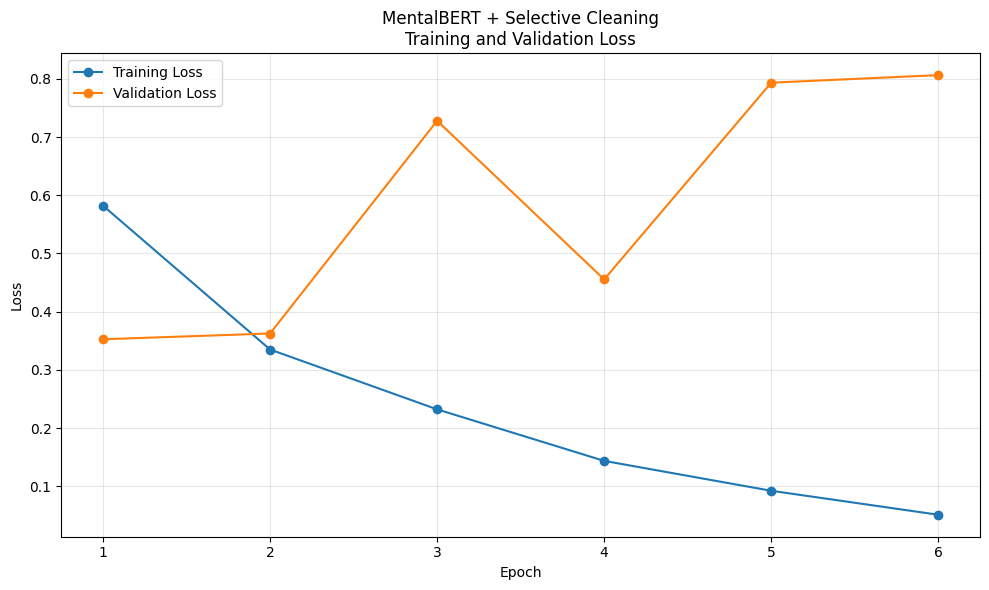

Generating Graph 2 — F1...


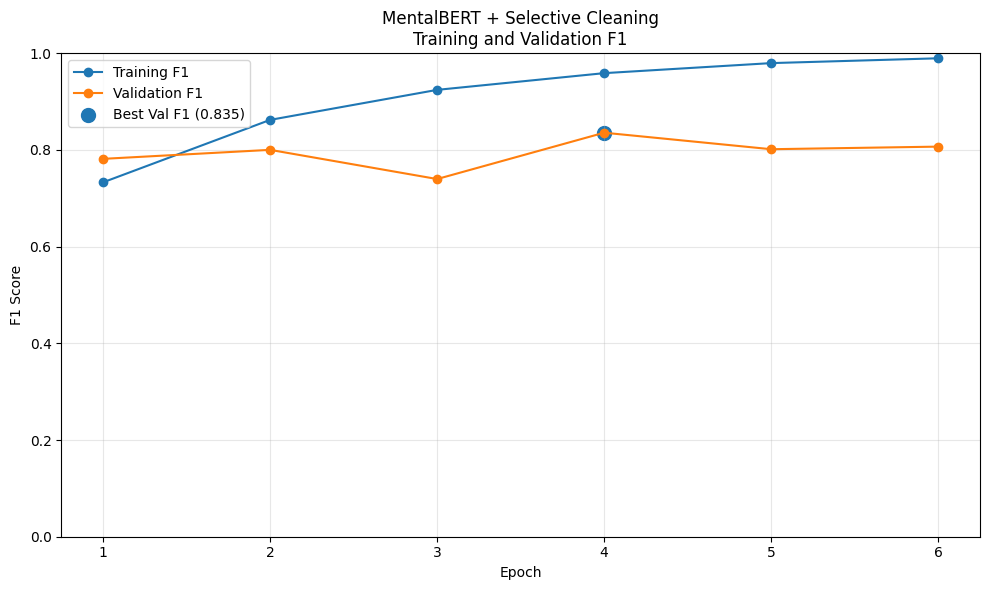

Generating Graph 3 — Validation ROC-AUC...


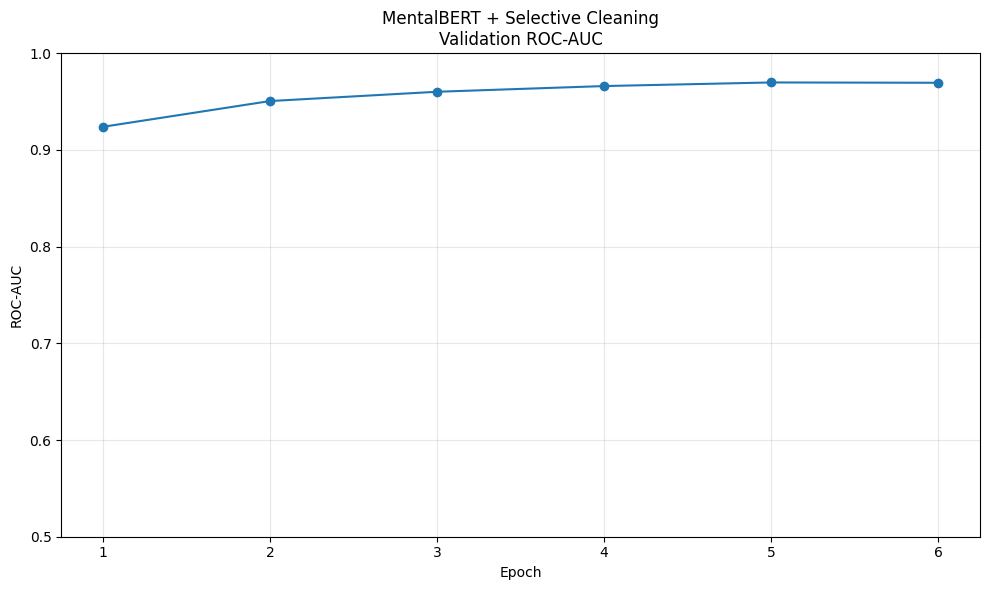

Generating Graph 4 — Final Test Metrics...


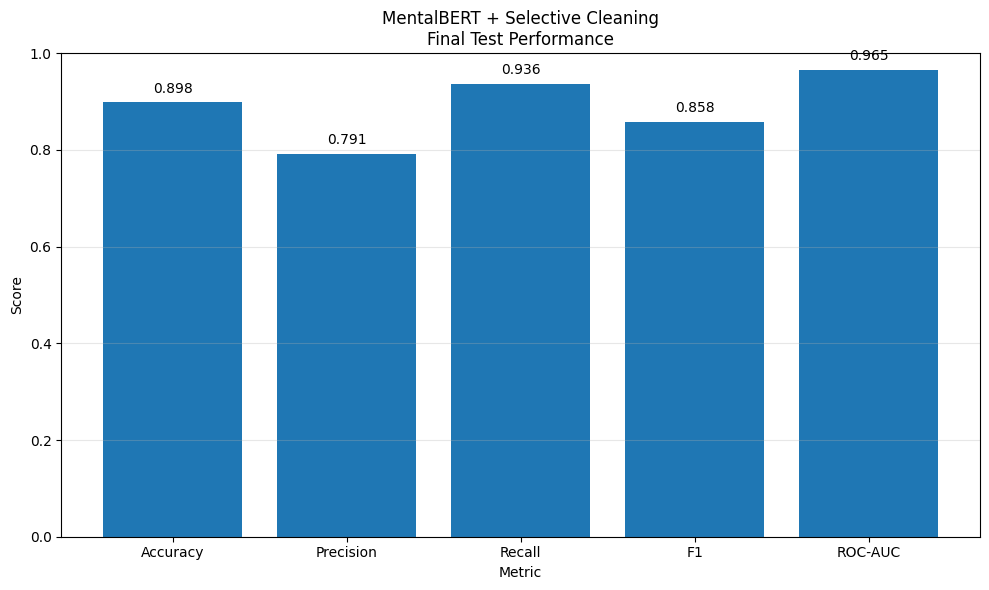

Generating Graph 5 — Confusion Matrix...


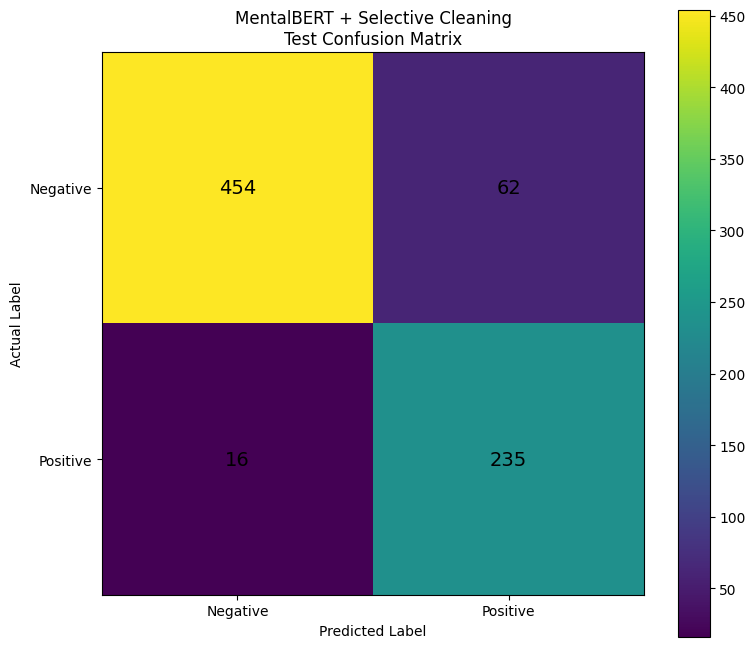

Generating Graph 6 — Token Distribution...


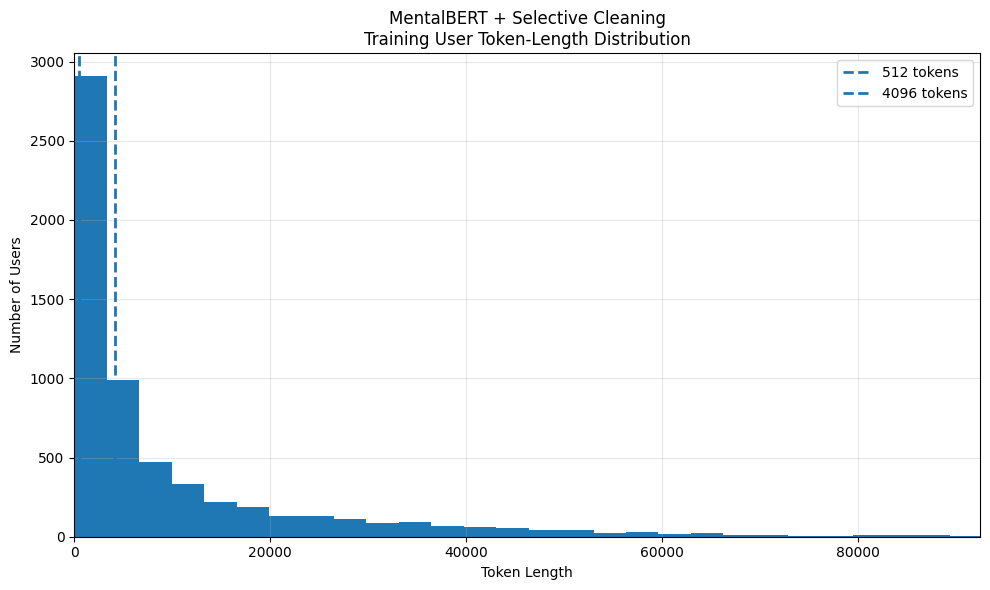

Generating Graph 7 — Context Coverage...


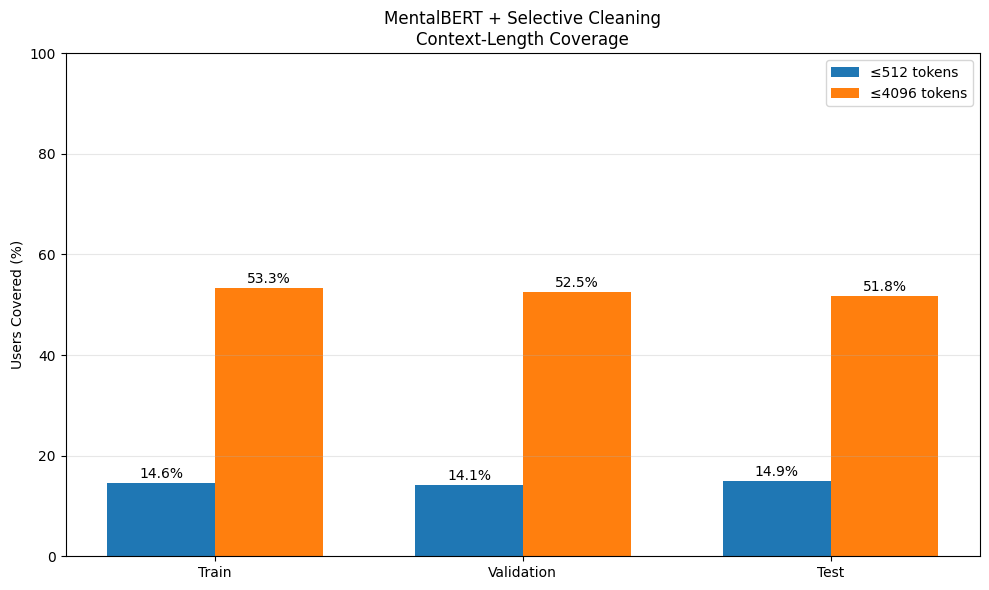

Generating Graph 8 — Metadata Gate...


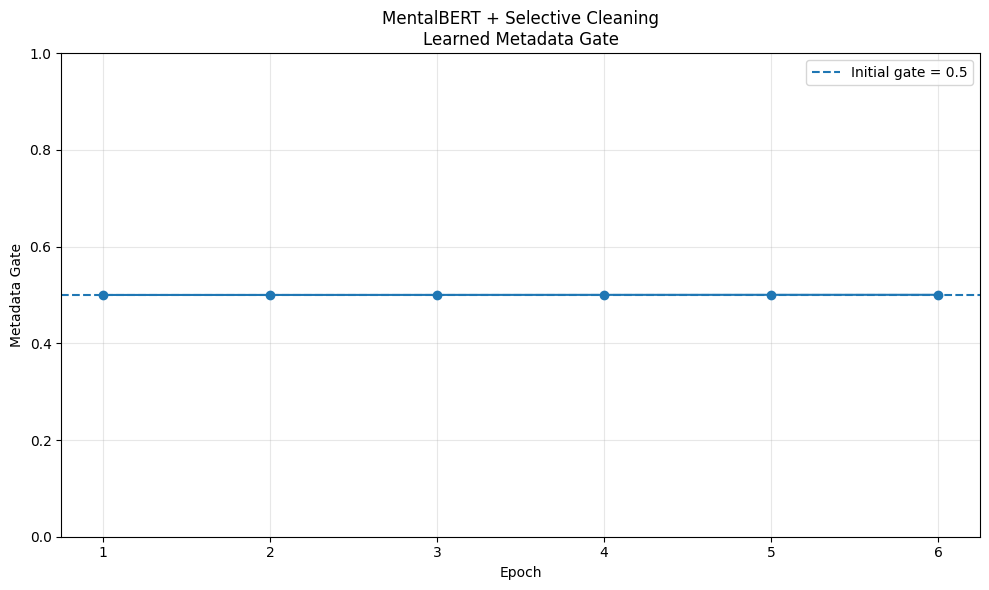

Generating Graph 9 — Test ROC Curve...


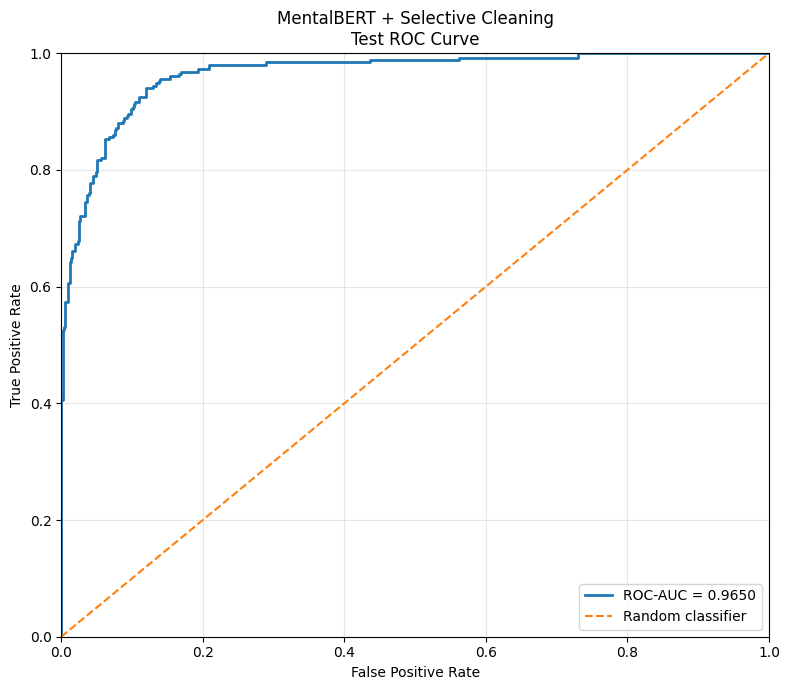

Generating Graph 10 — Precision-Recall Curve...


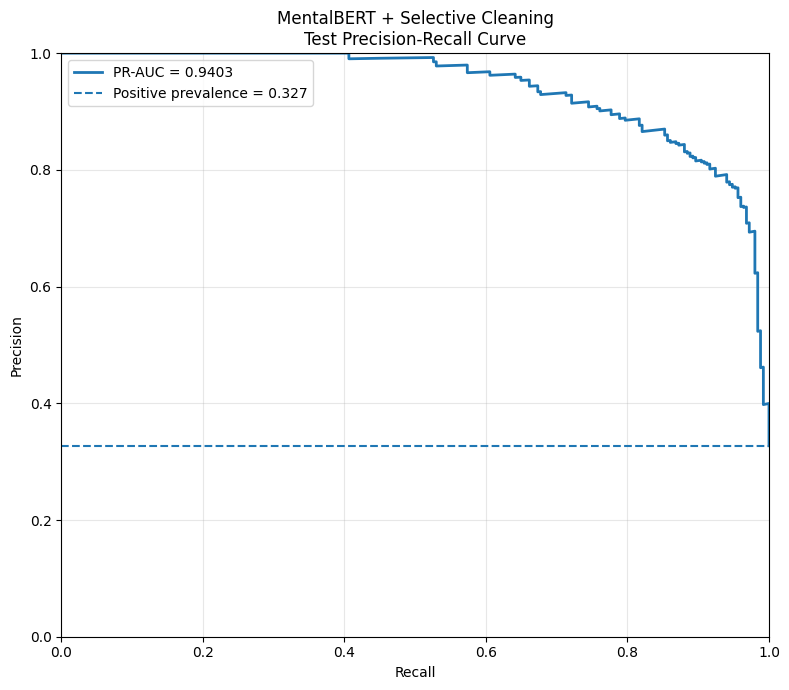


CELL 14 COMPLETE

FINAL TEST RESULTS
Accuracy : 89.83%
Precision: 79.12%
Recall   : 93.63%
F1       : 85.77%
ROC-AUC  : 96.50%

Figures saved to:
/kaggle/working/mentalbert_selective/results/final_report/figures

Tables saved to:
/kaggle/working/mentalbert_selective/results/final_report/tables

Final report directory:
/kaggle/working/mentalbert_selective/results/final_report

✓ 10 publication-ready figures saved
✓ Final metric table saved
✓ Confusion matrix saved
✓ Training history saved
✓ Token analysis saved
✓ ROC data saved
✓ Precision-Recall data saved
✓ Report metadata saved


In [17]:
# ============================================================
# CELL 14 — MENTALBERT SELECTIVE
# FINAL GRAPHS + TABLES + REPORTING
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    auc
)

print("=" * 70)
print("MENTALBERT SELECTIVE — FINAL REPORTING PACKAGE")
print("=" * 70)


# ============================================================
# DIRECTORIES
# ============================================================

FINAL_REPORT_DIR = os.path.join(
    RESULT_DIR,
    "final_report"
)

FIGURE_DIR = os.path.join(
    FINAL_REPORT_DIR,
    "figures"
)

TABLE_DIR = os.path.join(
    FINAL_REPORT_DIR,
    "tables"
)

os.makedirs(
    FINAL_REPORT_DIR,
    exist_ok=True
)

os.makedirs(
    FIGURE_DIR,
    exist_ok=True
)

os.makedirs(
    TABLE_DIR,
    exist_ok=True
)


# ============================================================
# SAVE FINAL METRICS TABLE
# ============================================================

print()
print("=" * 70)
print("1. FINAL METRICS TABLE")
print("=" * 70)

display(
    metrics_df
)

metrics_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "01_final_test_metrics.csv"
    ),
    index=False
)


# ============================================================
# CONFUSION MATRIX TABLE
# ============================================================

print()
print("=" * 70)
print("2. CONFUSION MATRIX TABLE")
print("=" * 70)

final_cm_df = pd.DataFrame(
    cm,
    index=[
        "Actual Negative",
        "Actual Positive"
    ],
    columns=[
        "Predicted Negative",
        "Predicted Positive"
    ]
)

display(
    final_cm_df
)

final_cm_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "02_confusion_matrix.csv"
    )
)


# ============================================================
# TRAINING HISTORY TABLE
# ============================================================

print()
print("=" * 70)
print("3. TRAINING HISTORY")
print("=" * 70)

display(
    history_df
)

history_df.to_csv(
    os.path.join(
        TABLE_DIR,
        "03_training_history.csv"
    ),
    index=False
)


# ============================================================
# TOKEN LENGTH SUMMARY
# ============================================================

print()
print("=" * 70)
print("4. TOKEN LENGTH SUMMARY")
print("=" * 70)

display(
    mental_selective_token_summary
)

mental_selective_token_summary.to_csv(
    os.path.join(
        TABLE_DIR,
        "04_token_length_summary.csv"
    ),
    index=False
)


# ============================================================
# GRAPH 1 — TRAIN / VALIDATION LOSS
# ============================================================

print()
print("Generating Graph 1 — Loss...")

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Training and Validation Loss"
)

plt.xticks(
    history_df["epoch"]
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "01_training_validation_loss.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 2 — TRAIN / VALIDATION F1
# ============================================================

print(
    "Generating Graph 2 — F1..."
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["train_f1"],
    marker="o",
    label="Training F1"
)

plt.plot(
    history_df["epoch"],
    history_df["val_f1"],
    marker="o",
    label="Validation F1"
)

best_epoch_plot = int(
    history_df.loc[
        history_df["val_f1"].idxmax(),
        "epoch"
    ]
)

best_f1_plot = float(
    history_df["val_f1"].max()
)

plt.scatter(
    [best_epoch_plot],
    [best_f1_plot],
    s=100,
    label=(
        f"Best Val F1 "
        f"({best_f1_plot:.3f})"
    )
)

plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Training and Validation F1"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "02_training_validation_f1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 3 — VALIDATION ROC-AUC
# ============================================================

print(
    "Generating Graph 3 — Validation ROC-AUC..."
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["val_roc_auc"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("ROC-AUC")

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Validation ROC-AUC"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0.5,
    1.0
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "03_validation_roc_auc.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 4 — FINAL TEST METRICS
# ============================================================

print(
    "Generating Graph 4 — Final Test Metrics..."
)

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC"
]

metric_values = [
    test_accuracy,
    test_precision,
    test_recall,
    test_f1,
    test_roc_auc
]

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    metric_names,
    metric_values
)

plt.xlabel("Metric")
plt.ylabel("Score")

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Final Test Performance"
)

plt.ylim(
    0,
    1
)

for bar, value in zip(
    bars,
    metric_values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "04_final_test_metrics.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 5 — CONFUSION MATRIX
# ============================================================

print(
    "Generating Graph 5 — Confusion Matrix..."
)

plt.figure(
    figsize=(8, 7)
)

plt.imshow(
    cm,
    interpolation="nearest"
)

plt.colorbar()

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Test Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "Actual Label"
)

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14
        )

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "05_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 6 — TOKEN LENGTH DISTRIBUTION
# ============================================================

print(
    "Generating Graph 6 — Token Distribution..."
)

plt.figure(
    figsize=(10, 6)
)

plt.hist(
    train_mental_selective_token_lengths,
    bins=100
)

plt.axvline(
    512,
    linestyle="--",
    linewidth=2,
    label="512 tokens"
)

plt.axvline(
    4096,
    linestyle="--",
    linewidth=2,
    label="4096 tokens"
)

plt.xlabel(
    "Token Length"
)

plt.ylabel(
    "Number of Users"
)

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Training User Token-Length Distribution"
)

# Avoid extreme tail dominating the figure
x_limit = np.percentile(
    train_mental_selective_token_lengths,
    99
)

plt.xlim(
    0,
    max(
        512,
        min(
            x_limit,
            100000
        )
    )
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "06_training_token_length_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 7 — CONTEXT COVERAGE
# ============================================================

print(
    "Generating Graph 7 — Context Coverage..."
)

split_names = [
    "Train",
    "Validation",
    "Test"
]

coverage_512 = [
    np.mean(
        train_mental_selective_token_lengths <= 512
    ) * 100,

    np.mean(
        val_mental_selective_token_lengths <= 512
    ) * 100,

    np.mean(
        test_mental_selective_token_lengths <= 512
    ) * 100
]

coverage_4096 = [
    np.mean(
        train_mental_selective_token_lengths <= 4096
    ) * 100,

    np.mean(
        val_mental_selective_token_lengths <= 4096
    ) * 100,

    np.mean(
        test_mental_selective_token_lengths <= 4096
    ) * 100
]

x = np.arange(
    len(split_names)
)

width = 0.35

plt.figure(
    figsize=(10, 6)
)

plt.bar(
    x - width / 2,
    coverage_512,
    width,
    label="≤512 tokens"
)

plt.bar(
    x + width / 2,
    coverage_4096,
    width,
    label="≤4096 tokens"
)

plt.xticks(
    x,
    split_names
)

plt.ylabel(
    "Users Covered (%)"
)

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Context-Length Coverage"
)

plt.ylim(
    0,
    100
)

for i in range(
    len(split_names)
):

    plt.text(
        i - width / 2,
        coverage_512[i] + 1,
        f"{coverage_512[i]:.1f}%",
        ha="center"
    )

    plt.text(
        i + width / 2,
        coverage_4096[i] + 1,
        f"{coverage_4096[i]:.1f}%",
        ha="center"
    )

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "07_context_coverage.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 8 — METADATA GATE
# ============================================================

print(
    "Generating Graph 8 — Metadata Gate..."
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    history_df["epoch"],
    history_df["metadata_gate"],
    marker="o"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.5,
    label="Initial gate = 0.5"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Metadata Gate"
)

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Learned Metadata Gate"
)

plt.xticks(
    history_df["epoch"]
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "08_metadata_gate.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 9 — TEST ROC CURVE
# ============================================================

print(
    "Generating Graph 9 — Test ROC Curve..."
)

fpr, tpr, roc_thresholds = roc_curve(
    test_labels_all,
    test_probabilities_all
)

roc_auc_value = auc(
    fpr,
    tpr
)

plt.figure(
    figsize=(8, 7)
)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc_value:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Test ROC Curve"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "09_test_roc_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# GRAPH 10 — TEST PRECISION-RECALL CURVE
# ============================================================

print(
    "Generating Graph 10 — Precision-Recall Curve..."
)

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        test_labels_all,
        test_probabilities_all
    )
)

pr_auc_value = auc(
    recall_curve,
    precision_curve
)

positive_rate = np.mean(
    np.asarray(test_labels_all)
)

plt.figure(
    figsize=(8, 7)
)

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"PR-AUC = {pr_auc_value:.4f}"
)

plt.axhline(
    positive_rate,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Positive prevalence = "
        f"{positive_rate:.3f}"
    )
)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "MentalBERT + Selective Cleaning\n"
    "Test Precision-Recall Curve"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "10_test_precision_recall_curve.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE ROC / PR DATA
# ============================================================

pd.DataFrame({
    "fpr": fpr,
    "tpr": tpr,
    "threshold": np.r_[
        roc_thresholds,
        np.nan
    ][:len(fpr)]
}).to_csv(
    os.path.join(
        TABLE_DIR,
        "05_test_roc_curve_data.csv"
    ),
    index=False
)

pd.DataFrame({
    "recall": recall_curve,
    "precision": precision_curve
}).to_csv(
    os.path.join(
        TABLE_DIR,
        "06_test_precision_recall_curve_data.csv"
    ),
    index=False
)


# ============================================================
# GRAPH SUMMARY TABLE
# ============================================================

graph_summary = pd.DataFrame({

    "Figure": [
        "01_training_validation_loss.png",
        "02_training_validation_f1.png",
        "03_validation_roc_auc.png",
        "04_final_test_metrics.png",
        "05_confusion_matrix.png",
        "06_training_token_length_distribution.png",
        "07_context_coverage.png",
        "08_metadata_gate.png",
        "09_test_roc_curve.png",
        "10_test_precision_recall_curve.png"
    ],

    "Description": [
        "Training and validation loss by epoch",
        "Training and validation F1 by epoch",
        "Validation ROC-AUC by epoch",
        "Final held-out test metrics",
        "Held-out test confusion matrix",
        "Training user token-length distribution",
        "512 vs 4096 context coverage",
        "Learned metadata gate across epochs",
        "Held-out test ROC curve",
        "Held-out test precision-recall curve"
    ]
})

graph_summary.to_csv(
    os.path.join(
        TABLE_DIR,
        "07_graph_index.csv"
    ),
    index=False
)


# ============================================================
# MASTER REPORT JSON
# ============================================================

report_metadata = {

    "model":
        "MentalBERT",

    "cleaning_method":
        "Selective",

    "test_metrics": {

        "accuracy":
            float(test_accuracy),

        "precision":
            float(test_precision),

        "recall":
            float(test_recall),

        "f1":
            float(test_f1),

        "roc_auc":
            float(test_roc_auc),

        "loss":
            float(test_loss)
    },

    "best_epoch":
        int(best_epoch_loaded),

    "best_validation_f1":
        float(best_val_f1_loaded),

    "parameters_m":
        float(total_parameters / 1e6),

    "confusion_matrix": {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    },

    "metadata_gate":
        float(metadata_gate),

    "roc_auc_from_curve":
        float(roc_auc_value),

    "pr_auc":
        float(pr_auc_value),

    "figures":
        10
}

with open(
    os.path.join(
        FINAL_REPORT_DIR,
        "report_metadata.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report_metadata,
        f,
        indent=2
    )


# ============================================================
# FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("CELL 14 COMPLETE")
print("=" * 70)

print()
print("FINAL TEST RESULTS")

print(
    f"Accuracy : {test_accuracy * 100:.2f}%"
)

print(
    f"Precision: {test_precision * 100:.2f}%"
)

print(
    f"Recall   : {test_recall * 100:.2f}%"
)

print(
    f"F1       : {test_f1 * 100:.2f}%"
)

print(
    f"ROC-AUC  : {test_roc_auc * 100:.2f}%"
)

print()
print(
    "Figures saved to:"
)

print(
    FIGURE_DIR
)

print()
print(
    "Tables saved to:"
)

print(
    TABLE_DIR
)

print()
print(
    "Final report directory:"
)

print(
    FINAL_REPORT_DIR
)

print()
print(
    "✓ 10 publication-ready figures saved"
)

print(
    "✓ Final metric table saved"
)

print(
    "✓ Confusion matrix saved"
)

print(
    "✓ Training history saved"
)

print(
    "✓ Token analysis saved"
)

print(
    "✓ ROC data saved"
)

print(
    "✓ Precision-Recall data saved"
)

print(
    "✓ Report metadata saved"
)

t-SNE REPRESENTATION ANALYSIS
MENTALBERT + SELECTIVE

✓ MentalBERT model in evaluation mode

EXTRACTING FUSED REPRESENTATIONS
Processed batch 1/48
Processed batch 10/48
Processed batch 20/48
Processed batch 30/48
Processed batch 40/48
Processed batch 48/48

FUSED REPRESENTATION SUMMARY
Fused representation shape: (767, 832)
Test users: 767
Fused dimensions: 832
Negative users: 516
Positive users: 251
Metadata gate: 0.500144

PCA REDUCTION
Original dimensions: 832
PCA dimensions: 50
Variance retained: 99.22%

t-SNE REDUCTION
t-SNE output shape: (767, 2)


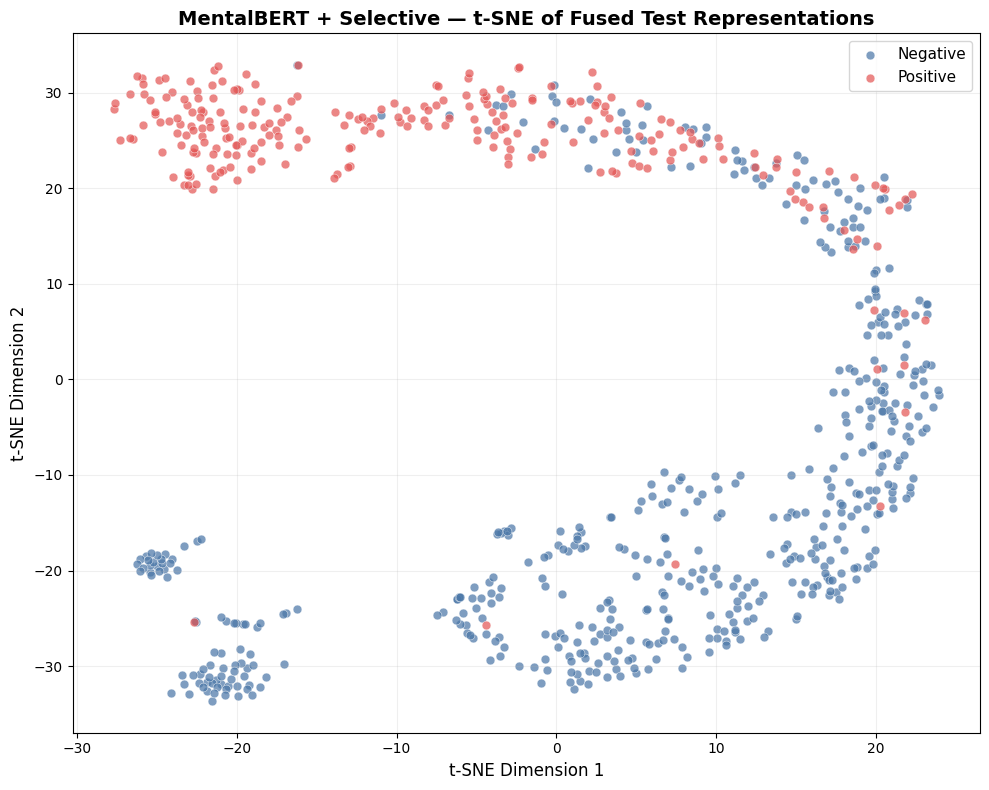


t-SNE ANALYSIS COMPLETE
✓ Exact MentalBERT fused representation extracted
✓ PCA reduction completed
✓ t-SNE reduction completed
✓ t-SNE graph saved:
/kaggle/working/mentalbert_selective/results/explainability/tsne/mentalbert_selective_tsne.png
✓ t-SNE graph displayed above
✓ Coordinates saved:
/kaggle/working/mentalbert_selective/results/explainability/tsne/mentalbert_selective_tsne_coordinates.csv
✓ Configuration saved


In [19]:
# ============================================================
# CELL 15 — MENTALBERT + SELECTIVE
# t-SNE REPRESENTATION ANALYSIS
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

print("=" * 70)
print("t-SNE REPRESENTATION ANALYSIS")
print("MENTALBERT + SELECTIVE")
print("=" * 70)

# ============================================================
# FIXED EXPLAINABILITY SETTINGS
# ============================================================

EXPLAINABILITY_SEED = 42

PCA_COMPONENTS = 50

TSNE_COMPONENTS = 2
TSNE_PERPLEXITY = 30
TSNE_LEARNING_RATE = 200
TSNE_MAX_ITER = 1000

np.random.seed(
    EXPLAINABILITY_SEED
)

torch.manual_seed(
    EXPLAINABILITY_SEED
)

# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    RESULT_DIR,
    "explainability"
)

TSNE_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "tsne"
)

os.makedirs(
    TSNE_DIR,
    exist_ok=True
)

# ============================================================
# MODEL
# ============================================================

model_mental_selective.eval()

print()
print("✓ MentalBERT model in evaluation mode")

# ============================================================
# EXTRACT EXACT FUSED REPRESENTATION
# ============================================================

fused_representations = []
test_labels = []

print()
print("=" * 70)
print("EXTRACTING FUSED REPRESENTATIONS")
print("=" * 70)

with torch.no_grad():

    for batch_idx, batch in enumerate(
        test_mental_selective_loader,
        start=1
    ):

        input_ids = batch[
            "input_ids"
        ].to(device)

        attention_mask = batch[
            "attention_mask"
        ].to(device)

        metadata = batch[
            "metadata"
        ].to(device)

        labels = batch[
            "labels"
        ].to(device)

        # ----------------------------------------------------
        # MENTALBERT ENCODER
        # ----------------------------------------------------

        encoder_output = model_mental_selective.mentalbert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden_states = (
            encoder_output.last_hidden_state
        )

        # ----------------------------------------------------
        # EXACT TEXT ATTENTION POOLING
        # ----------------------------------------------------

        projected = torch.tanh(
            model_mental_selective.attention_projection(
                hidden_states
            )
        )

        attention_scores = (
            model_mental_selective.attention_score(
                projected
            )
            .squeeze(-1)
        )

        attention_scores = (
            attention_scores.masked_fill(
                attention_mask == 0,
                -1e9
            )
        )

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        text_representation = torch.sum(
            hidden_states
            *
            attention_weights.unsqueeze(-1),
            dim=1
        )

        # ----------------------------------------------------
        # EXACT METADATA BRANCH
        # ----------------------------------------------------

        metadata_representation = (
            model_mental_selective.metadata_branch(
                metadata
            )
        )

        # ----------------------------------------------------
        # EXACT LEARNED METADATA GATE
        # ----------------------------------------------------

        metadata_gate = torch.sigmoid(
            model_mental_selective.metadata_beta
        )

        gated_metadata = (
            metadata_gate
            *
            metadata_representation
        )

        # ----------------------------------------------------
        # EXACT FUSED REPRESENTATION
        # ----------------------------------------------------

        fused = torch.cat(
            [
                text_representation,
                gated_metadata
            ],
            dim=1
        )

        fused_representations.append(
            fused.cpu().numpy()
        )

        test_labels.extend(
            labels.cpu().numpy().tolist()
        )

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == len(test_mental_selective_loader)
        ):

            print(
                f"Processed batch "
                f"{batch_idx}/{len(test_mental_selective_loader)}"
            )

# ============================================================
# COMBINE
# ============================================================

fused_representations = np.concatenate(
    fused_representations,
    axis=0
)

test_labels = np.array(
    test_labels
)

# ============================================================
# REPRESENTATION SUMMARY
# ============================================================

print()
print("=" * 70)
print("FUSED REPRESENTATION SUMMARY")
print("=" * 70)

print(
    "Fused representation shape:",
    fused_representations.shape
)

print(
    "Test users:",
    len(test_labels)
)

print(
    "Fused dimensions:",
    fused_representations.shape[1]
)

print(
    "Negative users:",
    int(
        (test_labels == 0).sum()
    )
)

print(
    "Positive users:",
    int(
        (test_labels == 1).sum()
    )
)

print(
    "Metadata gate:",
    f"{float(metadata_gate.item()):.6f}"
)

assert (
    fused_representations.shape[0]
    ==
    len(test_labels)
)

assert np.isfinite(
    fused_representations
).all()

# ============================================================
# PCA
# ============================================================

print()
print("=" * 70)
print("PCA REDUCTION")
print("=" * 70)

pca_dimensions = min(
    PCA_COMPONENTS,
    fused_representations.shape[1]
)

pca = PCA(
    n_components=pca_dimensions,
    random_state=EXPLAINABILITY_SEED
)

pca_representation = pca.fit_transform(
    fused_representations
)

pca_variance_retained = (
    pca.explained_variance_ratio_.sum()
)

print(
    "Original dimensions:",
    fused_representations.shape[1]
)

print(
    "PCA dimensions:",
    pca_representation.shape[1]
)

print(
    "Variance retained:",
    f"{pca_variance_retained * 100:.2f}%"
)

# ============================================================
# t-SNE
# ============================================================

print()
print("=" * 70)
print("t-SNE REDUCTION")
print("=" * 70)

tsne = TSNE(
    n_components=TSNE_COMPONENTS,
    perplexity=TSNE_PERPLEXITY,
    learning_rate=TSNE_LEARNING_RATE,
    init="pca",
    random_state=EXPLAINABILITY_SEED,
    max_iter=TSNE_MAX_ITER
)

tsne_representation = tsne.fit_transform(
    pca_representation
)

print(
    "t-SNE output shape:",
    tsne_representation.shape
)

# ============================================================
# SAVE COORDINATES
# ============================================================

tsne_df = pd.DataFrame({

    "tsne_1":
        tsne_representation[:, 0],

    "tsne_2":
        tsne_representation[:, 1],

    "label":
        test_labels

})

tsne_df["class"] = tsne_df[
    "label"
].map({
    0: "Negative",
    1: "Positive"
})

tsne_csv_path = os.path.join(
    TSNE_DIR,
    "mentalbert_selective_tsne_coordinates.csv"
)

tsne_df.to_csv(
    tsne_csv_path,
    index=False
)

# ============================================================
# PUBLICATION-QUALITY t-SNE PLOT
# ============================================================

plt.figure(
    figsize=(10, 8)
)

negative_mask = (
    test_labels == 0
)

positive_mask = (
    test_labels == 1
)

plt.scatter(
    tsne_representation[
        negative_mask,
        0
    ],
    tsne_representation[
        negative_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Negative",
    color="#4C78A8",
    edgecolors="white",
    linewidths=0.4
)

plt.scatter(
    tsne_representation[
        positive_mask,
        0
    ],
    tsne_representation[
        positive_mask,
        1
    ],
    s=40,
    alpha=0.72,
    label="Positive",
    color="#E45756",
    edgecolors="white",
    linewidths=0.4
)

plt.xlabel(
    "t-SNE Dimension 1",
    fontsize=12
)

plt.ylabel(
    "t-SNE Dimension 2",
    fontsize=12
)

plt.title(
    "MentalBERT + Selective — "
    "t-SNE of Fused Test Representations",
    fontsize=14,
    fontweight="bold"
)

plt.legend(
    fontsize=11
)

plt.grid(
    alpha=0.20
)

plt.tight_layout()

tsne_plot_path = os.path.join(
    TSNE_DIR,
    "mentalbert_selective_tsne.png"
)

# SAVE
plt.savefig(
    tsne_plot_path,
    dpi=300,
    bbox_inches="tight"
)

# DISPLAY
plt.show()

plt.close()

# ============================================================
# SAVE CONFIGURATION
# ============================================================

tsne_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "test_users":
        int(len(test_labels)),

    "input_representation":
        "Fused classifier representation",

    "text_representation_dimension":
        int(
            text_representation.shape[1]
        ),

    "metadata_representation_dimension":
        int(
            metadata_representation.shape[1]
        ),

    "fused_representation_dimension":
        int(
            fused_representations.shape[1]
        ),

    "pca_dimensions":
        int(
            pca_dimensions
        ),

    "pca_variance_retained":
        float(
            pca_variance_retained
        ),

    "tsne_dimensions":
        int(
            TSNE_COMPONENTS
        ),

    "tsne_perplexity":
        int(
            TSNE_PERPLEXITY
        ),

    "tsne_learning_rate":
        TSNE_LEARNING_RATE,

    "tsne_max_iterations":
        int(
            TSNE_MAX_ITER
        ),

    "random_seed":
        EXPLAINABILITY_SEED,

    "metadata_gate":
        float(
            metadata_gate.item()
        )

}

with open(
    os.path.join(
        TSNE_DIR,
        "mentalbert_selective_tsne_config.json"
    ),
    "w"
) as f:

    json.dump(
        tsne_config,
        f,
        indent=2
    )

# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("t-SNE ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ Exact MentalBERT fused representation extracted"
)

print(
    "✓ PCA reduction completed"
)

print(
    "✓ t-SNE reduction completed"
)

print(
    "✓ t-SNE graph saved:"
)

print(
    tsne_plot_path
)

print(
    "✓ t-SNE graph displayed above"
)

print(
    "✓ Coordinates saved:"
)

print(
    tsne_csv_path
)

print(
    "✓ Configuration saved"
)

SHAP ANALYSIS
MENTALBERT + SELECTIVE

Total metadata features: 53

SHAP background samples: 50
Background dimensions: 53

SHAP test samples: 100
Negative: 50
Positive: 50

✓ MentalBERT Selective model set to evaluation mode
✓ Model parameters frozen for SHAP

COMPUTING SHAP VALUES
Explained 1/100 test users
Explained 10/100 test users
Explained 20/100 test users
Explained 30/100 test users
Explained 40/100 test users
Explained 50/100 test users
Explained 60/100 test users
Explained 70/100 test users
Explained 80/100 test users
Explained 90/100 test users
Explained 100/100 test users

SHAP RESULT SUMMARY
SHAP matrix: (100, 53)
Metadata matrix: (100, 53)

TOP 20 SHAP FEATURES
                feature  mean_abs_shap  mean_signed_shap
           lda_topic_17       0.000450          0.000025
        neg_emoji_count       0.000413         -0.000293
           lda_topic_14       0.000389         -0.000145
   avg_paragraph_length       0.000345         -0.000251
     hopelessness_score       0.

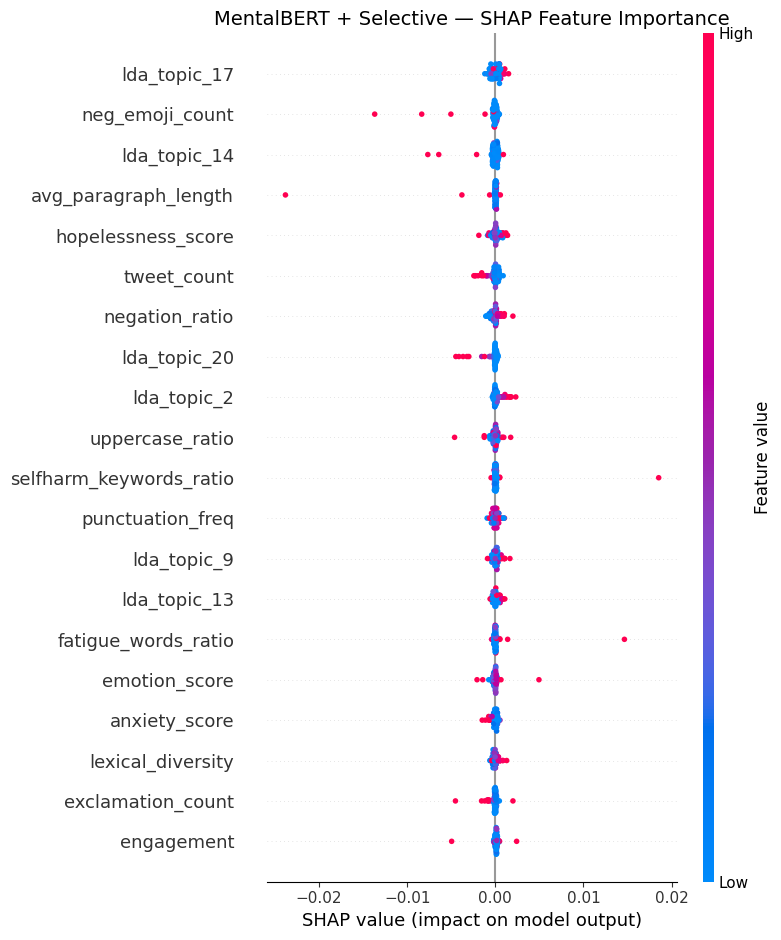

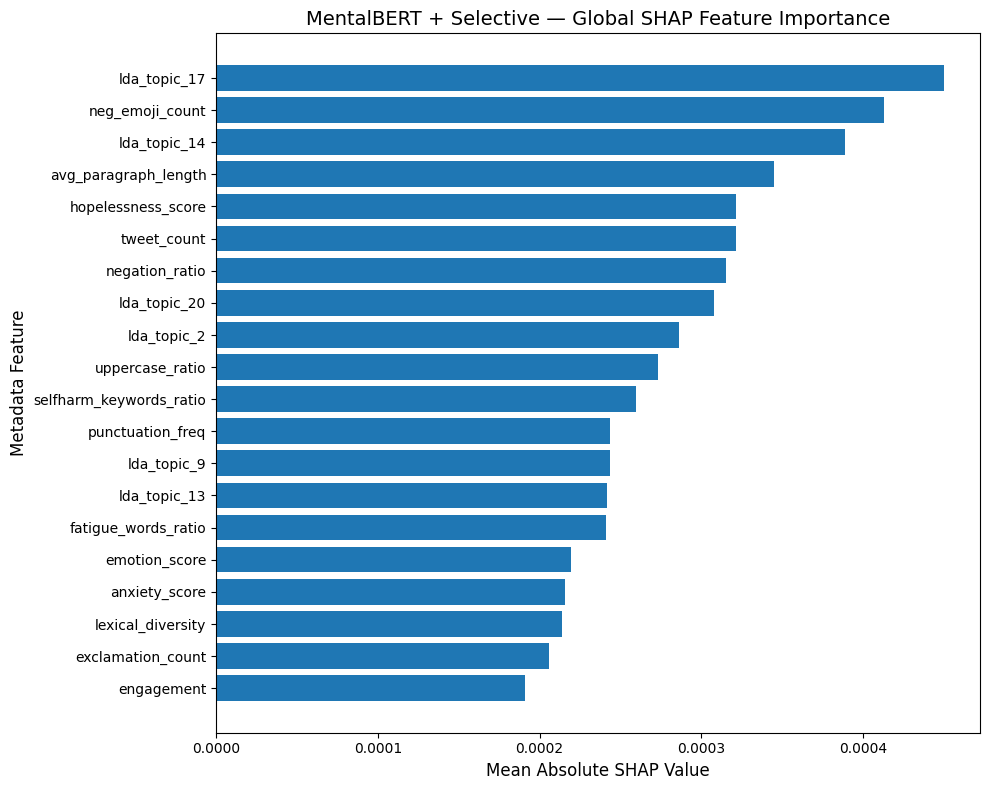


SHAP ANALYSIS COMPLETE
✓ 53 metadata features explained
✓ 50 negative + 50 positive users
✓ Training-only background used
✓ Positive-class logit explained
✓ SHAP values saved
✓ Feature ranking saved
✓ Beeswarm saved and displayed
✓ Bar plot saved and displayed
✓ Configuration saved

SHAP output directory: /kaggle/working/mentalbert_selective/explainability/shap


In [20]:
# ============================================================
# EXPLAINABILITY — SHAP
# MENTALBERT + SELECTIVE
# GLOBAL METADATA FEATURE EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import shap

print("=" * 70)
print("SHAP ANALYSIS")
print("MENTALBERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SHAP SETTINGS
# ============================================================

SHAP_SEED = 42
SHAP_BACKGROUND_SIZE = 50
SHAP_TEST_SIZE_PER_CLASS = 50
SHAP_TOP_FEATURES = 20

np.random.seed(SHAP_SEED)
torch.manual_seed(SHAP_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

EXPLAINABILITY_DIR = os.path.join(
    BASE_RESULT_DIR,
    "explainability"
)

SHAP_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "shap"
)

os.makedirs(
    SHAP_DIR,
    exist_ok=True
)


# ============================================================
# FEATURE NAMES
# ============================================================

feature_names = list(
    selected_metadata_names
)

assert len(feature_names) == 53

print()
print(
    "Total metadata features:",
    len(feature_names)
)


# ============================================================
# FIXED BACKGROUND DATA
# TRAINING USERS ONLY
# ============================================================

background_metadata = (
    train_mental_selective_dataset.metadata[
        :SHAP_BACKGROUND_SIZE
    ]
    .clone()
    .detach()
    .to(device)
)

print()
print(
    "SHAP background samples:",
    background_metadata.shape[0]
)

print(
    "Background dimensions:",
    background_metadata.shape[1]
)

assert background_metadata.shape[1] == 53


# ============================================================
# FIXED TEST USERS
# 50 NEGATIVE + 50 POSITIVE
# ============================================================

test_labels_tensor = (
    test_mental_selective_dataset.labels
    .detach()
    .cpu()
)

negative_indices = torch.where(
    test_labels_tensor == 0
)[0].numpy()

positive_indices = torch.where(
    test_labels_tensor == 1
)[0].numpy()

assert len(
    negative_indices
) >= SHAP_TEST_SIZE_PER_CLASS

assert len(
    positive_indices
) >= SHAP_TEST_SIZE_PER_CLASS

shap_negative_indices = (
    negative_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_positive_indices = (
    positive_indices[
        :SHAP_TEST_SIZE_PER_CLASS
    ]
)

shap_test_indices = np.concatenate(
    [
        shap_negative_indices,
        shap_positive_indices
    ]
)

print()
print(
    "SHAP test samples:",
    len(shap_test_indices)
)

print(
    "Negative:",
    len(shap_negative_indices)
)

print(
    "Positive:",
    len(shap_positive_indices)
)


# ============================================================
# MODEL WRAPPER
# ============================================================
# Explains metadata while keeping each user's
# Transformer text representation fixed.
# No model parameters are changed.

class MetadataSHAPWrapper(
    nn.Module
):

    def __init__(
        self,
        base_model,
        fixed_input_ids,
        fixed_attention_mask
    ):

        super().__init__()

        self.base_model = base_model

        self.fixed_input_ids = (
            fixed_input_ids
            .to(device)
        )

        self.fixed_attention_mask = (
            fixed_attention_mask
            .to(device)
        )

    def forward(
        self,
        metadata
    ):

        batch_size = metadata.size(0)

        input_ids = (
            self.fixed_input_ids
            .expand(
                batch_size,
                -1
            )
        )

        attention_mask = (
            self.fixed_attention_mask
            .expand(
                batch_size,
                -1
            )
        )

        output = self.base_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        # Positive/depression class logit
        positive_logit = output[
            "logits"
        ][:, 1:2]

        return positive_logit


# ============================================================
# MODEL PREPARATION
# USE THE NOTEBOOK'S EXISTING VARIABLE:
# model_mental_selective
# ============================================================

model_mental_selective.eval()

for parameter in model_mental_selective.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT Selective model set to evaluation mode")
print("✓ Model parameters frozen for SHAP")


# ============================================================
# COMPUTE SHAP VALUES
# ============================================================

all_shap_values = []
all_metadata_values = []
all_explained_labels = []

print()
print("=" * 70)
print("COMPUTING SHAP VALUES")
print("=" * 70)


for count, test_index in enumerate(
    shap_test_indices,
    start=1
):

    sample = test_mental_selective_dataset[
        int(test_index)
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
    )

    metadata_sample = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )

    label = int(
        sample["labels"].item()
    )


    # --------------------------------------------------------
    # USER-SPECIFIC SHAP WRAPPER
    # --------------------------------------------------------

    wrapper = MetadataSHAPWrapper(
        model_mental_selective,
        input_ids,
        attention_mask
    ).to(device)

    wrapper.eval()


    # --------------------------------------------------------
    # GRADIENT SHAP
    # --------------------------------------------------------

    explainer = shap.GradientExplainer(
        wrapper,
        background_metadata
    )

    shap_result = explainer.shap_values(
        metadata_sample
    )


    # --------------------------------------------------------
    # HANDLE SHAP OUTPUT FORMAT
    # --------------------------------------------------------

    if isinstance(
        shap_result,
        list
    ):

        shap_array = np.asarray(
            shap_result[0]
        )

    else:

        shap_array = np.asarray(
            shap_result
        )

    shap_array = np.squeeze(
        shap_array
    )

    assert shap_array.shape == (
        53,
    )


    all_shap_values.append(
        shap_array
    )

    all_metadata_values.append(
        metadata_sample
        .detach()
        .cpu()
        .numpy()
        .squeeze(0)
    )

    all_explained_labels.append(
        label
    )


    if (
        count == 1
        or count % 10 == 0
        or count == len(
            shap_test_indices
        )
    ):

        print(
            f"Explained "
            f"{count}/"
            f"{len(shap_test_indices)} "
            f"test users"
        )


# ============================================================
# COMBINE RESULTS
# ============================================================

all_shap_values = np.vstack(
    all_shap_values
)

all_metadata_values = np.vstack(
    all_metadata_values
)

all_explained_labels = np.array(
    all_explained_labels
)

print()
print("=" * 70)
print("SHAP RESULT SUMMARY")
print("=" * 70)

print(
    "SHAP matrix:",
    all_shap_values.shape
)

print(
    "Metadata matrix:",
    all_metadata_values.shape
)

assert all_shap_values.shape == (
    len(shap_test_indices),
    53
)

assert all_metadata_values.shape == (
    len(shap_test_indices),
    53
)

assert np.isfinite(
    all_shap_values
).all()


# ============================================================
# GLOBAL FEATURE IMPORTANCE
# ============================================================

mean_abs_shap = np.mean(
    np.abs(
        all_shap_values
    ),
    axis=0
)

mean_signed_shap = np.mean(
    all_shap_values,
    axis=0
)

feature_importance_df = pd.DataFrame({

    "feature":
        feature_names,

    "mean_abs_shap":
        mean_abs_shap,

    "mean_signed_shap":
        mean_signed_shap

})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print()
print("=" * 70)
print("TOP 20 SHAP FEATURES")
print("=" * 70)

print(
    feature_importance_df
    .head(SHAP_TOP_FEATURES)
    .to_string(
        index=False
    )
)


# ============================================================
# SAVE SHAP VALUES
# ============================================================

shap_values_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

shap_values_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_selective_shap_values.csv"
    ),
    index=False
)


# ============================================================
# SAVE FEATURE IMPORTANCE
# ============================================================

feature_importance_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_selective_shap_feature_importance.csv"
    ),
    index=False
)


# ============================================================
# SAVE TEST USER INFORMATION
# ============================================================

explained_users_df = pd.DataFrame({

    "test_index":
        shap_test_indices,

    "label":
        all_explained_labels

})

explained_users_df.to_csv(
    os.path.join(
        SHAP_DIR,
        "mentalbert_selective_shap_test_users.csv"
    ),
    index=False
)


# ============================================================
# SHAP BEESWARM
# ============================================================

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    all_shap_values,
    all_metadata_values,
    feature_names=feature_names,
    max_display=SHAP_TOP_FEATURES,
    show=False
)

plt.title(
    "MentalBERT + Selective — SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_beeswarm_path = os.path.join(
    SHAP_DIR,
    "mentalbert_selective_shap_beeswarm.png"
)

plt.savefig(
    shap_beeswarm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SHAP BAR
# ============================================================

top_features = (
    feature_importance_df
    .head(
        SHAP_TOP_FEATURES
    )
    .iloc[::-1]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    top_features["feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel(
    "Mean Absolute SHAP Value",
    fontsize=12
)

plt.ylabel(
    "Metadata Feature",
    fontsize=12
)

plt.title(
    "MentalBERT + Selective — Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()

shap_bar_path = os.path.join(
    SHAP_DIR,
    "mentalbert_selective_shap_bar.png"
)

plt.savefig(
    shap_bar_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.close()


# ============================================================
# SAVE CONFIG
# ============================================================

shap_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "metadata_features":
        53,

    "background_samples":
        SHAP_BACKGROUND_SIZE,

    "test_samples_per_class":
        SHAP_TEST_SIZE_PER_CLASS,

    "total_explained_users":
        len(shap_test_indices),

    "target":
        "Positive/depression class logit",

    "explainer":
        "GradientExplainer",

    "text_fixed_per_user":
        True,

    "random_seed":
        SHAP_SEED,

    "top_features":
        SHAP_TOP_FEATURES
}

with open(
    os.path.join(
        SHAP_DIR,
        "mentalbert_selective_shap_config.json"
    ),
    "w"
) as f:

    json.dump(
        shap_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("SHAP ANALYSIS COMPLETE")
print("=" * 70)

print("✓ 53 metadata features explained")
print("✓ 50 negative + 50 positive users")
print("✓ Training-only background used")
print("✓ Positive-class logit explained")
print("✓ SHAP values saved")
print("✓ Feature ranking saved")
print("✓ Beeswarm saved and displayed")
print("✓ Bar plot saved and displayed")
print("✓ Configuration saved")

print()
print(
    "SHAP output directory:",
    SHAP_DIR
)

GRAD-CAM ANALYSIS
MENTALBERT + SELECTIVE

✓ MentalBERT Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 3 | True = 1 | Pred = 1 | Positive Probability = 0.9959
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.0078
FP: Test Index = 27 | True = 0 | Pred = 1 | Positive Probability = 0.6861
FN: Test Index = 1 | True = 1 | Pred = 0 | Positive Probability = 0.3802

COMPUTING GRAD-CAM

Processing TP (Test Index 3)
✓ TP complete

Processing TN (Test Index 0)
✓ TN complete

Processing FP (Test Index 27)
✓ FP complete

Processing FN (Test Index 1)
✓ FN complete


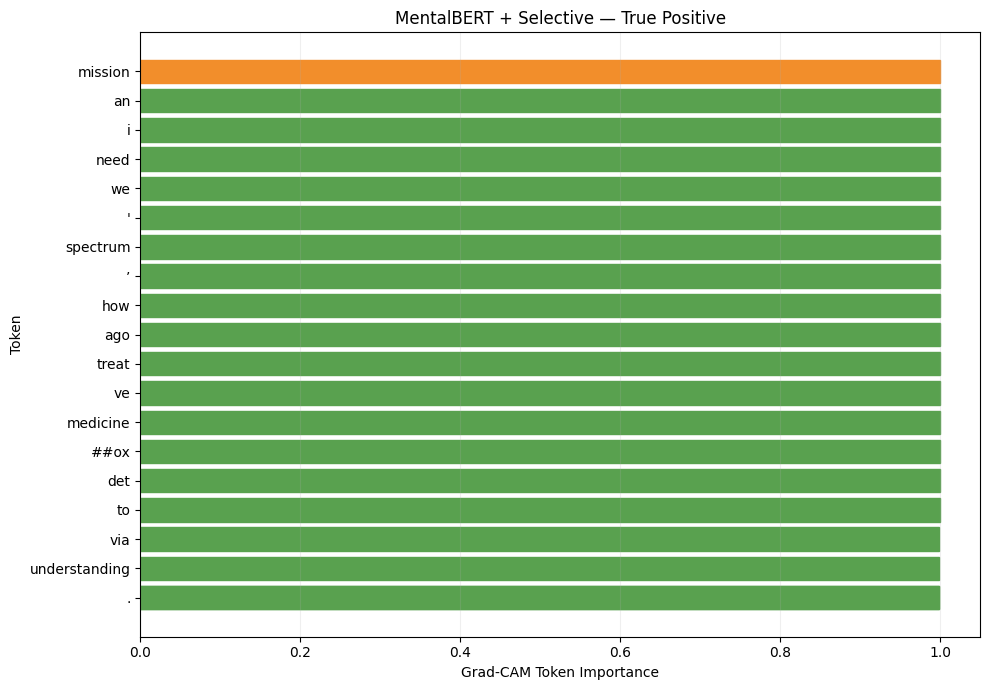

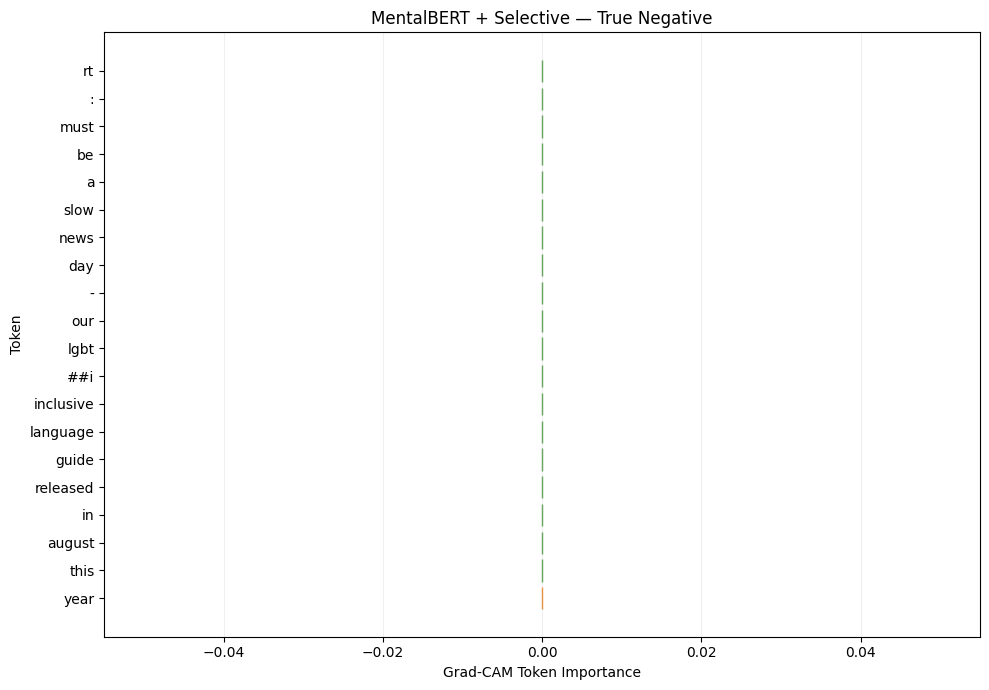

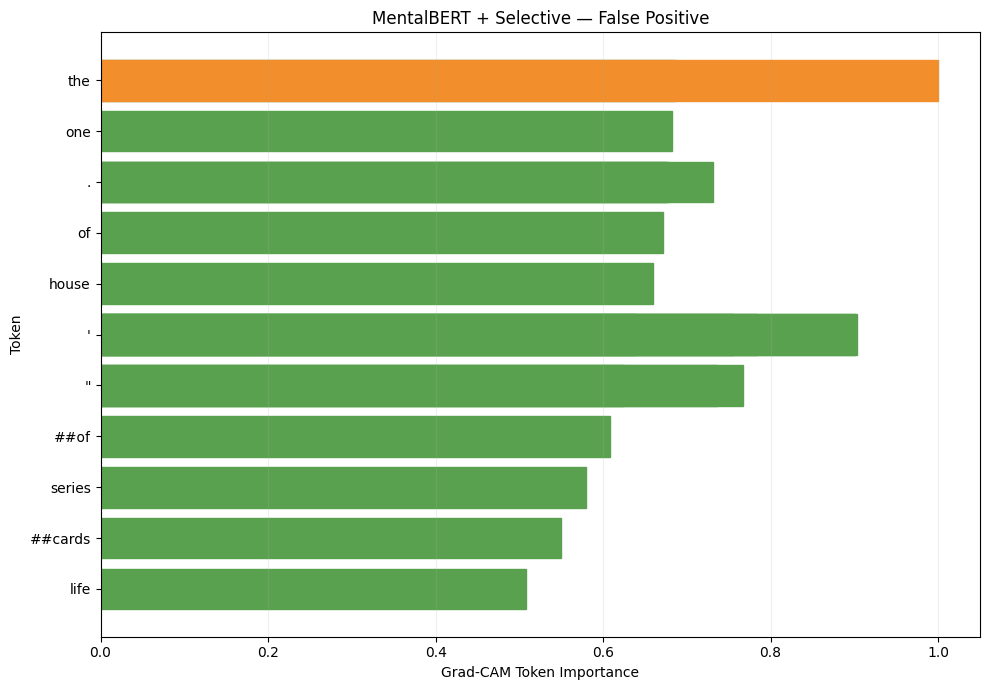

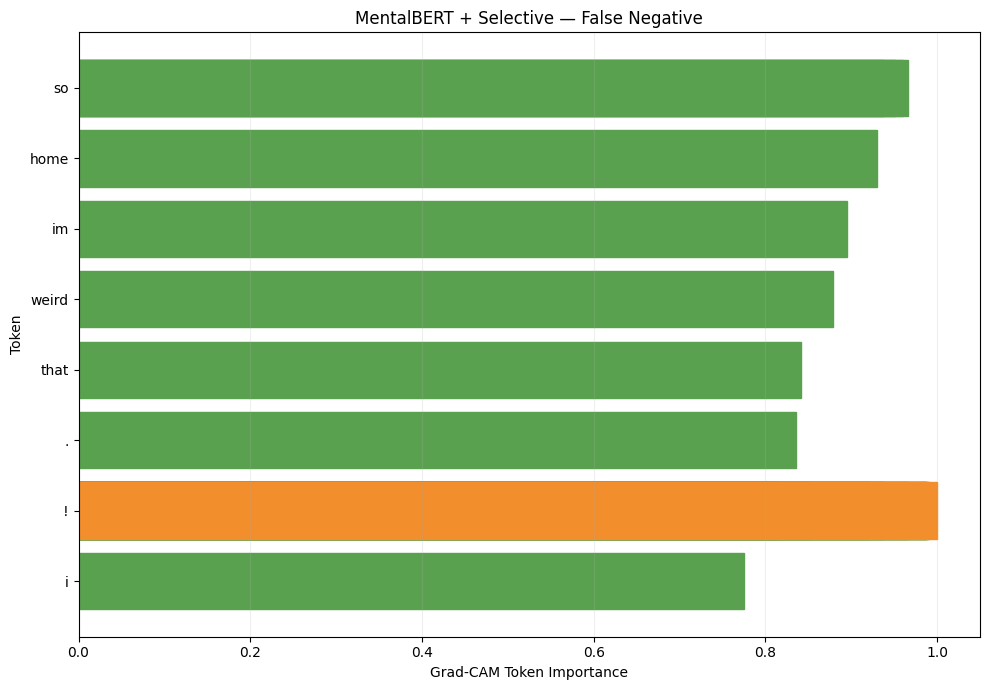


GRAD-CAM ANALYSIS COMPLETE

TP — True: 1 | Predicted: 1 | P(Positive): 0.9959
Top tokens: [('mission', 1.0), ('an', 0.9999954104423523), ('i', 0.9999489188194275), ('need', 0.9998394250869751), ('we', 0.9998309016227722), ("'", 0.9998242855072021), ('spectrum', 0.99979567527771), ('’', 0.9997628927230835), ('how', 0.9997531175613403), ('ago', 0.9997426271438599), ('treat', 0.999695360660553), ('ve', 0.9995222091674805), ('medicine', 0.9994779229164124), ('##ox', 0.9994670748710632), ('det', 0.9994489550590515), ('to', 0.999377429485321), ('via', 0.9993520975112915), ('understanding', 0.9993435144424438), ('.', 0.9993215203285217), ('.', 0.9992966055870056)]

TN — True: 0 | Predicted: 0 | P(Positive): 0.0078
Top tokens: [('rt', 0.0), (':', 0.0), ('must', 0.0), ('be', 0.0), ('a', 0.0), ('slow', 0.0), ('news', 0.0), ('day', 0.0), ('-', 0.0), ('our', 0.0), ('lgbt', 0.0), ('##i', 0.0), ('inclusive', 0.0), ('language', 0.0), ('guide', 0.0), ('released', 0.0), ('in', 0.0), ('august', 0.0), (

In [24]:
# ============================================================
# EXPLAINABILITY — GRAD-CAM
# MENTALBERT + SELECTIVE
# TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("=" * 70)
print("GRAD-CAM ANALYSIS")
print("MENTALBERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED SETTINGS
# ============================================================

GRADCAM_SEED = 42
TOP_TOKENS = 20

np.random.seed(GRADCAM_SEED)
torch.manual_seed(GRADCAM_SEED)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

GRADCAM_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "gradcam"
)

os.makedirs(
    GRADCAM_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model_mental_selective.eval()

for parameter in model_mental_selective.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT Selective model ready")


# ============================================================
# COLLECT TEST PREDICTIONS
# ============================================================

test_true = []
test_pred = []
test_prob = []

with torch.no_grad():

    for batch in test_mental_selective_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model_mental_selective(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        test_true.extend(
            labels.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_pred.extend(
            predictions.detach()
            .cpu()
            .numpy()
            .tolist()
        )

        test_prob.extend(
            probabilities.detach()
            .cpu()
            .numpy()
            .tolist()
        )


test_true = np.asarray(
    test_true
)

test_pred = np.asarray(
    test_pred
)

test_prob = np.asarray(
    test_prob
)

print()
print(
    "Test users:",
    len(test_true)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN CASES
# ============================================================

tp_candidates = np.where(
    (test_true == 1) &
    (test_pred == 1)
)[0]

tn_candidates = np.where(
    (test_true == 0) &
    (test_pred == 0)
)[0]

fp_candidates = np.where(
    (test_true == 0) &
    (test_pred == 1)
)[0]

fn_candidates = np.where(
    (test_true == 1) &
    (test_pred == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(tp_candidates[0]),

    "TN":
        int(tn_candidates[0]),

    "FP":
        int(fp_candidates[0]),

    "FN":
        int(fn_candidates[0])
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {index} | "
        f"True = {test_true[index]} | "
        f"Pred = {test_pred[index]} | "
        f"Positive Probability = {test_prob[index]:.4f}"
    )


# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def compute_gradcam(
    sample_index
):

    sample = test_mental_selective_dataset[
        sample_index
    ]

    input_ids = (
        sample["input_ids"]
        .unsqueeze(0)
        .to(device)
    )

    attention_mask = (
        sample["attention_mask"]
        .unsqueeze(0)
        .to(device)
    )

    metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .to(device)
    )


    # --------------------------------------------------------
    # ENABLE GRADIENTS
    # --------------------------------------------------------

    model_mental_selective.zero_grad(
        set_to_none=True
    )


    # --------------------------------------------------------
    # MENTALBERT ENCODER
    # --------------------------------------------------------

    encoder_output = model_mental_selective.mentalbert(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    hidden_states = (
        encoder_output.last_hidden_state
    )

    # Enable gradients on final hidden states
    # while keeping model weights frozen
    hidden_states.requires_grad_(True)
    hidden_states.retain_grad()


    # --------------------------------------------------------
    # ATTENTION POOLING
    # --------------------------------------------------------

    projected = torch.tanh(
        model_mental_selective.attention_projection(
            hidden_states
        )
    )

    attention_scores = (
        model_mental_selective.attention_score(
            projected
        )
        .squeeze(-1)
    )

    attention_scores = (
        attention_scores.masked_fill(
            attention_mask == 0,
            -1e9
        )
    )

    attention_weights = torch.softmax(
        attention_scores,
        dim=1
    )


    text_representation = torch.sum(
        hidden_states *
        attention_weights.unsqueeze(-1),
        dim=1
    )


    # --------------------------------------------------------
    # METADATA BRANCH
    # --------------------------------------------------------

    metadata_representation = (
        model_mental_selective.metadata_branch(
            metadata
        )
    )


    metadata_gate = torch.sigmoid(
        model_mental_selective.metadata_beta
    )

    gated_metadata = (
        metadata_gate *
        metadata_representation
    )


    # --------------------------------------------------------
    # FUSION
    # --------------------------------------------------------

    fused = torch.cat(
        [
            text_representation,
            gated_metadata
        ],
        dim=1
    )


    # --------------------------------------------------------
    # CLASSIFIER
    # --------------------------------------------------------

    logits = model_mental_selective.classifier(
        fused
    )


    positive_logit = (
        logits[:, 1]
    )

    positive_logit.backward()


    # --------------------------------------------------------
    # GRAD-CAM
    # --------------------------------------------------------

    gradients = hidden_states.grad

    channel_weights = gradients.mean(
        dim=1
    )


    cam = (
        (
            hidden_states *
            channel_weights.unsqueeze(1)
        )
        .sum(dim=2)
        .squeeze(0)
    )


    # ReLU
    cam = torch.relu(
        cam
    )


    # Normalize
    cam = (
        cam /
        (
            cam.max() +
            1e-12
        )
    )


    cam = cam.detach().cpu().numpy()

    tokens = mental_selective_tokenizer.convert_ids_to_tokens(
        input_ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    mask = (
        attention_mask.squeeze(0)
        .detach()
        .cpu()
        .numpy()
        .astype(bool)
    )


    tokens = [
        token
        for token, valid in zip(
            tokens,
            mask
        )
        if valid
    ]

    cam = cam[
        mask
    ]


    # --------------------------------------------------------
    # REMOVE SPECIAL TOKENS
    # --------------------------------------------------------

    valid_pairs = []

    special_tokens = {
        mental_selective_tokenizer.cls_token,
        mental_selective_tokenizer.sep_token,
        mental_selective_tokenizer.pad_token
    }

    for token, importance in zip(
        tokens,
        cam
    ):

        if token in special_tokens:
            continue

        valid_pairs.append(
            (
                token,
                float(importance)
            )
        )


    # --------------------------------------------------------
    # TOP TOKENS
    # --------------------------------------------------------

    valid_pairs = sorted(
        valid_pairs,
        key=lambda x: x[1],
        reverse=True
    )

    top_pairs = valid_pairs[
        :TOP_TOKENS
    ]

    return (
        top_pairs,
        tokens,
        cam,
        int(test_true[sample_index]),
        int(test_pred[sample_index]),
        float(test_prob[sample_index])
    )


# ============================================================
# RUN FOUR CASES
# ============================================================

gradcam_results = {}

print()
print("=" * 70)
print("COMPUTING GRAD-CAM")
print("=" * 70)


for case_name, sample_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(Test Index {sample_index})"
    )

    result = compute_gradcam(
        sample_index
    )

    gradcam_results[
        case_name
    ] = result

    print(
        f"✓ {case_name} complete"
    )


# ============================================================
# SAVE TOKEN IMPORTANCE CSV
# ============================================================

all_rows = []

for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    true_label = result[3]
    predicted_label = result[4]
    positive_probability = result[5]

    for rank, (
        token,
        importance
    ) in enumerate(
        top_pairs,
        start=1
    ):

        all_rows.append({

            "case":
                case_name,

            "rank":
                rank,

            "token":
                token,

            "importance":
                importance,

            "true_label":
                true_label,

            "predicted_label":
                predicted_label,

            "positive_probability":
                positive_probability
        })


gradcam_df = pd.DataFrame(
    all_rows
)

gradcam_csv_path = os.path.join(
    GRADCAM_DIR,
    "mentalbert_selective_gradcam_token_importance.csv"
)

gradcam_df.to_csv(
    gradcam_csv_path,
    index=False
)


# ============================================================
# PLOT FOUR CASES
# ============================================================

case_titles = {

    "TP":
        "True Positive",

    "TN":
        "True Negative",

    "FP":
        "False Positive",

    "FN":
        "False Negative"
}


for case_name, result in gradcam_results.items():

    top_pairs = result[0]

    tokens_plot = [
        pair[0]
        for pair in top_pairs
    ][::-1]

    importance_plot = [
        pair[1]
        for pair in top_pairs
    ][::-1]


    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        tokens_plot,
        importance_plot
    )


    # Highlight highest-importance token
    if len(bars) > 0:

        max_index = int(
            np.argmax(
                importance_plot
            )
        )

        bars[max_index].set_color(
            "#F28E2B"
        )

        for index, bar in enumerate(
            bars
        ):

            if index != max_index:

                bar.set_color(
                    "#59A14F"
                )


    plt.xlabel(
        "Grad-CAM Token Importance"
    )

    plt.ylabel(
        "Token"
    )

    plt.title(
        "MentalBERT + Selective — "
        f"{case_titles[case_name]}"
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()


    plot_path = os.path.join(
        GRADCAM_DIR,
        f"mentalbert_selective_gradcam_{case_name.lower()}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# SAVE CONFIGURATION
# ============================================================

gradcam_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Selective",

    "method":
        "Gradient-weighted Class Activation Mapping",

    "target":
        "Positive/depression-class logit",

    "representation":
        "Final Transformer hidden states",

    "channel_weight":
        "Mean gradient across token positions",

    "activation":
        "ReLU",

    "normalization":
        "Per-user max normalization",

    "top_tokens":
        TOP_TOKENS,

    "seed":
        GRADCAM_SEED,

    "cases":
        selected_cases,

    "test_users":
        len(test_true)

}


with open(
    os.path.join(
        GRADCAM_DIR,
        "mentalbert_selective_gradcam_config.json"
    ),
    "w"
) as f:

    json.dump(
        gradcam_config,
        f,
        indent=2
    )


# ============================================================
# PRINT RESULTS
# ============================================================

print()
print("=" * 70)
print("GRAD-CAM ANALYSIS COMPLETE")
print("=" * 70)

for case_name, result in gradcam_results.items():

    print()
    print(
        f"{case_name} — "
        f"True: {result[3]} | "
        f"Predicted: {result[4]} | "
        f"P(Positive): {result[5]:.4f}"
    )

    print(
        "Top tokens:",
        result[0]
    )

print()
print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Final MentalBERT hidden states used"
)

print(
    "✓ Positive/depression-class logit used"
)

print(
    "✓ Top 20 tokens extracted"
)

print(
    "✓ Token importance CSV saved"
)

print(
    "✓ Four paper-ready plots saved and displayed"
)

print(
    "✓ Configuration saved"
)

print()
print(
    "Grad-CAM output directory:",
    GRADCAM_DIR
)

LIME ANALYSIS
MENTALBERT + SELECTIVE

✓ MentalBERT Selective model ready

Test users: 767

SELECTED CASES
TP: Test Index = 3 | True = 1 | Pred = 1 | Positive Probability = 0.9959
TN: Test Index = 0 | True = 0 | Pred = 0 | Positive Probability = 0.0078
FP: Test Index = 27 | True = 0 | Pred = 1 | Positive Probability = 0.6861
FN: Test Index = 1 | True = 1 | Pred = 0 | Positive Probability = 0.3802

✓ LIME explainer ready

GENERATING LIME EXPLANATIONS

Processing TP (test index 3)...
✓ TP explanation complete

Processing TN (test index 0)...
✓ TN explanation complete

Processing FP (test index 27)...
✓ FP explanation complete

Processing FN (test index 1)...
✓ FN explanation complete

LIME EXPLANATIONS

TP — LIME LOCAL EXPLANATION



TN — LIME LOCAL EXPLANATION



FP — LIME LOCAL EXPLANATION



FN — LIME LOCAL EXPLANATION


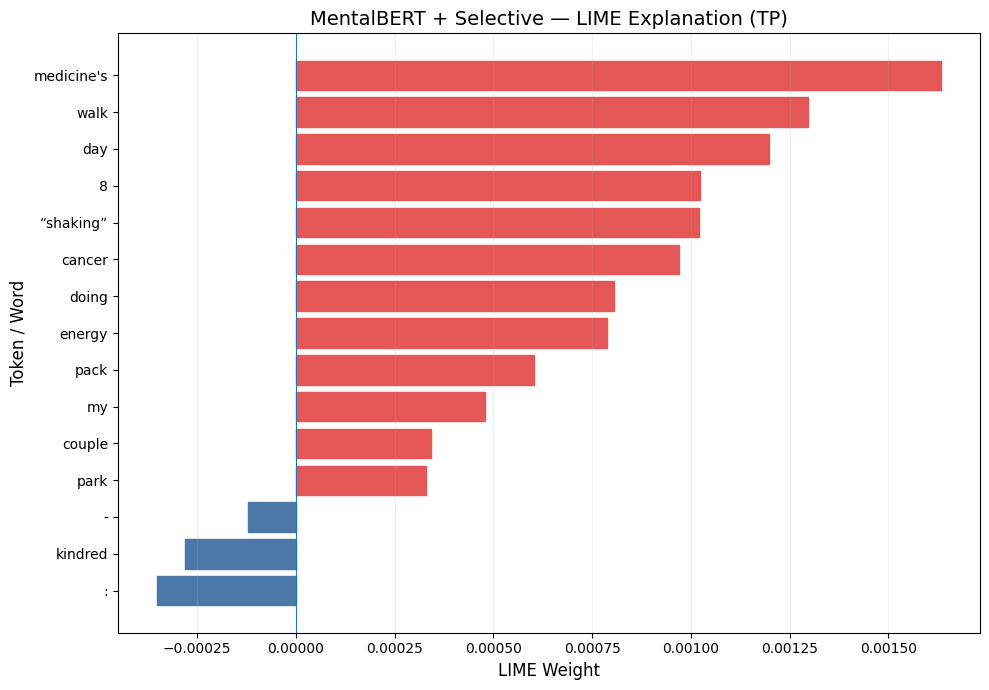

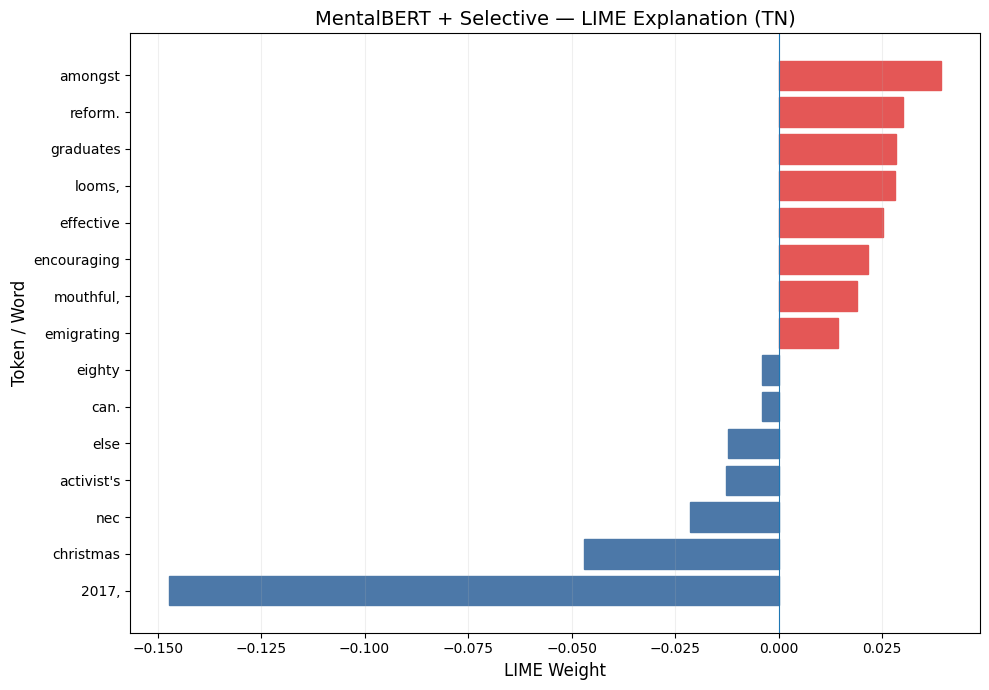

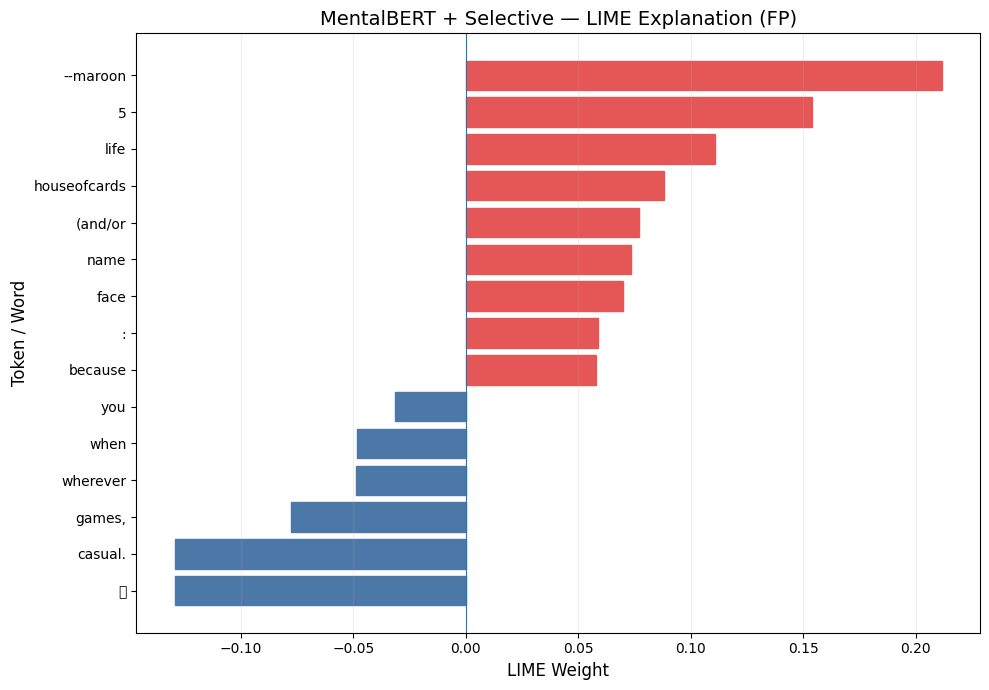

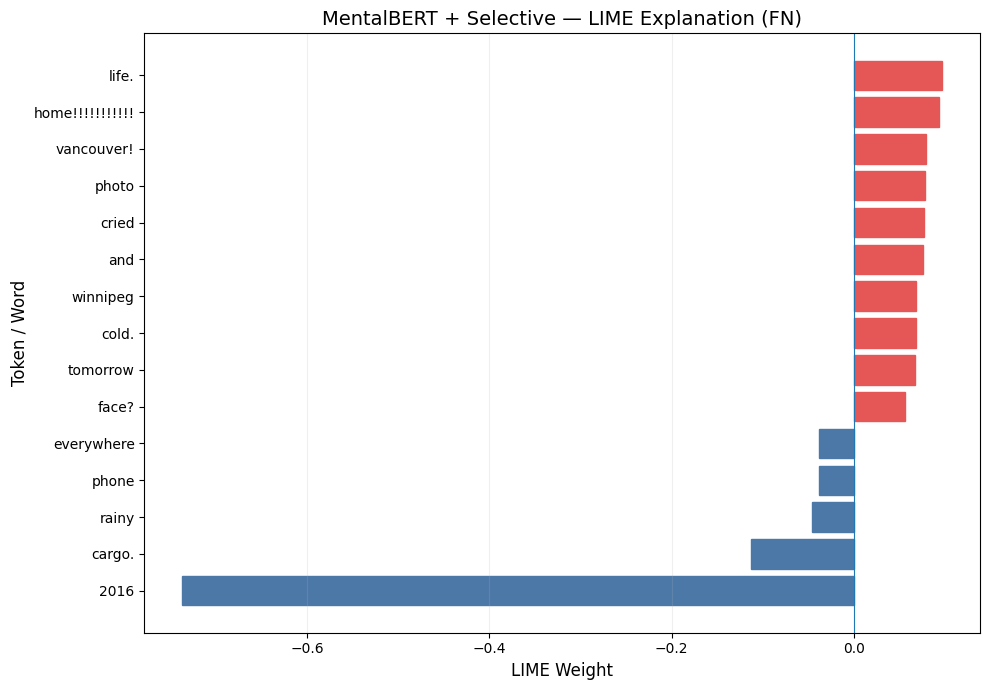


LIME ANALYSIS COMPLETE
✓ TP, TN, FP, FN cases explained
✓ Same trained MentalBERT model used
✓ Metadata held fixed per user
✓ 1000 LIME perturbations per case
✓ Top 15 features extracted
✓ LIME results saved
✓ HTML explanations saved
✓ Paper-ready LIME plots saved and displayed

LIME output directory: /kaggle/working/mentalbert_selective/explainability/lime


In [22]:
# ============================================================
# EXPLAINABILITY — LIME
# MENTALBERT + SELECTIVE
# LOCAL TOKEN-LEVEL EXPLANATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from lime.lime_text import LimeTextExplainer
from IPython.display import display, HTML


print("=" * 70)
print("LIME ANALYSIS")
print("MENTALBERT + SELECTIVE")
print("=" * 70)


# ============================================================
# FIXED LIME SETTINGS
# ============================================================

LIME_SEED = 42
LIME_NUM_FEATURES = 15
LIME_NUM_SAMPLES = 1000
LIME_BATCH_SIZE = 8

np.random.seed(
    LIME_SEED
)

torch.manual_seed(
    LIME_SEED
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

LIME_DIR = os.path.join(
    EXPLAINABILITY_DIR,
    "lime"
)

os.makedirs(
    LIME_DIR,
    exist_ok=True
)


# ============================================================
# MODEL
# ============================================================

model_mental_selective.eval()

for parameter in model_mental_selective.parameters():
    parameter.requires_grad = False

print()
print("✓ MentalBERT Selective model ready")


# ============================================================
# TEST PREDICTIONS
# ============================================================

labels_np = []
preds_np = []
probs_np = []

with torch.no_grad():

    for batch in test_mental_selective_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        metadata = (
            batch["metadata"]
            .to(device)
        )

        labels = (
            batch["labels"]
            .to(device)
        )

        outputs = model_mental_selective(
            input_ids=input_ids,
            attention_mask=attention_mask,
            metadata=metadata
        )

        logits = outputs["logits"]

        probabilities = torch.softmax(
            logits.float(),
            dim=1
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).long()

        labels_np.extend(
            labels.cpu()
            .numpy()
            .tolist()
        )

        preds_np.extend(
            predictions.cpu()
            .numpy()
            .tolist()
        )

        probs_np.extend(
            probabilities.cpu()
            .numpy()
            .tolist()
        )


labels_np = np.asarray(
    labels_np
)

preds_np = np.asarray(
    preds_np
)

probs_np = np.asarray(
    probs_np
)


print()
print(
    "Test users:",
    len(labels_np)
)


# ============================================================
# DETERMINISTIC TP / TN / FP / FN
# ============================================================

tp_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 1)
)[0]

tn_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 0)
)[0]

fp_candidates = np.where(
    (labels_np == 0) &
    (preds_np == 1)
)[0]

fn_candidates = np.where(
    (labels_np == 1) &
    (preds_np == 0)
)[0]


assert len(tp_candidates) > 0
assert len(tn_candidates) > 0
assert len(fp_candidates) > 0
assert len(fn_candidates) > 0


selected_cases = {

    "TP":
        int(
            tp_candidates[0]
        ),

    "TN":
        int(
            tn_candidates[0]
        ),

    "FP":
        int(
            fp_candidates[0]
        ),

    "FN":
        int(
            fn_candidates[0]
        )
}


print()
print("=" * 70)
print("SELECTED CASES")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print(
        f"{case_name}: "
        f"Test Index = {test_index} | "
        f"True = {labels_np[test_index]} | "
        f"Pred = {preds_np[test_index]} | "
        f"Positive Probability = "
        f"{probs_np[test_index]:.4f}"
    )


# ============================================================
# LIME TEXT ACCESS
# ============================================================
# The same cleaned model_text that was used for MentalBERT
# tokenization is used for LIME explanations.
# ============================================================

def get_test_text(
    test_index
):

    return str(
        test_mental_selective_df.iloc[
            int(test_index)
        ]["model_text"]
    )


# ============================================================
# LIME PREDICTOR
# ============================================================
# Text is perturbed by LIME.
# Metadata remains fixed for the explained user.
# ============================================================

def make_lime_predictor(
    test_index
):

    sample = test_mental_selective_dataset[
        int(test_index)
    ]

    fixed_metadata = (
        sample["metadata"]
        .unsqueeze(0)
        .float()
        .to(device)
    )

    def lime_predict(
        texts
    ):

        all_probabilities = []

        for start in range(
            0,
            len(texts),
            LIME_BATCH_SIZE
        ):

            text_batch = texts[
                start:
                start + LIME_BATCH_SIZE
            ]

            encoded = mental_selective_tokenizer(
                text_batch,
                max_length=MAX_LENGTH,
                truncation=True,
                padding="max_length",
                return_attention_mask=True
            )

            input_ids = torch.tensor(
                encoded["input_ids"],
                dtype=torch.long
            ).to(device)

            attention_mask = torch.tensor(
                encoded["attention_mask"],
                dtype=torch.long
            ).to(device)

            metadata_batch = (
                fixed_metadata
                .expand(
                    len(text_batch),
                    -1
                )
            )

            with torch.no_grad():

                outputs = model_mental_selective(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    metadata=metadata_batch
                )

                logits = outputs["logits"]

                probabilities = torch.softmax(
                    logits.float(),
                    dim=1
                )

            all_probabilities.append(
                probabilities
                .cpu()
                .numpy()
            )

            del input_ids
            del attention_mask
            del metadata_batch
            del outputs
            del logits
            del probabilities

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        return np.vstack(
            all_probabilities
        )

    return lime_predict


# ============================================================
# LIME EXPLAINER
# ============================================================

explainer = LimeTextExplainer(
    class_names=[
        "Negative",
        "Positive"
    ],
    split_expression=r"\s+",
    random_state=LIME_SEED
)

print()
print("✓ LIME explainer ready")


# ============================================================
# RUN LIME FOR FOUR CASES
# ============================================================

all_explanations = {}

print()
print("=" * 70)
print("GENERATING LIME EXPLANATIONS")
print("=" * 70)

for case_name, test_index in selected_cases.items():

    print()
    print(
        f"Processing {case_name} "
        f"(test index {test_index})..."
    )

    text = get_test_text(
        test_index
    )

    predictor = make_lime_predictor(
        test_index
    )

    explanation = explainer.explain_instance(
        text,
        predictor,
        labels=(1,),
        num_features=LIME_NUM_FEATURES,
        num_samples=LIME_NUM_SAMPLES
    )

    all_explanations[
        case_name
    ] = explanation

    print(
        f"✓ {case_name} explanation complete"
    )


# ============================================================
# SAVE LIME RESULTS
# ============================================================

all_lime_rows = []

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    for rank, (
        word,
        weight
    ) in enumerate(
        explanation_list,
        start=1
    ):

        all_lime_rows.append({

            "case":
                case_name,

            "test_index":
                selected_cases[
                    case_name
                ],

            "true_label":
                int(
                    labels_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "predicted_label":
                int(
                    preds_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "positive_probability":
                float(
                    probs_np[
                        selected_cases[
                            case_name
                        ]
                    ]
                ),

            "rank":
                rank,

            "word":
                word,

            "lime_weight":
                float(weight)

        })


lime_results_df = pd.DataFrame(
    all_lime_rows
)

lime_csv_path = os.path.join(
    LIME_DIR,
    "mentalbert_selective_lime_results.csv"
)

lime_results_df.to_csv(
    lime_csv_path,
    index=False
)


# ============================================================
# DISPLAY + SAVE HTML
# ============================================================

print()
print("=" * 70)
print("LIME EXPLANATIONS")
print("=" * 70)

for case_name, explanation in all_explanations.items():

    print()
    print(
        "=" * 60
    )

    print(
        f"{case_name} — "
        f"LIME LOCAL EXPLANATION"
    )

    print(
        "=" * 60
    )

    display(
        HTML(
            explanation.as_html(
                labels=[1]
            )
        )
    )

    html_path = os.path.join(
        LIME_DIR,
        f"mentalbert_selective_lime_{case_name}.html"
    )

    with open(
        html_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(
            explanation.as_html(
                labels=[1]
            )
        )


# ============================================================
# PAPER-FRIENDLY LIME BAR PLOTS
# ============================================================

for case_name, explanation in all_explanations.items():

    explanation_list = explanation.as_list(
        label=1
    )

    plot_df = pd.DataFrame(
        explanation_list,
        columns=[
            "word",
            "weight"
        ]
    )

    plot_df = plot_df.sort_values(
        "weight"
    )

    plt.figure(
        figsize=(10, 7)
    )

    bars = plt.barh(
        plot_df["word"],
        plot_df["weight"]
    )

    # Positive contribution
    for bar, weight in zip(
        bars,
        plot_df["weight"]
    ):

        if weight > 0:
            bar.set_color(
                "#E45756"
            )
        else:
            bar.set_color(
                "#4C78A8"
            )

    plt.axvline(
        0,
        linewidth=0.8
    )

    plt.xlabel(
        "LIME Weight",
        fontsize=12
    )

    plt.ylabel(
        "Token / Word",
        fontsize=12
    )

    plt.title(
        f"MentalBERT + Selective — "
        f"LIME Explanation ({case_name})",
        fontsize=14
    )

    plt.grid(
        axis="x",
        alpha=0.20
    )

    plt.tight_layout()

    plot_path = os.path.join(
        LIME_DIR,
        f"mentalbert_selective_lime_{case_name}.png"
    )

    plt.savefig(
        plot_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ============================================================
# SAVE CASE INFORMATION
# ============================================================

case_info_rows = []

for case_name, test_index in selected_cases.items():

    case_info_rows.append({

        "case":
            case_name,

        "test_index":
            int(test_index),

        "true_label":
            int(
                labels_np[
                    test_index
                ]
            ),

        "predicted_label":
            int(
                preds_np[
                    test_index
                ]
            ),

        "positive_probability":
            float(
                probs_np[
                    test_index
                ]
            ),

        "text_length_characters":
            len(
                get_test_text(
                    test_index
                )
            )

    })


case_info_df = pd.DataFrame(
    case_info_rows
)

case_info_df.to_csv(
    os.path.join(
        LIME_DIR,
        "mentalbert_selective_lime_case_information.csv"
    ),
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

lime_config = {

    "model":
        "MentalBERT",

    "cleaning":
        "Selective",

    "dataset":
        "Held-out test set",

    "target":
        "Positive/depression class",

    "representative_cases":
        [
            "TP",
            "TN",
            "FP",
            "FN"
        ],

    "case_selection":
        "First matching test example in fixed test order",

    "random_seed":
        LIME_SEED,

    "num_samples":
        LIME_NUM_SAMPLES,

    "num_features":
        LIME_NUM_FEATURES,

    "batch_size":
        LIME_BATCH_SIZE,

    "metadata":
        "Fixed for each explained user",

    "text_perturbation":
        "LIME word-level perturbations",

    "model_training":
        "No additional training"
}


with open(
    os.path.join(
        LIME_DIR,
        "mentalbert_selective_lime_config.json"
    ),
    "w"
) as f:

    json.dump(
        lime_config,
        f,
        indent=2
    )


# ============================================================
# COMPLETE
# ============================================================

print()
print("=" * 70)
print("LIME ANALYSIS COMPLETE")
print("=" * 70)

print(
    "✓ TP, TN, FP, FN cases explained"
)

print(
    "✓ Same trained MentalBERT model used"
)

print(
    "✓ Metadata held fixed per user"
)

print(
    "✓ 1000 LIME perturbations per case"
)

print(
    "✓ Top 15 features extracted"
)

print(
    "✓ LIME results saved"
)

print(
    "✓ HTML explanations saved"
)

print(
    "✓ Paper-ready LIME plots saved and displayed"
)

print()
print(
    "LIME output directory:",
    LIME_DIR
)